# Statistical Analysis and Time-Series Investigation of S&P 500 Stock Performance, 2014–2017

**AnalystLab Africa Experience Lab · Week 6 · Track B: Data Science**
**Author:** Molemi Molokoane

**Data:** `S&P 500 Stock Prices 2014-2017.csv`, supplied by AnalystLab Africa: 497,472 daily records (open, high, low, close, volume) for 505 symbols over 1,007 trading days, 2 January 2014 to 29 December 2017.

> **Historical data only.** Every figure in this notebook describes 2014 to 2017. Nothing here is a statement about current prices, and no historical return or model output is a forecast or an investment recommendation.

### Contents
0. Research problem, stock selection and success criteria
1. Setup and data integrity
2. Dataset inspection and preparation
3. Exploratory data analysis
4. Descriptive statistics
5. Hypothesis testing
6. Time-series analysis
7. Correlation analysis
8. Validation
9. Limitations
10. Findings, recommendations and answers to the brief's questions

## 0. Research problem, stock selection and success criteria

### 0.1 The business problem
Analysts at the simulated research organisation need to know how individual stocks behaved over 2014 to 2017: which earned more, which were riskier, how trading activity relates to price moves and how far stocks move together. Raw prices cannot answer this. A \$1,000 share is not a better investment than a \$50 one, and the file has data problems that distort naive calculations (missing values, gaps in histories, unadjusted spin-offs and some wrong prices). The **intended users** are financial researchers and analysts who want evidence-based answers, plus the other Week 6 tracks (dashboard, prediction model, AI assistant), which need validated definitions and figures.

### 0.2 Primary research problem
> **How did return, risk and trading activity differ across six large S&P 500 stocks from six different sectors in 2014–2017, how much of their daily behaviour was shared with the rest of the market, and did their history contain any pattern (seasonal or serial) that would help estimate the next day's return?**

**Supporting research questions**

| # | Question | Main method |
|---|---|---|
| RQ1 | Were the stocks' mean daily returns different from zero? | One-sample t-test with HAC (Newey-West) errors, Wilcoxon, block bootstrap |
| RQ2 | Do the stocks differ in their return distributions, in average level or in spread (volatility)? | Friedman and Kruskal-Wallis (level); Brown-Forsythe and paired tests on absolute deviations (spread) |
| RQ3 | Is trading volume related to daily returns, to their direction or to their size? | Spearman correlation with effective sample size |
| RQ4 | How strongly do the stocks' daily returns move together and with the market? | Spearman and Pearson correlation, rolling correlation, beta |
| RQ5 | Is there stable seasonality, autocorrelation or volatility clustering, and can past returns estimate the next day's return better than "no change"? | STL decomposition, ACF/PACF, Ljung-Box, ARCH-LM, walk-forward forecasts, Diebold-Mariano |

**Why it matters:** comparing performance fairly (percentage returns, not prices), knowing which differences are statistically supported and which are noise, and knowing how much diversification six "different" stocks really give are basic inputs to portfolio research, risk reporting and model design.

**Variables required:** `symbol`, `date`, `close` (for returns, trends and volatility), `volume` (activity), `open`/`high`/`low` (data checks and daily range). Derived: daily percentage return, log return, price change, daily range, moving averages, rolling volatility, relative volume and an equal-weighted market average of all symbols.

**Expected outcomes:** a validated cleaned dataset; descriptive statistics; tested hypotheses with effect sizes; time-series diagnostics; correlation results; and an independently checked table of key figures that the dashboard and AI-assistant tracks can reuse.

### 0.3 Why these six stocks
**AAPL** (Apple, information technology), **AMZN** (Amazon, consumer discretionary), **JPM** (JPMorgan Chase, financials), **JNJ** (Johnson & Johnson, health care), **XOM** (Exxon Mobil, energy) and **WMT** (Walmart, consumer staples). They are large, heavily traded companies from six different sectors (sector labels are general knowledge, not in the file). Each has a **complete 1,007-day history with no flagged record** (checked in Section 3.1), so they can be compared on identical dates without filling gaps. They also cover a wide range of outcomes, from a stock that nearly tripled to one that fell. The whole file (505 symbols) is used for the market-wide questions and for an equal-weighted market average.

### 0.4 Success criteria (measurable)
1. **Reconciliation:** every key figure (≥ 100 of them) matches an independent recalculation that uses only the Python standard library (`validation/independent_check.py`), with relative tolerance 10⁻⁶.
2. **Statistical rigour:** each hypothesis states H₀ and H₁, justifies its test, reports the statistic, p-value and an effect size or interval at α = 0.05, corrects for multiple testing (Holm) and allows for serial dependence where it matters.
3. **Data quality:** every data-quality issue in the brief is independently confirmed or corrected, and every cleaning decision is logged (`Outputs/cleaning_log.csv`); the raw file's SHA-256 hash is unchanged after the run.
4. **Tested code:** the preparation and statistics helpers pass their unit tests (`tests/`), and the notebook stops if any validation fails.
5. **Predictive check:** any forecast is evaluated out of sample (chronological split, no shuffling) against a no-change baseline.

## 1. Setup and data integrity
All cleaning rules and statistical helpers live in `stock_prep.py` (unit-tested), and all chart styling in `charts.py`. The raw file is checked against its SHA-256 hash so the analysis cannot run on a modified copy.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning

import stock_prep as sp
import charts as ch

warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message="The kopts argument")
warnings.filterwarnings("ignore", message="divide by zero")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

OUT = Path("Outputs"); OUT.mkdir(exist_ok=True)
sp.CLEAN_DIR.mkdir(parents=True, exist_ok=True)
S = sp.SELECTED
ALPHA = 0.05
SEED = 2017

import scipy, plotly, sys
print(f"Python {sys.version.split()[0]} · pandas {pd.__version__} · NumPy {np.__version__} · SciPy {scipy.__version__} · "
      f"statsmodels {statsmodels.__version__} · Plotly {plotly.__version__}")

digest = sp.sha256(sp.RAW_PATH)
assert digest == sp.RAW_SHA256, f"Raw file has changed: {digest}"
print("Raw file SHA-256 verified:", digest)

Python 3.14.4 · pandas 3.1.1 · NumPy 2.5.5 · SciPy 1.18.1 · statsmodels 0.15.0 · Plotly 7.1.0
Raw file SHA-256 verified: cd73b2fa92f476056c67a1c9543dc1a2050de5a5dc862de31dff8da3c67d4496


## 2. Dataset inspection and preparation

### 2.1 Structure, columns and data types

In [2]:
raw = sp.load_raw()
print(f"{len(raw):,} rows × {raw.shape[1]} columns")
display(raw.head())
info = pd.DataFrame({"dtype": raw.dtypes.astype(str), "non_null": raw.notna().sum(), "missing": raw.isna().sum(),
                     "example": raw.iloc[0]})
info["meaning"] = ["Stock ticker", "Trading date (text, month/day/year)", "Opening price", "Highest price in the day",
                   "Lowest price in the day", "Closing price", "Shares traded (a count, not a money value)"]
display(info)

497,472 rows × 7 columns


,symbol,date,open,high,low,close,volume
0,AAL,1/2/2014,25.0700,25.8200,25.0600,25.3600,8998943
1,AAPL,1/2/2014,79.3828,79.5756,78.8601,79.0185,58791957
2,AAP,1/2/2014,110.3600,111.8800,109.2900,109.7400,542711
3,ABBV,1/2/2014,52.1200,52.3300,51.5200,51.9800,4569061
4,ABC,1/2/2014,70.1100,70.2300,69.4800,69.8900,1148391


,dtype,non_null,missing,example,meaning
symbol,str,497472,0,AAL,Stock ticker
date,str,497472,0,1/2/2014,"Trading date (text, month/day/year)"
open,float64,497461,11,25.0700,Opening price
high,float64,497464,8,25.8200,Highest price in the day
low,float64,497464,8,25.0600,Lowest price in the day
close,float64,497472,0,25.3600,Closing price
volume,int64,497472,0,8998943,"Shares traded (a count, not a money value)"


`date` is read as text, so it is parsed with the explicit format `%m/%d/%Y`: guessing could read 1/2/2014 as 1 February. Prices are floats and volume is an integer. The file starts with a byte-order mark, so it is read as `utf-8-sig` (otherwise the first column would be named `﻿symbol`).

In [3]:
dates = sp.parse_dates(raw["date"])
calendar = sp.trading_calendar(dates)
weekday_counts = pd.Series(calendar.day_name()).value_counts()
summary = {
    "rows": len(raw), "columns": raw.shape[1], "symbols": raw["symbol"].nunique(),
    "trading_dates": len(calendar), "first_date": calendar[0].date(), "last_date": calendar[-1].date(),
    "weekend_dates": int((calendar.day_of_week >= 5).sum()),
    "rows_per_date_min": int(dates.value_counts().min()), "rows_per_date_max": int(dates.value_counts().max()),
}
display(pd.Series(summary, name="value").to_frame())
print("Trading dates by weekday:", weekday_counts.to_dict())
print("Trading dates per year:", pd.Series(calendar.year).value_counts().sort_index().to_dict())

,value
rows,497472
columns,7
symbols,505
trading_dates,1007
first_date,2014-01-02
last_date,2017-12-29
weekend_dates,0
rows_per_date_min,482
rows_per_date_max,505


Trading dates by weekday: {'Wednesday': 208, 'Tuesday': 207, 'Thursday': 203, 'Friday': 201, 'Monday': 188}
Trading dates per year: {2014: 252, 2015: 252, 2016: 252, 2017: 251}


The brief's overview is confirmed: 497,472 records, 7 columns, 505 symbols and 1,007 distinct trading dates from 2 January 2014 to 29 December 2017, with no weekend dates. Between 482 and 505 symbols trade on any date, so histories are uneven (Section 2.4).

### 2.2 Missing values, duplicates and zero volume

In [4]:
missing = raw.isna().sum().rename("missing").to_frame()
missing["pct"] = 100 * missing["missing"] / len(raw)
display(missing.T)

dups_exact = int(raw.duplicated().sum())
dups_key = int(raw.duplicated(["symbol", "date"]).sum())
print(f"Exact duplicate rows: {dups_exact}; duplicate symbol-date combinations: {dups_key}")

miss_rows = raw[raw[["open", "high", "low"]].isna().any(axis=1)].copy()
display(miss_rows)
print("Rows with volume == 0:", int((raw["volume"] == 0).sum()), "· rows with volume <= 100:", int((raw["volume"] <= 100).sum()))

,symbol,date,open,high,low,close,volume
missing,0.0000,0.0000,11.0000,8.0000,8.0000,0.0000,0.0000
pct,0.0000,0.0000,0.0022,0.0016,0.0016,0.0000,0.0000


Exact duplicate rows: 0; duplicate symbol-date combinations: 0


,symbol,date,open,high,low,close,volume
166348,VRTX,5/12/2015,NaN,NaN,NaN,124.0800,569747
175557,REGN,6/9/2015,NaN,NaN,NaN,526.0900,12135
182011,WRK,6/26/2015,NaN,NaN,NaN,61.9000,100
188547,DHR,7/17/2015,NaN,88.7600,88.2400,88.7200,2056819
188578,ES,7/17/2015,NaN,48.4900,47.8500,47.9200,1246786
188760,O,7/17/2015,NaN,47.3100,46.8300,46.9900,1229513
249223,DHR,1/12/2016,NaN,NaN,NaN,88.5500,0
249438,O,1/12/2016,NaN,NaN,NaN,52.4300,0
278801,UA,4/7/2016,NaN,NaN,NaN,41.5600,0
308365,FTV,7/1/2016,NaN,NaN,NaN,49.5400,0


Rows with volume == 0: 4 · rows with volume <= 100: 6


**Confirmed:** 11 missing `open`, 8 missing `high`, 8 missing `low`, no missing `close` or `volume`, no duplicate symbol-date combinations, and 4 zero-volume records. Two further findings:

* The missing values sit on **11 rows**: 3 rows (DHR, ES and O on 17 July 2015) miss only `open`; **8 rows miss all three of open, high and low**.
* Of those 8, the 4 zero-volume rows (DHR and O on 12 January 2016, UA on 7 April 2016, FTV on 1 July 2016) and 2 more with near-zero volume (WRK on 26 June 2015 with 100 shares, BHF on 26 July 2017 with 3 shares) are **not normal trading records** for S&P 500 companies, which trade millions of shares a day. They appear to be placeholder rows: two fall on a stock's first day in the file (FTV, UA) and the others around corporate events.

**Treatment (no imputation, no zeros):** missing open/high/low stay missing and those rows are left out of daily-range statistics only. `close` is present on every row, so returns are unaffected. On the 6 placeholder rows (`no_trade`), volume is treated as missing rather than as a real zero.

### 2.3 Price consistency, extreme values and adjustment for splits

In [5]:
df = sp.prepare(raw)   # sorted by symbol and date, with flags and derived fields (see stock_prep.prepare)
assert df["date"].equals(df.sort_values(["symbol", "date"])["date"]) and df.groupby("symbol")["date"].is_monotonic_increasing.all()
print("Raw file order is by date, then symbol; after preparation every symbol is in date order:",
      bool(df.groupby("symbol")["date"].is_monotonic_increasing.all()))
print("Non-positive prices:", int((raw[sp.PRICE_COLUMNS] <= 0).sum().sum()), "· negative volume:", int((raw["volume"] < 0).sum()))

bad = df[df["ohlc_inconsistent"]][["symbol", "date", "open", "high", "low", "close", "volume", "pct_return"]]
print(f"\n{len(bad)} rows where open/high/low/close contradict each other (high below another price, or low above one):")
display(bad)

Raw file order is by date, then symbol; after preparation every symbol is in date order: True
Non-positive prices: 0 · negative volume: 0

12 rows where open/high/low/close contradict each other (high below another price, or low above one):


,symbol,date,open,high,low,close,volume,pct_return
43395,AOS,2014-05-19,23.8900,23.5950,23.8500,24.4450,1944854,0.0222
63004,BBY,2016-03-14,33.5500,33.7500,33.0800,32.7200,6037794,-0.0410
91809,CHD,2014-05-19,18.7700,33.9525,33.6950,33.8950,1078888,0.0007
92845,CHK,2014-06-30,30.4300,31.1000,30.3700,29.3900,8132836,-0.0332
133750,DHR,2014-11-06,78.4700,81.3050,80.4900,81.2600,1614419,0.0061
242487,IP,2014-07-01,50.8500,51.0700,50.5700,50.0900,5624981,-0.0075
281857,LNT,2016-05-19,35.1900,35.7850,35.0850,17.8700,1231722,-0.4945
343781,O,2014-08-27,44.6750,44.7000,44.6600,44.5272,185518,-0.0052
343831,O,2014-11-06,44.7400,47.5700,46.7300,46.8600,1803132,-0.0087
413567,SPG,2014-05-28,176.2300,176.6000,174.5000,165.4200,1383759,-0.0630


Twelve rows have internally inconsistent prices (for example CHD on 19 May 2014 with an open of 18.77 against a low of 33.70). Most are single wrong open, high or low values. In three cases the **close** is outside the day's range, and the neighbouring days explain why:

* **SPG, 28 May 2014:** the close (165.42) is below the low (174.50), and the price stays near 165 afterwards. This is the date of the Washington Prime spin-off: the close is the new, post-distribution price, while open, high and low were not updated.
* **WRK, 13 May 2016:** similar, with the close holding near 38 to 39 afterwards.
* **LNT, 19 May 2016:** the close of 17.87 is half the surrounding prices (35.35 the day before, 35.91 the day after). This is one close that was **not adjusted for Alliant Energy's 2-for-1 split**, while the rest of the series was. It is a recording error.

**Treatment:** the 12 rows are flagged (`ohlc_inconsistent`) and their daily range is set to missing. Their closes are kept unless the spike rule below identifies them as errors.

In [6]:
spikes = df[df["price_error"]][["symbol", "date", "prev_close", "close", "pct_return"]].copy()
spikes["next_close"] = [df.loc[i + 1, "close"] for i in spikes.index]
spikes["next_return"] = [df.loc[i + 1, "pct_return"] for i in spikes.index]
print(f"Single closing prices flagged as probable errors (move of at least {sp.SPIKE_MIN_MOVE:.0%} that is undone "
      f"to within {sp.SPIKE_MAX_NET:.0%} the next day):")
display(spikes)

big = df[df["pct_return"].abs() >= 0.25].copy()
big["flag"] = np.select([big["price_error"], big["corporate_action"],
                         big.index.isin(spikes.index + 1)],
                        ["probable price error", "corporate action (spin-off/distribution)", "reversal of a price error"],
                        "kept: unexplained by the data, treated as a real move")
print(f"\nAll {len(big)} one-day moves of 25% or more:")
display(big[["symbol", "date", "prev_close", "close", "pct_return", "flag"]].sort_values("date"))

Single closing prices flagged as probable errors (move of at least 20% that is undone to within 5% the next day):


,symbol,date,prev_close,close,pct_return,next_close,next_return
187354,FLR,2017-09-14,40.1400,50.6200,0.2611,40.4300,-0.2013
281857,LNT,2016-05-19,35.3500,17.8700,-0.4945,35.9100,1.0095
312400,MPC,2017-09-14,53.2100,64.7500,0.2169,52.9600,-0.1821
314414,MRO,2017-09-14,11.9100,16.0200,0.3451,12.0000,-0.2509
341530,NWL,2017-09-14,44.2200,30.8100,-0.3033,43.2000,0.4021



All 39 one-day moves of 25% or more:


,symbol,date,prev_close,close,pct_return,flag
62462,BBY,2014-01-16,37.5700,26.8300,-0.2859,"kept: unexplained by the data, treated as a re..."
468257,VRTX,2014-06-24,66.6100,93.5300,0.4041,"kept: unexplained by the data, treated as a re..."
135689,DISCA,2014-08-07,83.0200,40.9750,-0.5064,corporate action (spin-off/distribution)
136696,DISCK,2014-08-07,81.2200,39.7800,-0.5102,corporate action (spin-off/distribution)
307596,MNST,2014-08-15,23.8833,31.1633,0.3048,"kept: unexplained by the data, treated as a re..."
211,A,2014-11-03,55.2800,40.8400,-0.2612,corporate action (spin-off/distribution)
479079,WMB,2015-06-22,48.3400,60.8600,0.2590,"kept: unexplained by the data, treated as a re..."
60814,BAX,2015-07-01,69.9300,38.8600,-0.4443,corporate action (spin-off/distribution)
329898,NI,2015-07-02,45.4500,16.9900,-0.6262,corporate action (spin-off/distribution)
150297,EBAY,2015-07-20,66.2900,28.5700,-0.5690,corporate action (spin-off/distribution)


**Extreme price observations.** Moves of 25% or more fall into three groups:

1. **Probable price errors (5 closes).** Four symbols (FLR, MPC, MRO, NWL) jump 20% to 35% on **14 September 2017** and return to their previous level the next day, which points to a problem in the data source on that date. The fifth is the LNT split error. The rule flags a close when the move into it is at least 20% and the next day undoes it to within 5%. A real move of that size that reverses completely within a day is very rare for a large company. The returns into and out of these closes are excluded.
2. **Corporate actions (12 returns).** Large falls on the dates of publicly announced spin-offs and distributions (eBay/PayPal, Baxter/Baxalta, NiSource/Columbia Pipeline and others listed in `stock_prep.CORPORATE_ACTIONS`). Holders received shares in the new company, so these are **not losses**, and the file does not adjust for them. The list comes from public company announcements and cannot be verified from the file, so it is used only to exclude these returns from market-wide figures. None of the six selected stocks is affected.
3. **Other large moves** (for example AMD +52% on 22 April 2016, CHK −33% on 8 February 2016). Nothing in the data marks them as errors, so they are **kept as real moves**. Their causes cannot be verified from this dataset.

In [7]:
known_splits = pd.DataFrame([
    ("AAPL", "2014-06-09", "7-for-1"), ("MA", "2014-01-22", "10-for-1"), ("GOOGL", "2014-04-03", "Class C share dividend (2-for-1)"),
    ("UNP", "2014-06-09", "2-for-1"), ("V", "2015-03-19", "4-for-1"), ("SBUX", "2015-04-09", "2-for-1"),
    ("NFLX", "2015-07-15", "7-for-1"), ("NKE", "2015-12-24", "2-for-1"), ("MNST", "2016-11-10", "3-for-1"),
], columns=["symbol", "split_date", "split"])
known_splits["split_date"] = pd.to_datetime(known_splits["split_date"])
rows = []
for _, k in known_splits.iterrows():
    s = df[df["symbol"] == k["symbol"]].set_index("date")
    before = s.loc[:k["split_date"] - pd.Timedelta(days=1), "close"].iloc[-1]
    on = s.loc[k["split_date"]:, ["close", "pct_return"]].iloc[0]
    rows.append({**k.to_dict(), "close_before": before, "close_on_split_date": on["close"], "return_on_split_date": on["pct_return"]})
split_check = pd.DataFrame(rows)
display(split_check)
split_check.to_csv(OUT / "split_adjustment_check.csv", index=False)
aapl0 = df[(df.symbol == "AAPL")].iloc[0]
print(f"AAPL first close in file: {aapl0.close:.4f} on {aapl0.date.date()}; Apple's published close that day was $553.13 "
      f"before the 7-for-1 split, and 553.13 / 7 = {553.13 / 7:.4f}")

,symbol,split_date,split,close_before,close_on_split_date,return_on_split_date
0,AAPL,2014-06-09,7-for-1,92.2242,93.7000,0.0160
1,MA,2014-01-22,10-for-1,81.8480,83.3000,0.0177
2,GOOGL,2014-04-03,Class C share dividend (2-for-1),568.1176,571.5000,0.0060
3,UNP,2014-06-09,2-for-1,100.9300,102.1400,0.0120
4,V,2015-03-19,4-for-1,66.9175,66.8100,-0.0016
5,SBUX,2015-04-09,2-for-1,47.6150,47.9600,0.0072
6,NFLX,2015-07-15,7-for-1,100.3713,98.1300,-0.0223
7,NKE,2015-12-24,2-for-1,64.3550,63.1800,-0.0183
8,MNST,2016-11-10,3-for-1,44.1966,42.3300,-0.0422


AAPL first close in file: 79.0185 on 2014-01-02; Apple's published close that day was $553.13 before the 7-for-1 split, and 553.13 / 7 = 79.0186


**Are prices adjusted?** The brief warns not to assume adjustment, so this was tested. Across nine well-known splits from 2014 to 2017, the close moves by no more than an ordinary day's amount on the split date. Unadjusted prices would drop by 50% to 90%. (NFLX's +18% on 16 July 2015 is the day after its split date and is not a split ratio.) AAPL's first close, 79.0185, equals Apple's published pre-split close of \$553.13 divided by 7. Volume is scaled the same way: 58.8 million shares, about 7 times the pre-split volume.

**Conclusion:** the prices are **split-adjusted but not adjusted for dividends or spin-offs**. Splits therefore need no correction. All returns here are **price returns**, which leave out dividends. This understates total return for dividend payers: over four years the gap would be roughly 8% to 14% for JNJ, XOM, WMT and JPM, which paid yields of about 2% to 4% (general knowledge, not from the file).

**Currency:** the file has no currency column, and the source documentation was not supplied. All 505 symbols are US-listed S&P 500 stocks, and the AAPL check above matches its US-dollar price, so prices are **assumed to be US dollars**. No conclusion here depends on currency, because comparisons use percentage returns.

### 2.4 Incomplete stock histories

In [8]:
cov = sp.history_coverage(df, calendar)
cov.to_csv(OUT / "history_coverage.csv")
print(f"Complete histories (all {len(calendar)} dates): {int(cov.complete.sum())} of {len(cov)} symbols; incomplete: {int((~cov.complete).sum())}")
inc = cov[~cov.complete].sort_values("n_records")
inc["pattern"] = np.select([inc.starts_late & ~inc.ends_early, ~inc.starts_late & inc.ends_early, inc.missing_inside > 0],
                           ["starts late (added or listed later)", "ends early", "gaps inside history"], "starts late and ends early")
display(inc[["n_records", "first_date", "last_date", "missing_inside", "missing_total", "pattern"]])
gap_returns = df[df["multi_day_return"]][["symbol", "date", "prev_close", "close", "pct_return"]]
print("Returns that span a gap in the symbol's own history (excluded from daily statistics):")
display(gap_returns)

Complete histories (all 1007 dates): 479 of 505 symbols; incomplete: 26


,n_records,first_date,last_date,missing_inside,missing_total,pattern
symbol,,,,,,
APTV,18,2017-12-05,2017-12-29,0,989,starts late (added or listed later)
DWDP,83,2017-09-01,2017-12-29,0,924,starts late (added or listed later)
BHF,117,2017-07-17,2017-12-29,0,890,starts late (added or listed later)
BHGE,126,2017-07-03,2017-12-29,0,881,starts late (added or listed later)
DXC,189,2017-04-03,2017-12-29,0,818,starts late (added or listed later)
HLT,250,2017-01-04,2017-12-29,0,757,starts late (added or listed later)
EVHC,271,2016-12-02,2017-12-29,0,736,starts late (added or listed later)
FTV,378,2016-07-01,2017-12-29,0,629,starts late (added or listed later)
UA,438,2016-04-07,2017-12-29,0,569,starts late (added or listed later)


Returns that span a gap in the symbol's own history (excluded from daily statistics):


,symbol,date,prev_close,close,pct_return
133646,DHR,2014-06-11,80.5500,80.0900,-0.0057
133832,DHR,2015-03-23,85.2200,86.7700,0.0182
134092,DHR,2016-04-05,95.6300,93.2700,-0.0247
162289,ES,2015-03-23,48.7600,51.4700,0.0556
234533,ICE,2014-06-11,37.7820,37.6680,-0.0030
343728,O,2014-06-11,43.2600,43.4400,0.0042
343743,O,2014-07-03,44.8600,44.2300,-0.0140
343913,O,2015-03-23,48.7300,53.4600,0.0971


**479 symbols** have all 1,007 dates. Of the 26 incomplete ones:

* **21 start late** (plus GOOG, below). They were listed or added to the data during the period, for example spin-offs and new listings such as PYPL, KHC, HPE and FTV.
* **GOOG** (949 records) starts on 27 March 2014, when the Class C shares began trading.
* **DHR, ES, O and ICE** have **gaps inside** their histories (35 missing symbol-days in total, including the same 10 consecutive trading days, 9 to 20 March 2015, for DHR, ES and O). Comparing the close across a gap gives a multi-day return, so those 8 returns are flagged `multi_day_return` and excluded from daily-return statistics.

No symbol in the file ends early. The 505 symbols look like the index's membership at about the end of 2017, so companies that left the index during 2014 to 2017 are **missing**. This is **survivorship bias**: market-wide averages computed from this file overstate what a 2014 investor in "the S&P 500" would have earned. The brief's point I (not every symbol was a constituent throughout) is consistent with this, and it is recorded as a limitation.

### 2.5 Data-quality summary, cleaning log and the cleaned dataset

In [9]:
quality = pd.DataFrame([
    ("Missing open values", 11, int(raw.open.isna().sum()), "Confirmed", "Left missing; row excluded from range statistics only"),
    ("Missing high values", 8, int(raw.high.isna().sum()), "Confirmed", "Left missing"),
    ("Missing low values", 8, int(raw.low.isna().sum()), "Confirmed", "Left missing"),
    ("Missing close or volume", "not stated", int(raw[["close", "volume"]].isna().sum().sum()), "None", "-"),
    ("Duplicate symbol-date combinations", 0, dups_key, "Confirmed", "-"),
    ("Zero-volume observations", 4, int((raw.volume == 0).sum()), "Confirmed (+2 rows with <= 100 shares)",
     "6 placeholder rows: volume set to missing, close kept"),
    ("Incomplete stock histories", "present", int((~cov.complete).sum()), "Confirmed: 26 symbols", "Compared only on common dates; gap returns excluded"),
    ("Gaps inside a history", "not stated", int(cov.missing_inside.sum()), "New finding", "8 multi-day returns flagged and excluded"),
    ("Inconsistent open/high/low/close", "not stated", int(df.ohlc_inconsistent.sum()), "New finding", "Flagged; daily range set to missing"),
    ("Probable price errors (spike and reversal)", "not stated", int(df.price_error.sum()), "New finding", "Returns into and out of the close excluded"),
    ("Unadjusted corporate actions", "not stated", int(df.corporate_action.sum()), "New finding", "Return excluded from market-wide figures"),
    ("Split adjustment", "not verified", "9 of 9 splits adjusted", "Verified", "No correction needed; dividends not adjusted"),
    ("Rows in date order per symbol", "required", "file is ordered by date then symbol", "Re-sorted", "Sorted by symbol, date"),
], columns=["check", "brief_initial_observation", "this_analysis", "status", "treatment"])
quality.to_csv(OUT / "data_quality_summary.csv", index=False)
display(quality)

cleaning_log = pd.DataFrame([
    (1, "Read the CSV with utf-8-sig and check the column names", "The file starts with a byte-order mark", "all"),
    (2, "Parse date with format %m/%d/%Y", "Avoid day/month ambiguity; any bad value stops the run", "all"),
    (3, "Sort by symbol, then date", "Returns and rolling values must be computed in date order within each symbol", "all"),
    (4, "Compute returns per symbol from the close of the previous record", "Close is never missing", "496,967 returns"),
    (5, "Flag returns that span a gap in the symbol's history", "A multi-day change is not a daily return", f"{int(df.multi_day_return.sum())} returns"),
    (6, "Flag single closes that spike >= 20% and reverse within 5% next day", "Recording errors (14 Sep 2017 cluster; LNT split)", f"{int(df.price_error.sum())} closes / {2 * int(df.price_error.sum())} returns"),
    (7, "Flag returns on dates of spin-offs and distributions", "Price falls are not losses; file is not adjusted", f"{int(df.corporate_action.sum())} returns"),
    (8, "Flag rows with inconsistent open/high/low/close; set their daily range to missing", "Range would be wrong", f"{int(df.ohlc_inconsistent.sum())} rows"),
    (9, "Treat volume as missing on placeholder rows (no open/high/low and <= 100 shares)", "Not a real trading record", f"{int(df.no_trade.sum())} rows"),
    (10, "Keep missing open/high/low as missing (no imputation, never zero)", "Brief requirement; close-based work unaffected", "11 rows"),
    (11, "Add year, quarter, month, weekday, price change, % and log return, range, MA20/50/200, 21-day volatility, relative volume", "Analytical fields (trailing windows only)", "all"),
    (12, "valid_return = one-day return with no flag on either day", "Single definition used by every statistic", f"{int(df.valid_return.sum()):,} valid returns"),
], columns=["step", "action", "reason", "rows_affected"])
cleaning_log.to_csv(OUT / "cleaning_log.csv", index=False)
display(cleaning_log)

flag_cols = ["ohlc_missing", "ohlc_inconsistent", "no_trade", "price_error", "multi_day_return", "corporate_action"]
flagged = df[df[flag_cols].any(axis=1)][["symbol", "date", "open", "high", "low", "close", "volume", "pct_return"] + flag_cols]
flagged.to_csv(OUT / "flagged_records.csv", index=False)

keep = ["symbol", "date", "year", "quarter", "month", "day_of_week", "open", "high", "low", "close", "volume", "volume_clean",
        "price_change", "pct_return", "log_return", "daily_range", "range_pct", "ma_20", "ma_50", "ma_200", "vol_21d_ann",
        "rel_volume"] + flag_cols + ["valid_return"]
df[keep].to_csv(sp.CLEAN_DIR / "sp500_clean.csv", index=False, date_format="%Y-%m-%d")
print(f"Cleaned dataset written: {len(df):,} rows (no rows removed) -> {sp.CLEAN_DIR / 'sp500_clean.csv'}")

,check,brief_initial_observation,this_analysis,status,treatment
0,Missing open values,11,11,Confirmed,Left missing; row excluded from range statisti...
1,Missing high values,8,8,Confirmed,Left missing
2,Missing low values,8,8,Confirmed,Left missing
3,Missing close or volume,not stated,0,None,-
4,Duplicate symbol-date combinations,0,0,Confirmed,-
5,Zero-volume observations,4,4,Confirmed (+2 rows with <= 100 shares),"6 placeholder rows: volume set to missing, clo..."
6,Incomplete stock histories,present,26,Confirmed: 26 symbols,Compared only on common dates; gap returns exc...
7,Gaps inside a history,not stated,35,New finding,8 multi-day returns flagged and excluded
8,Inconsistent open/high/low/close,not stated,12,New finding,Flagged; daily range set to missing
9,Probable price errors (spike and reversal),not stated,5,New finding,Returns into and out of the close excluded


,step,action,reason,rows_affected
0,1,Read the CSV with utf-8-sig and check the colu...,The file starts with a byte-order mark,all
1,2,Parse date with format %m/%d/%Y,Avoid day/month ambiguity; any bad value stops...,all
2,3,"Sort by symbol, then date",Returns and rolling values must be computed in...,all
3,4,Compute returns per symbol from the close of t...,Close is never missing,"496,967 returns"
4,5,Flag returns that span a gap in the symbol's h...,A multi-day change is not a daily return,8 returns
5,6,Flag single closes that spike >= 20% and rever...,Recording errors (14 Sep 2017 cluster; LNT split),5 closes / 10 returns
6,7,Flag returns on dates of spin-offs and distrib...,Price falls are not losses; file is not adjusted,12 returns
7,8,Flag rows with inconsistent open/high/low/clos...,Range would be wrong,12 rows
8,9,Treat volume as missing on placeholder rows (n...,Not a real trading record,6 rows
9,10,Keep missing open/high/low as missing (no impu...,Brief requirement; close-based work unaffected,11 rows


Cleaned dataset written: 497,472 rows (no rows removed) -> /home/wtc/personal projects/AnalystLab-Africa-Data-Science/Week6_DataScience_Project/Data/Cleaned/sp500_clean.csv


## 3. Exploratory data analysis

### 3.1 The six selected stocks: availability and flags
The brief asks for each stock's records to be checked before comparing performance.

In [10]:
sel = df[df.symbol.isin(S)].copy()
avail = sel.groupby("symbol").agg(records=("close", "size"), first=("date", "min"), last=("date", "max"),
                                  valid_returns=("valid_return", "sum"),
                                  **{f: (f, "sum") for f in flag_cols}).loc[S]
avail.insert(0, "company", [sp.COMPANY[s] for s in S]); avail.insert(1, "sector", [sp.SECTORS[s] for s in S])
display(avail)
assert (avail.records == len(calendar)).all() and (avail[flag_cols].sum().sum() == 0), "a selected stock is incomplete or flagged"
avail.to_csv(OUT / "selected_stock_coverage.csv")

C = sel.pivot(index="date", columns="symbol", values="close")[S]
V = sel.pivot(index="date", columns="symbol", values="volume_clean")[S]
R = sp.returns_wide(df, S).iloc[1:]           # 1,006 daily returns per stock, no missing values
assert R.notna().all().all()
mkt = sp.market_average(df)
mret = mkt["market_return"].reindex(R.index)
print(f"Daily returns per stock: {len(R)}; market average uses {mkt.n_symbols.min()}–{mkt.n_symbols.max()} symbols per day")

,company,sector,records,first,last,valid_returns,ohlc_missing,ohlc_inconsistent,no_trade,price_error,multi_day_return,corporate_action
symbol,,,,,,,,,,,,
AAPL,Apple,Information technology,1007,2014-01-02,2017-12-29,1006,0,0,0,0,0,0
AMZN,Amazon,Consumer discretionary,1007,2014-01-02,2017-12-29,1006,0,0,0,0,0,0
JPM,JPMorgan Chase,Financials,1007,2014-01-02,2017-12-29,1006,0,0,0,0,0,0
JNJ,Johnson & Johnson,Health care,1007,2014-01-02,2017-12-29,1006,0,0,0,0,0,0
XOM,Exxon Mobil,Energy,1007,2014-01-02,2017-12-29,1006,0,0,0,0,0,0
WMT,Walmart,Consumer staples,1007,2014-01-02,2017-12-29,1006,0,0,0,0,0,0


Daily returns per stock: 1006; market average uses 482–505 symbols per day


All six stocks have 1,007 records, 1,006 valid returns and no flags. The **market average** used as a benchmark is the **equal-weighted mean of all valid daily returns in the file** (482 to 505 symbols a day). It is *not* the S&P 500 index, which is weighted by company size, and it carries the survivorship bias described in 2.4.

### 3.2 Closing prices and growth of \$100

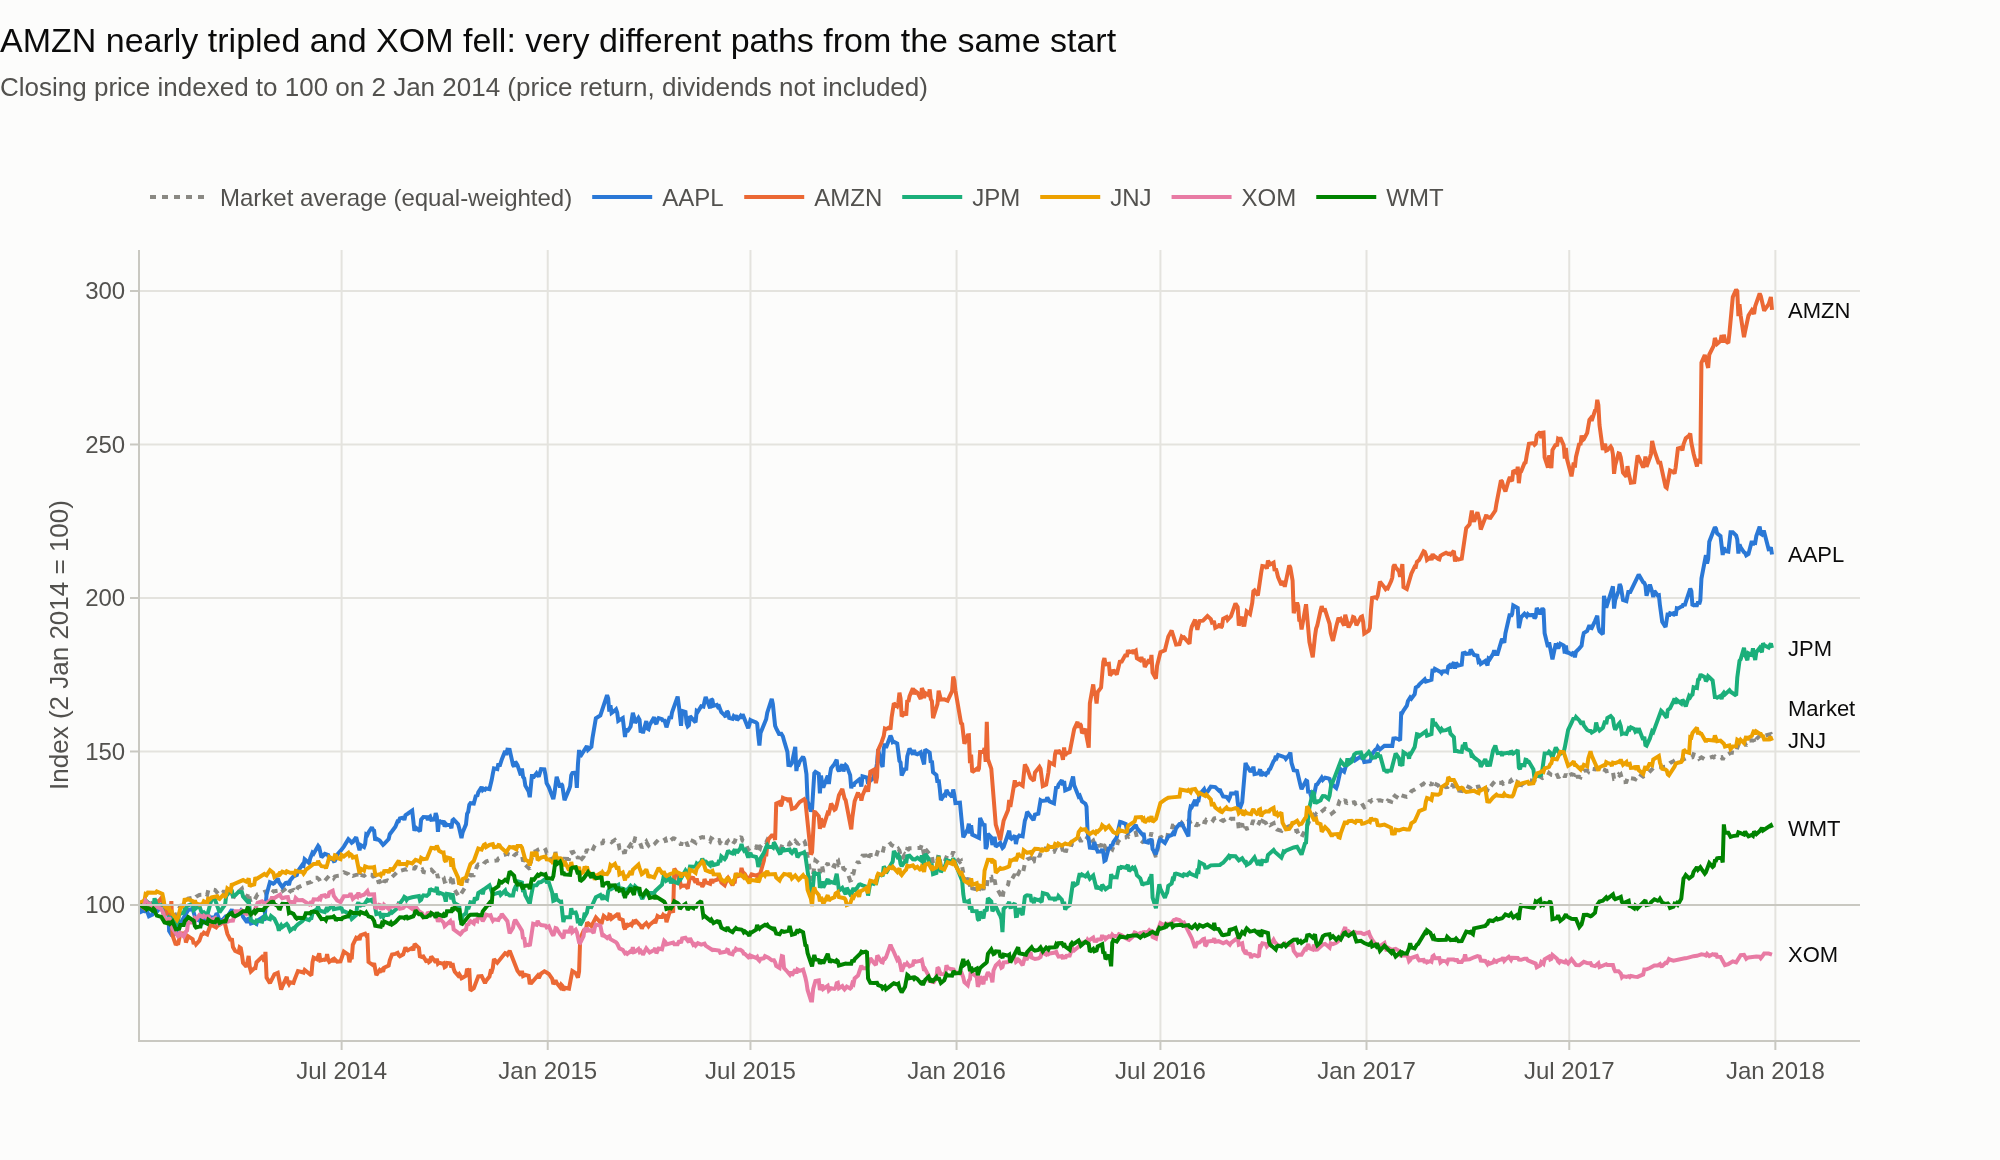

In [11]:
idx = 100 * C / C.iloc[0]
fig = go.Figure()
fig.add_scatter(x=mkt.index, y=mkt.market_index, name="Market average (equal-weighted)",
                line=dict(color=ch.MARKET_COLOR, width=2, dash="dot"))
for s in S:
    fig.add_scatter(x=idx.index, y=idx[s], name=s, line=dict(color=ch.color(s), width=2),
                    hovertemplate=f"{s} %{{x|%d %b %Y}}: %{{y:.1f}}<extra></extra>")
ch.end_labels(fig, {s: (idx.index[-1], idx[s].iloc[-1]) for s in S} | {"Market": (mkt.index[-1], mkt.market_index.iloc[-1])})
fig.add_hline(y=100, line=dict(color=ch.AXIS, width=1))
fig.update_layout(title=ch.title("AMZN nearly tripled and XOM fell: very different paths from the same start",
                                 "Closing price indexed to 100 on 2 Jan 2014 (price return, dividends not included)"),
                  yaxis_title="Index (2 Jan 2014 = 100)", xaxis_title=None, margin_r=70)
ch.save(fig, "01_growth_of_100", height=580)

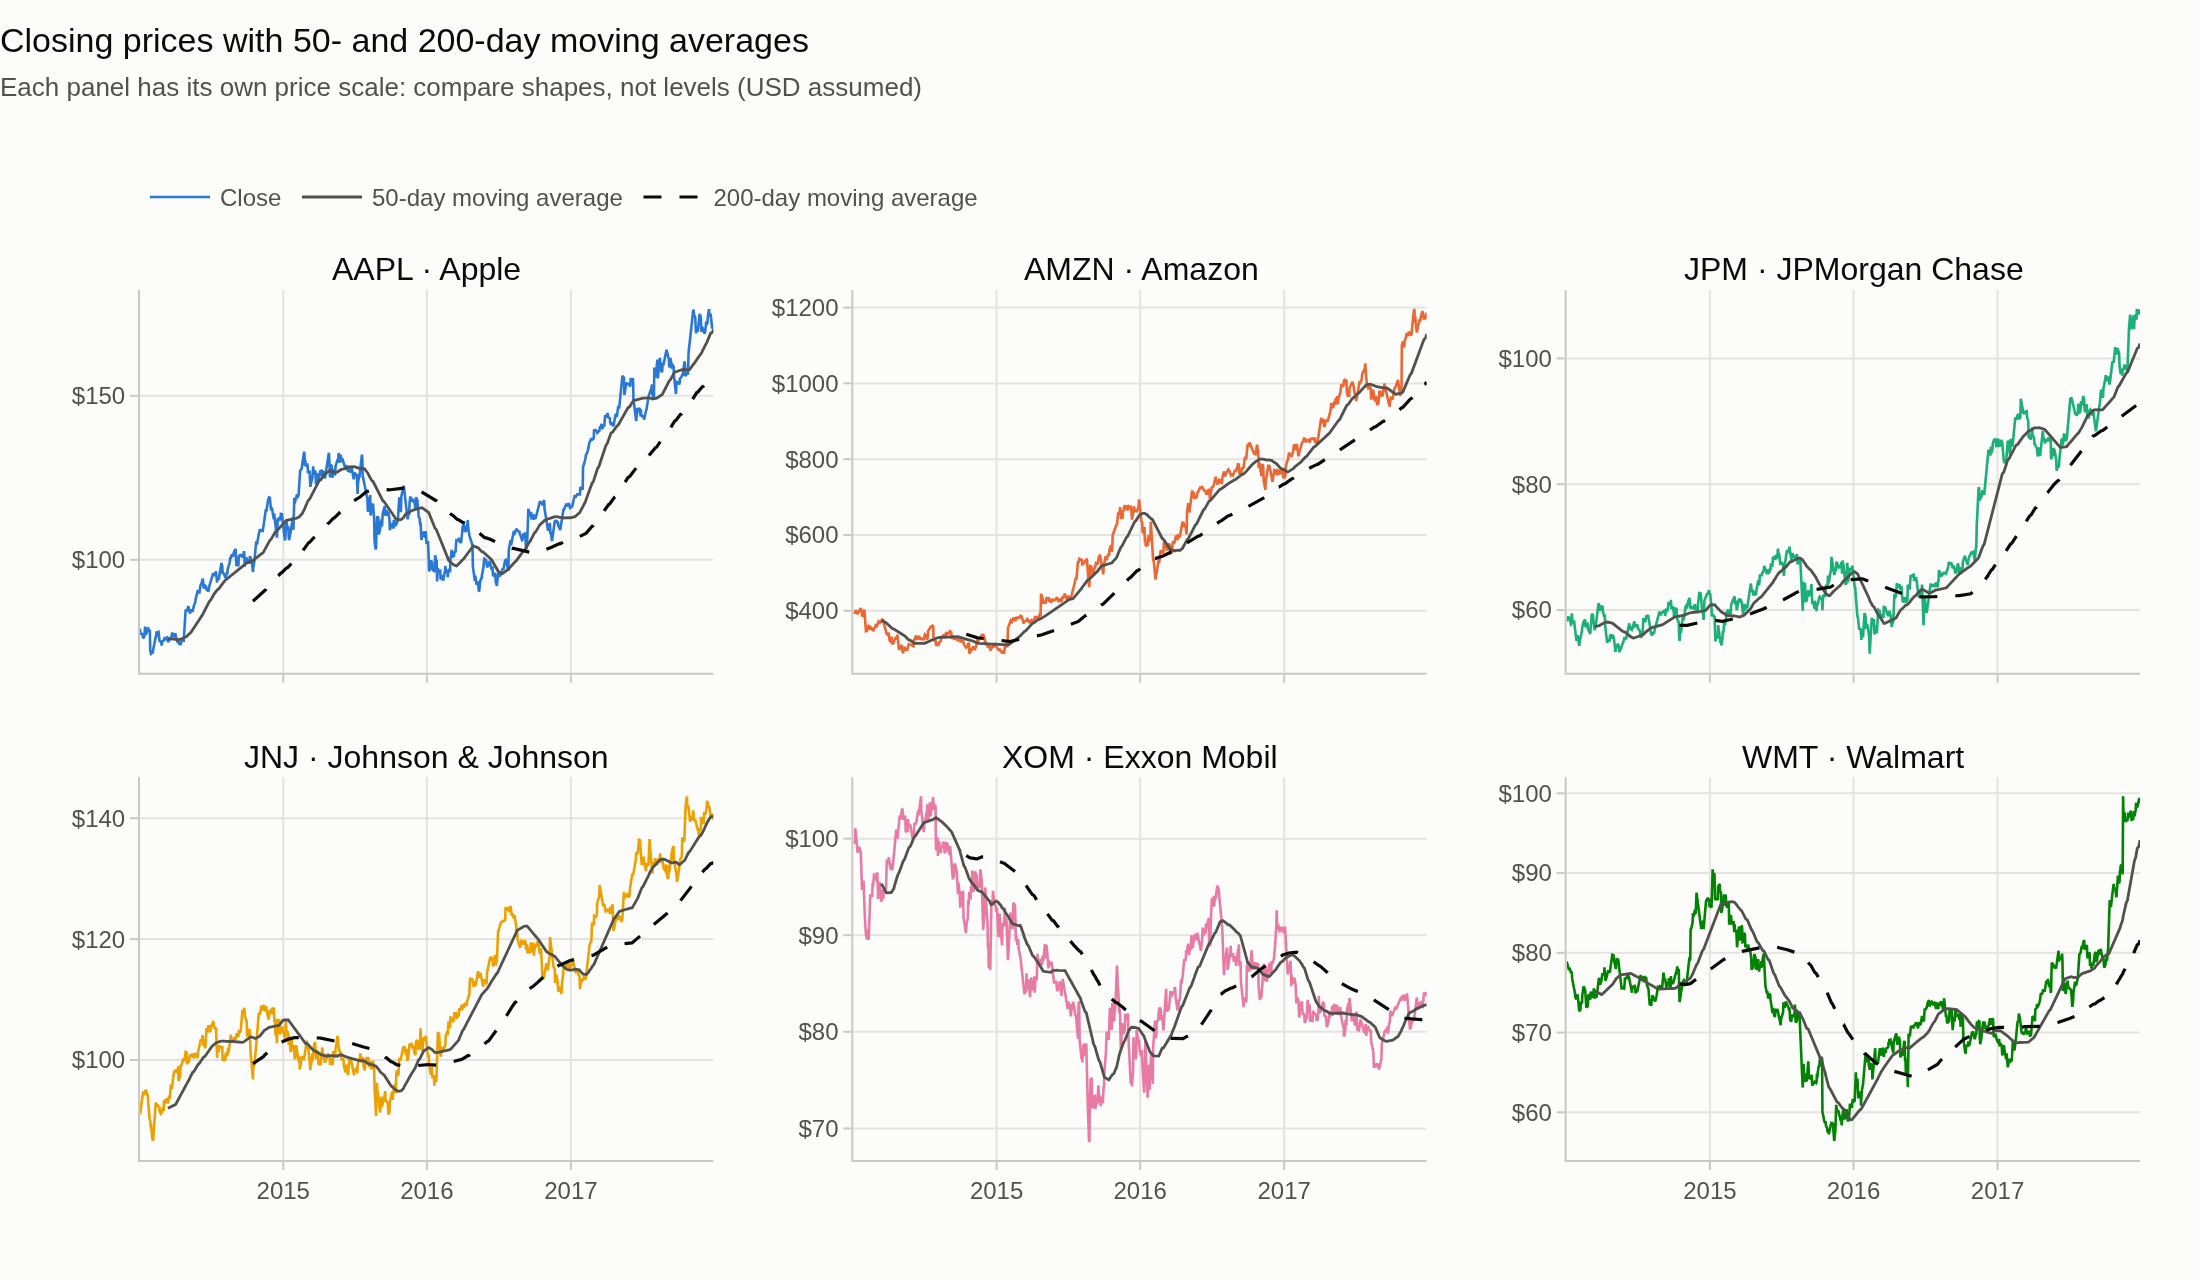

In [12]:
fig = make_subplots(rows=2, cols=3, subplot_titles=[f"{s} · {sp.COMPANY[s]}" for s in S], shared_xaxes=True,
                    vertical_spacing=0.12, horizontal_spacing=0.07)
for i, s in enumerate(S):
    r, c = i // 3 + 1, i % 3 + 1
    d = sel[sel.symbol == s]
    fig.add_scatter(x=d.date, y=d.close, line=dict(color=ch.color(s), width=1.3), name="Close", legendgroup="c",
                    showlegend=(i == 0), row=r, col=c)
    fig.add_scatter(x=d.date, y=d.ma_50, line=dict(color=ch.TEXT_2, width=1.4), name="50-day moving average",
                    legendgroup="m50", showlegend=(i == 0), row=r, col=c)
    fig.add_scatter(x=d.date, y=d.ma_200, line=dict(color=ch.TEXT, width=1.6, dash="dash"), name="200-day moving average",
                    legendgroup="m200", showlegend=(i == 0), row=r, col=c)
    fig.update_yaxes(tickprefix="$", row=r, col=c)
fig.update_layout(title=ch.title("Closing prices with 50- and 200-day moving averages",
                                 "Each panel has its own price scale: compare shapes, not levels (USD assumed)"))
ch.save(fig, "02_closing_price_moving_averages", width=1100, height=640)

**Price trends.** AMZN, AAPL, JPM and JNJ ended well above where they started. XOM fell through 2014 and 2015 with oil prices and ended below its start. WMT fell sharply in 2015 and recovered in 2017. The moving averages smooth out daily noise. When the 50-day line is above the 200-day line, the medium-term trend is up. For XOM it stayed below for most of 2014 to 2015, and for WMT for most of 2015. Moving averages describe the past trend and are not trading signals here.

Price **levels** are not comparable across stocks (AMZN traded at \$287 to \$1,196, JPM at \$53 to \$108), so all comparisons below use percentage returns.

### 3.3 Daily returns: distributions and unusual movements

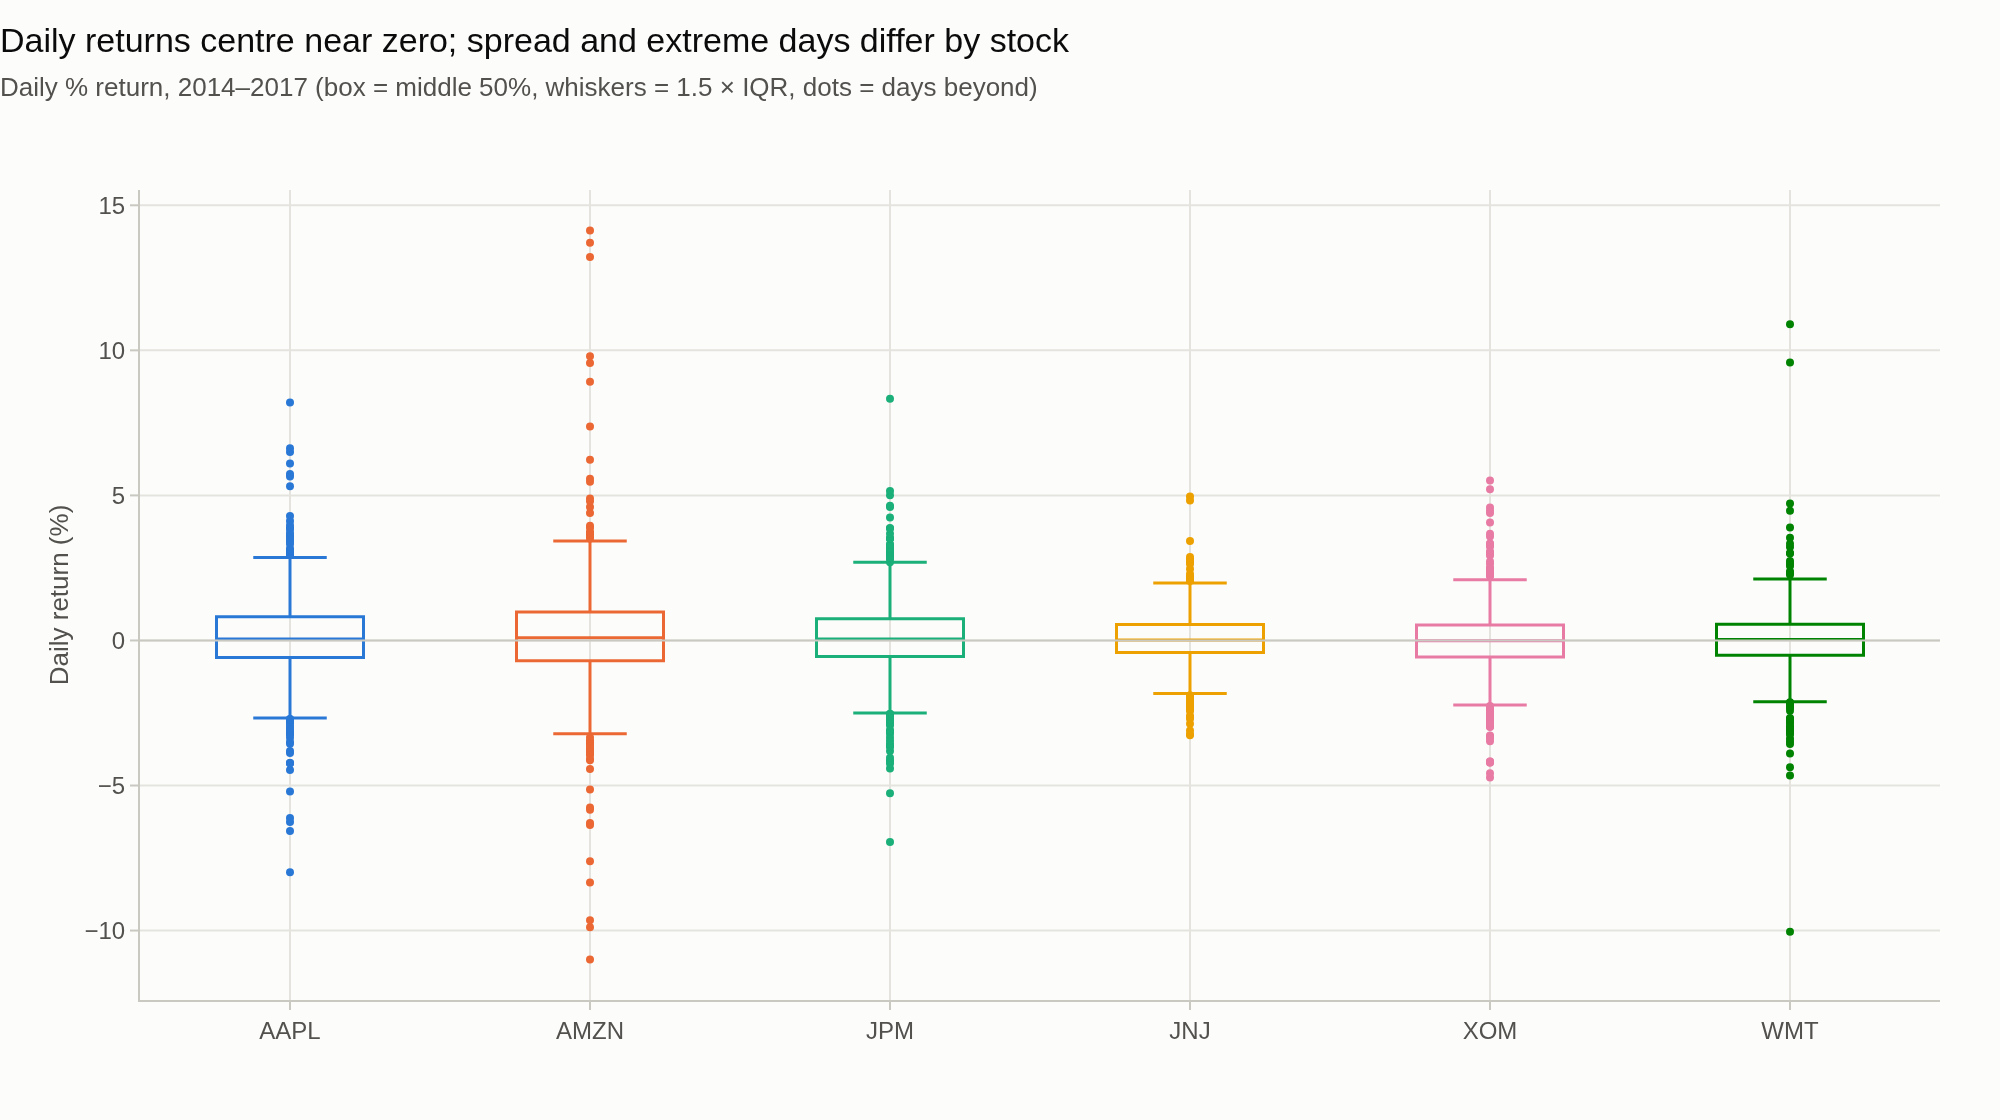

In [13]:
fig = go.Figure()
for s in S:
    fig.add_box(y=100 * R[s], name=s, marker=dict(color=ch.color(s), size=4), line=dict(color=ch.color(s), width=1.5),
                boxpoints="outliers", fillcolor="rgba(0,0,0,0)")
fig.add_hline(y=0, line=dict(color=ch.AXIS, width=1))
fig.update_layout(title=ch.title("Daily returns centre near zero; spread and extreme days differ by stock",
                                 "Daily % return, 2014–2017 (box = middle 50%, whiskers = 1.5 × IQR, dots = days beyond)"),
                  yaxis_title="Daily return (%)", showlegend=False)
ch.save(fig, "03_daily_return_distribution")

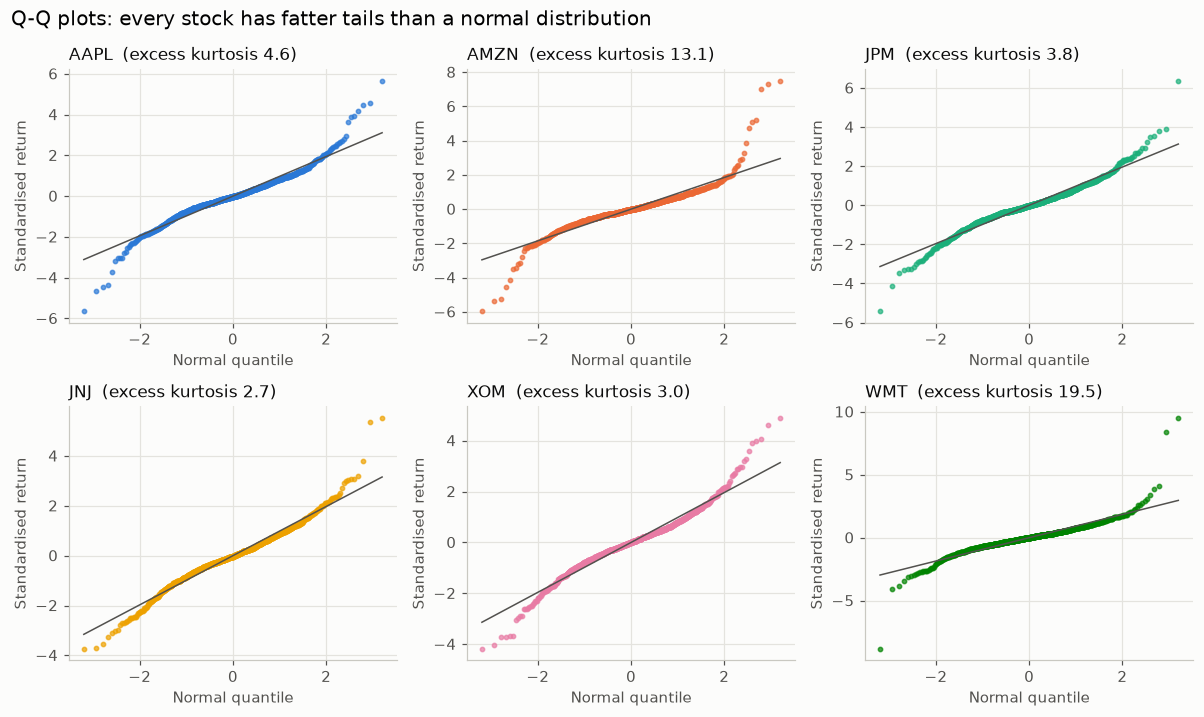

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
for ax, s in zip(axes.ravel(), S):
    z = (R[s] - R[s].mean()) / R[s].std()
    (osm, osr), (slope, inter, _) = stats.probplot(z, dist="norm")
    ax.plot(osm, osr, "o", ms=2.8, color=ch.color(s), alpha=0.7)
    ax.plot(osm, slope * osm + inter, color=ch.TEXT_2, lw=1)
    ax.set_title(f"{s}  (excess kurtosis {stats.kurtosis(R[s], bias=False):.1f})")
    ax.set_xlabel("Normal quantile"); ax.set_ylabel("Standardised return")
fig.suptitle("Q-Q plots: every stock has fatter tails than a normal distribution", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
ch.save_mpl(fig, "04_qq_plots"); plt.show()

Daily returns are centred close to zero, but **none is normally distributed**. The Q-Q plots bend away from the line at both ends: there are many more very large up and down days than a normal distribution allows. AMZN and WMT have the most extreme single days. This is why the analysis uses rank-based tests and serial-correlation-robust errors, not only tests that assume normality.

In [15]:
ext = []
for s in S:
    d = sel[sel.symbol == s].dropna(subset=["pct_return"])
    z = (d.pct_return - d.pct_return.mean()) / d.pct_return.std()
    top = d.loc[d.pct_return.abs().nlargest(3).index]
    for _, row in top.iterrows():
        ext.append({"symbol": s, "date": row.date.date(), "return_pct": 100 * row.pct_return,
                    "z_score": (row.pct_return - d.pct_return.mean()) / d.pct_return.std(),
                    "rel_volume": row.rel_volume})
    n4 = int((z.abs() > 4).sum())
    ext[-1]["days_beyond_4sd"] = n4
ext = pd.DataFrame(ext)
ext["days_beyond_4sd"] = ext.groupby("symbol")["days_beyond_4sd"].transform("max")
ext.to_csv(OUT / "extreme_moves_selected.csv", index=False)
display(ext)
exp4 = 2 * stats.norm.sf(4) * len(R)
print(f"Under a normal distribution, {exp4:.3f} days beyond 4 SD would be expected per stock in {len(R)} days.")

,symbol,date,return_pct,z_score,rel_volume,days_beyond_4sd
0,AAPL,2014-04-24,8.1982,5.6693,3.4782,8.0000
1,AAPL,2014-01-28,-7.9927,-5.6459,2.8129,8.0000
2,AAPL,2017-08-01,6.6295,4.5730,1.0325,8.0000
3,AMZN,2015-04-24,14.1311,7.5120,6.6615,11.0000
4,AMZN,2015-01-30,13.7116,7.2870,7.2389,11.0000
5,AMZN,2017-10-27,13.2164,7.0214,6.1460,11.0000
6,JPM,2016-02-12,8.3286,6.3794,1.6250,3.0000
7,JPM,2016-06-24,-6.9477,-5.4192,3.2404,3.0000
8,JPM,2015-08-24,-5.2673,-4.1214,3.0483,3.0000
9,JNJ,2016-01-26,4.9585,5.5244,2.0715,2.0000


Under a normal distribution, 0.064 days beyond 4 SD would be expected per stock in 1006 days.


**Unusual price movements.** Each stock's three largest moves are 3.8 to 9.5 standard deviations from its mean, and most happened on days with **2 to 11 times the usual trading volume** (two exceptions, AAPL on 1 August 2017 and XOM on 3 February 2016, had near-normal volume). A normal distribution expects about 0.06 days beyond 4 SD per stock over this period; the six stocks have between 2 (JNJ) and 11 (AMZN). The data cannot say why these moves happened (the causes could be earnings releases or other news, but the file contains no events), so they are kept. Section 8 checks that no conclusion depends on them.

### 3.4 Trading volume

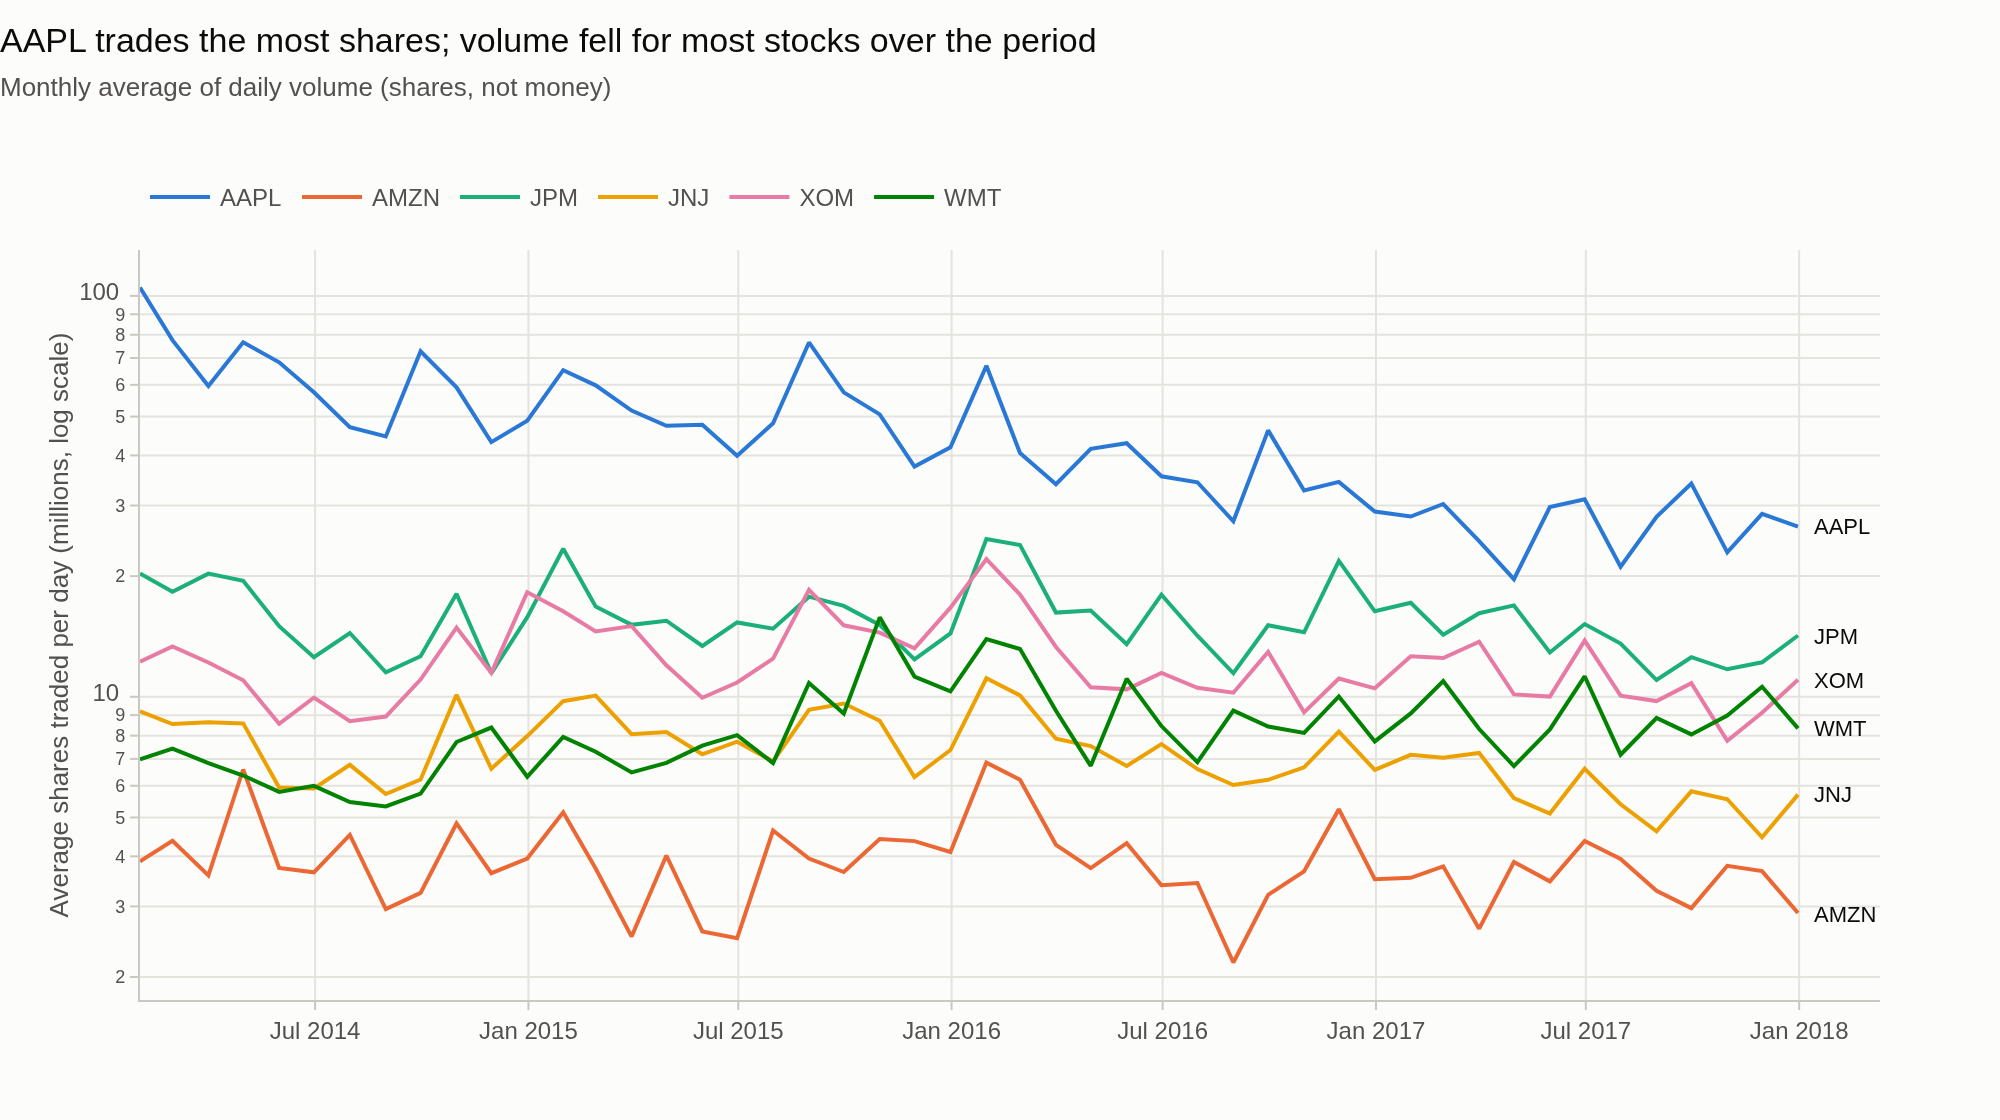

In [16]:
vol_m = V.resample("ME").mean() / 1e6
fig = go.Figure()
for s in S:
    fig.add_scatter(x=vol_m.index, y=vol_m[s], name=s, line=dict(color=ch.color(s), width=2),
                    hovertemplate=f"{s} %{{x|%b %Y}}: %{{y:.1f}}M shares/day<extra></extra>")
ch.end_labels(fig, {s: (vol_m.index[-1], vol_m[s].iloc[-1]) for s in S}, log=True)
fig.update_yaxes(type="log", title_text="Average shares traded per day (millions, log scale)")
fig.update_layout(title=ch.title("AAPL trades the most shares; volume fell for most stocks over the period",
                                 "Monthly average of daily volume (shares, not money)"), margin_r=60)
ch.save(fig, "05_monthly_volume", height=560)

Volume is a count of **shares**, not money. It depends on share price and the number of shares in issue, so a higher volume does not mean more money traded or more interest. AAPL trades 45 million shares a day on average and AMZN 3.9 million, but AMZN's price was about seven times higher. Comparisons **within** a stock over time are meaningful, and Section 5.2 uses **relative volume** (each day's volume divided by the median of the previous 20 days) for that reason. Monthly volume peaked in **January 2016** for AMZN, JPM, JNJ and XOM (and October 2015 for WMT), the most turbulent period (Section 6.2). Comparing the last 12 months with the first 12, volume fell for five of the six (AAPL's by more than half) and rose for WMT.

### 3.5 Market-wide view (all symbols)
These answer the brief's market-wide questions (highest and lowest closing prices, highest returns) from the whole file. Total returns are compared only among the **479 symbols with complete histories**, so that every stock covers the same period.

In [17]:
hi = df.loc[df.close.idxmax(), ["symbol", "date", "close"]]
lo = df.loc[df.close.idxmin(), ["symbol", "date", "close"]]
by_sym = df.groupby("symbol").close.agg(["max", "min", "mean"])
extremes = pd.concat([by_sym.nlargest(5, "max").assign(group="highest closing price"),
                      by_sym.nsmallest(5, "min").assign(group="lowest closing price")])
extremes.to_csv(OUT / "market_closing_price_extremes.csv")
print(f"Highest close: {hi.symbol} ${hi.close:,.2f} on {hi.date.date()}; lowest close: {lo.symbol} ${lo.close:,.2f} on {lo.date.date()}")
display(extremes)

complete = cov.index[cov.complete]
cd = df[df.symbol.isin(complete)]
vd = cd[cd.valid_return]
xs = pd.DataFrame({
    "first_close": cd.groupby("symbol").close.first(), "last_close": cd.groupby("symbol").close.last(),
    "mean_daily_return": vd.groupby("symbol").pct_return.mean(),
    "ann_volatility": vd.groupby("symbol").pct_return.std() * np.sqrt(sp.TRADING_DAYS),
    "avg_volume": cd.groupby("symbol").volume_clean.mean(),
})
xs["total_return"] = xs.last_close / xs.first_close - 1
affected = set(df.loc[df.corporate_action | df.price_error, "symbol"])
xs["affected_by_flag"] = xs.index.isin(affected)
xs.sort_values("total_return", ascending=False).to_csv(OUT / "market_total_returns_complete_histories.csv")
print(f"Median total price return of the {len(xs)} complete-history symbols: {xs.total_return.median():.1%}; "
      f"share with a gain: {(xs.total_return > 0).mean():.1%}; equal-weighted market average: {mkt.market_index.iloc[-1] / 100 - 1:.1%}")

Highest close: PCLN $2,049.00 on 2017-08-08; lowest close: CHK $1.59 on 2016-02-12


,max,min,mean,group
symbol,,,,
PCLN,"2,049.0000",973.8000,"1,390.2726",highest closing price
AMZN,"1,195.8300",286.9500,619.2448,highest closing price
GOOGL,"1,085.0900",497.0600,722.5590,highest closing price
GOOG,"1,077.1400",492.5500,714.4968,highest closing price
AZO,815.9800,474.1100,660.2464,highest closing price
CHK,31.3000,1.5900,11.7581,lowest closing price
AMD,15.2000,1.6200,5.9086,lowest closing price
FCX,39.0400,3.7400,18.2060,lowest closing price
MRO,41.6900,6.7300,21.4913,lowest closing price


Median total price return of the 479 complete-history symbols: 46.7%; share with a gain: 79.7%; equal-weighted market average: 54.9%


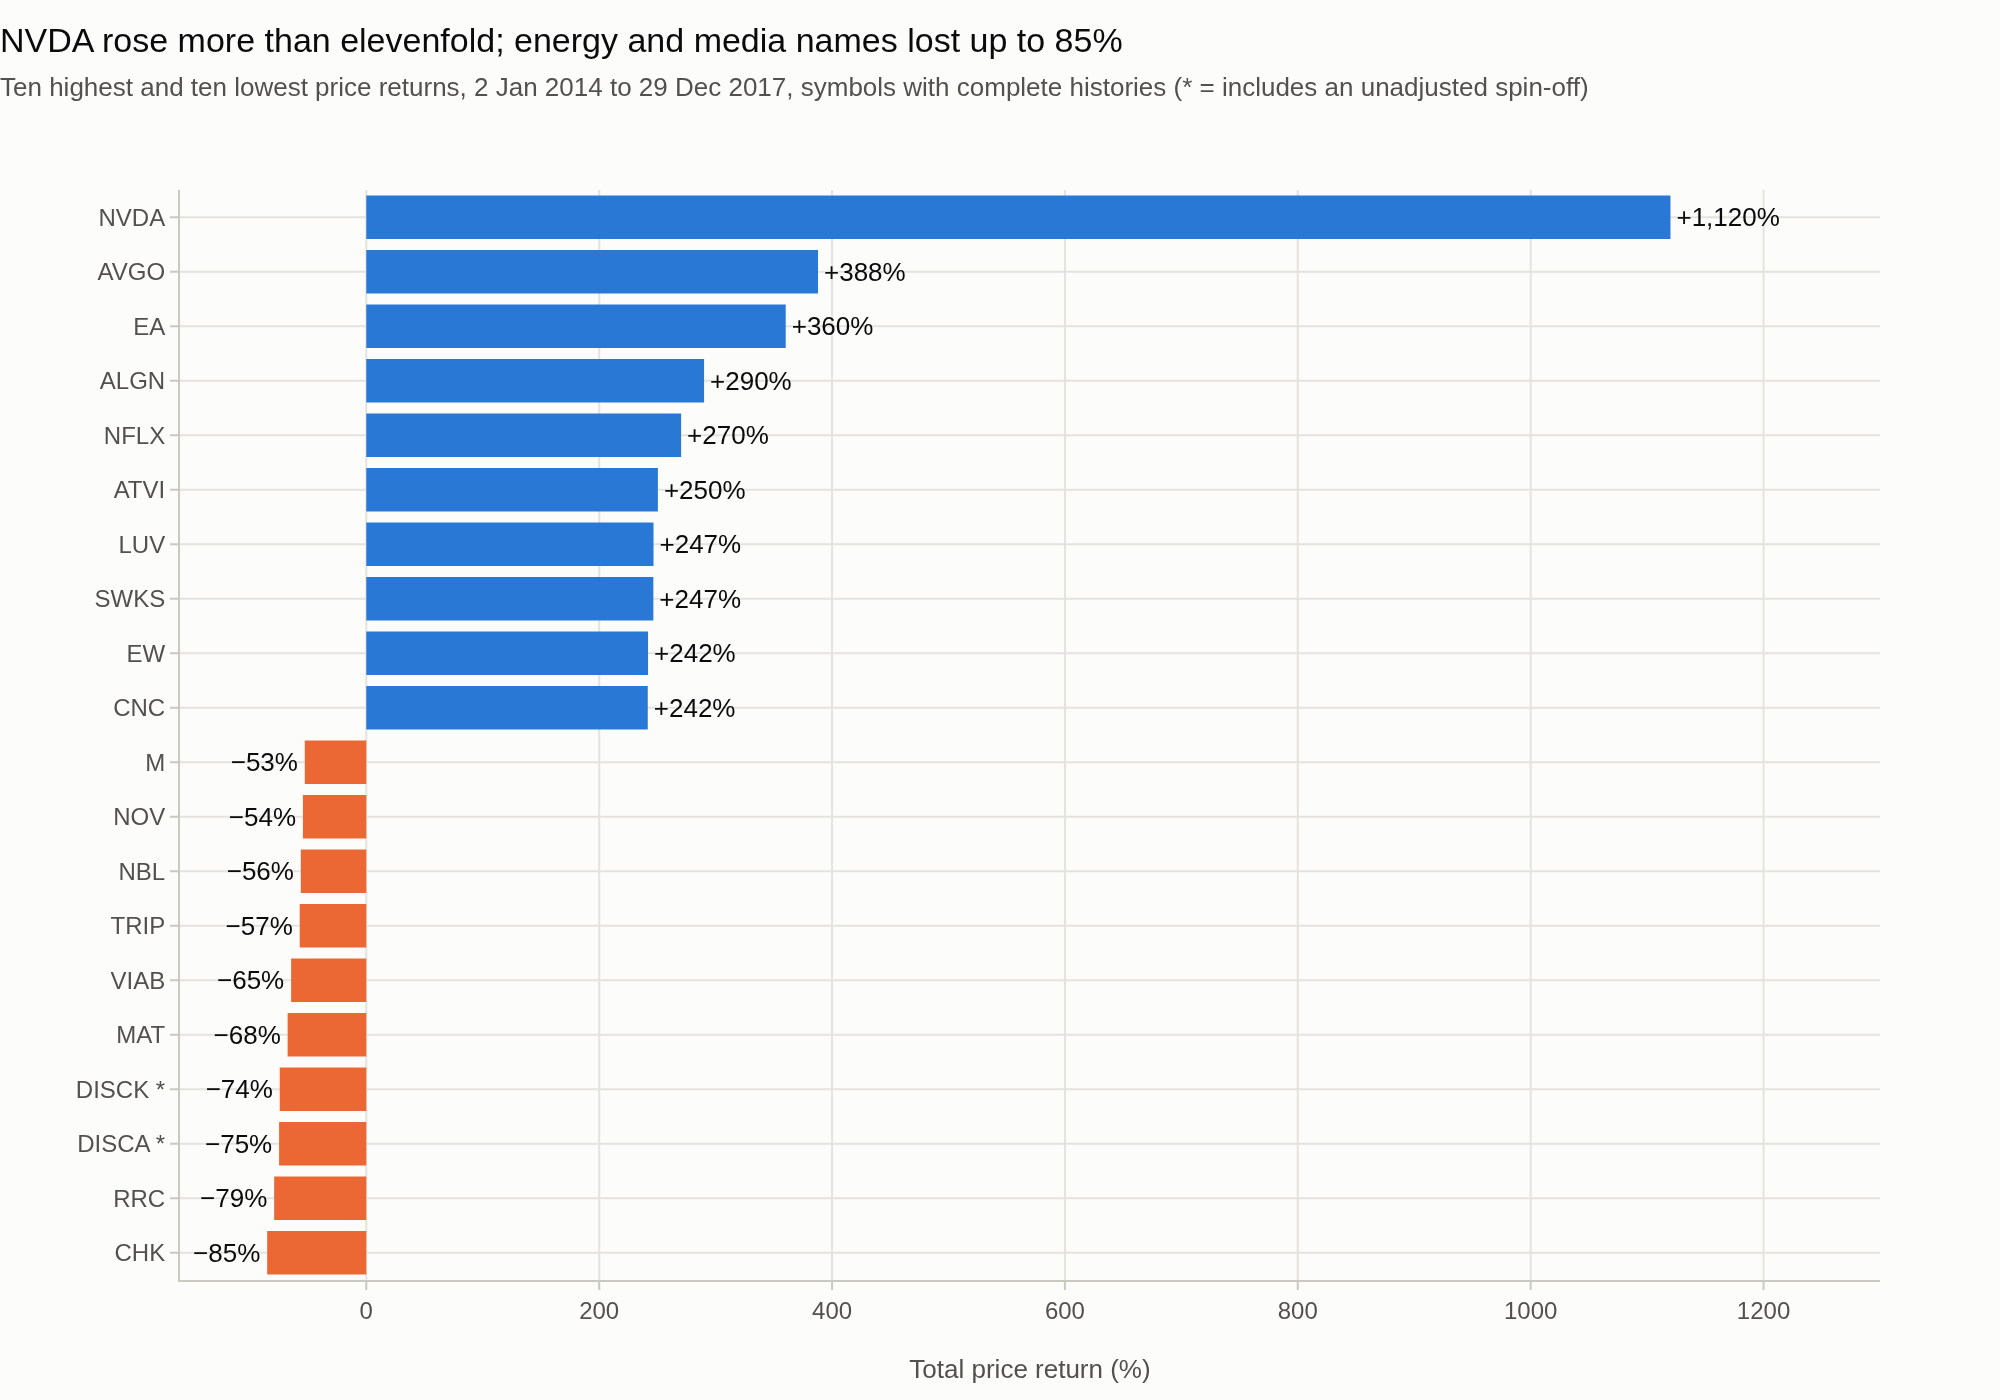

In [18]:
top = xs.nlargest(10, "total_return"); bot = xs.nsmallest(10, "total_return")
tb = pd.concat([top, bot.iloc[::-1]])
lab = [f"{s}{' *' if a else ''}" for s, a in zip(tb.index, tb.affected_by_flag)]
fig = go.Figure(go.Bar(x=100 * tb.total_return, y=lab, orientation="h",
                       marker_color=[ch.ACCENT if v > 0 else ch.SECOND for v in tb.total_return],
                       text=[f"{100 * v:+,.0f}%".replace("-", "−") for v in tb.total_return], textposition="outside", cliponaxis=False,
                       hovertemplate="%{y}: %{x:.1f}%<extra></extra>"))
fig.update_yaxes(autorange="reversed")
fig.update_layout(title=ch.title("NVDA rose more than elevenfold; energy and media names lost up to 85%",
                                 "Ten highest and ten lowest price returns, 2 Jan 2014 to 29 Dec 2017, symbols with complete histories (* = includes an unadjusted spin-off)"),
                  xaxis_title="Total price return (%)", xaxis_range=[-160, 1300], showlegend=False, margin_l=90, margin_r=60)
ch.save(fig, "06_top_bottom_total_returns", height=700)

**Highest and lowest closing prices.** PCLN (Priceline) had the highest close in the file, \$2,049.00 on 8 August 2017. CHK (Chesapeake Energy) had the lowest, \$1.59 on 12 February 2016. A high price reflects how many shares a company has issued, not how well it performed, so these are reported only because the brief asks.

**Highest and lowest returns.** Among the 479 complete histories, NVDA's price rose by about 1,120%, followed by AVGO and EA. CHK (−85%) and RRC (−79%) lost the most, along with media and other energy companies. **DISCA and DISCK (marked \*) are not real losses of that size**: their August 2014 share distribution is not adjusted in the file. Half of the complete-history stocks gained more than 47%, and 80% gained something. Survivorship bias inflates these figures, because companies that failed or were removed before 2018 are not in the file.

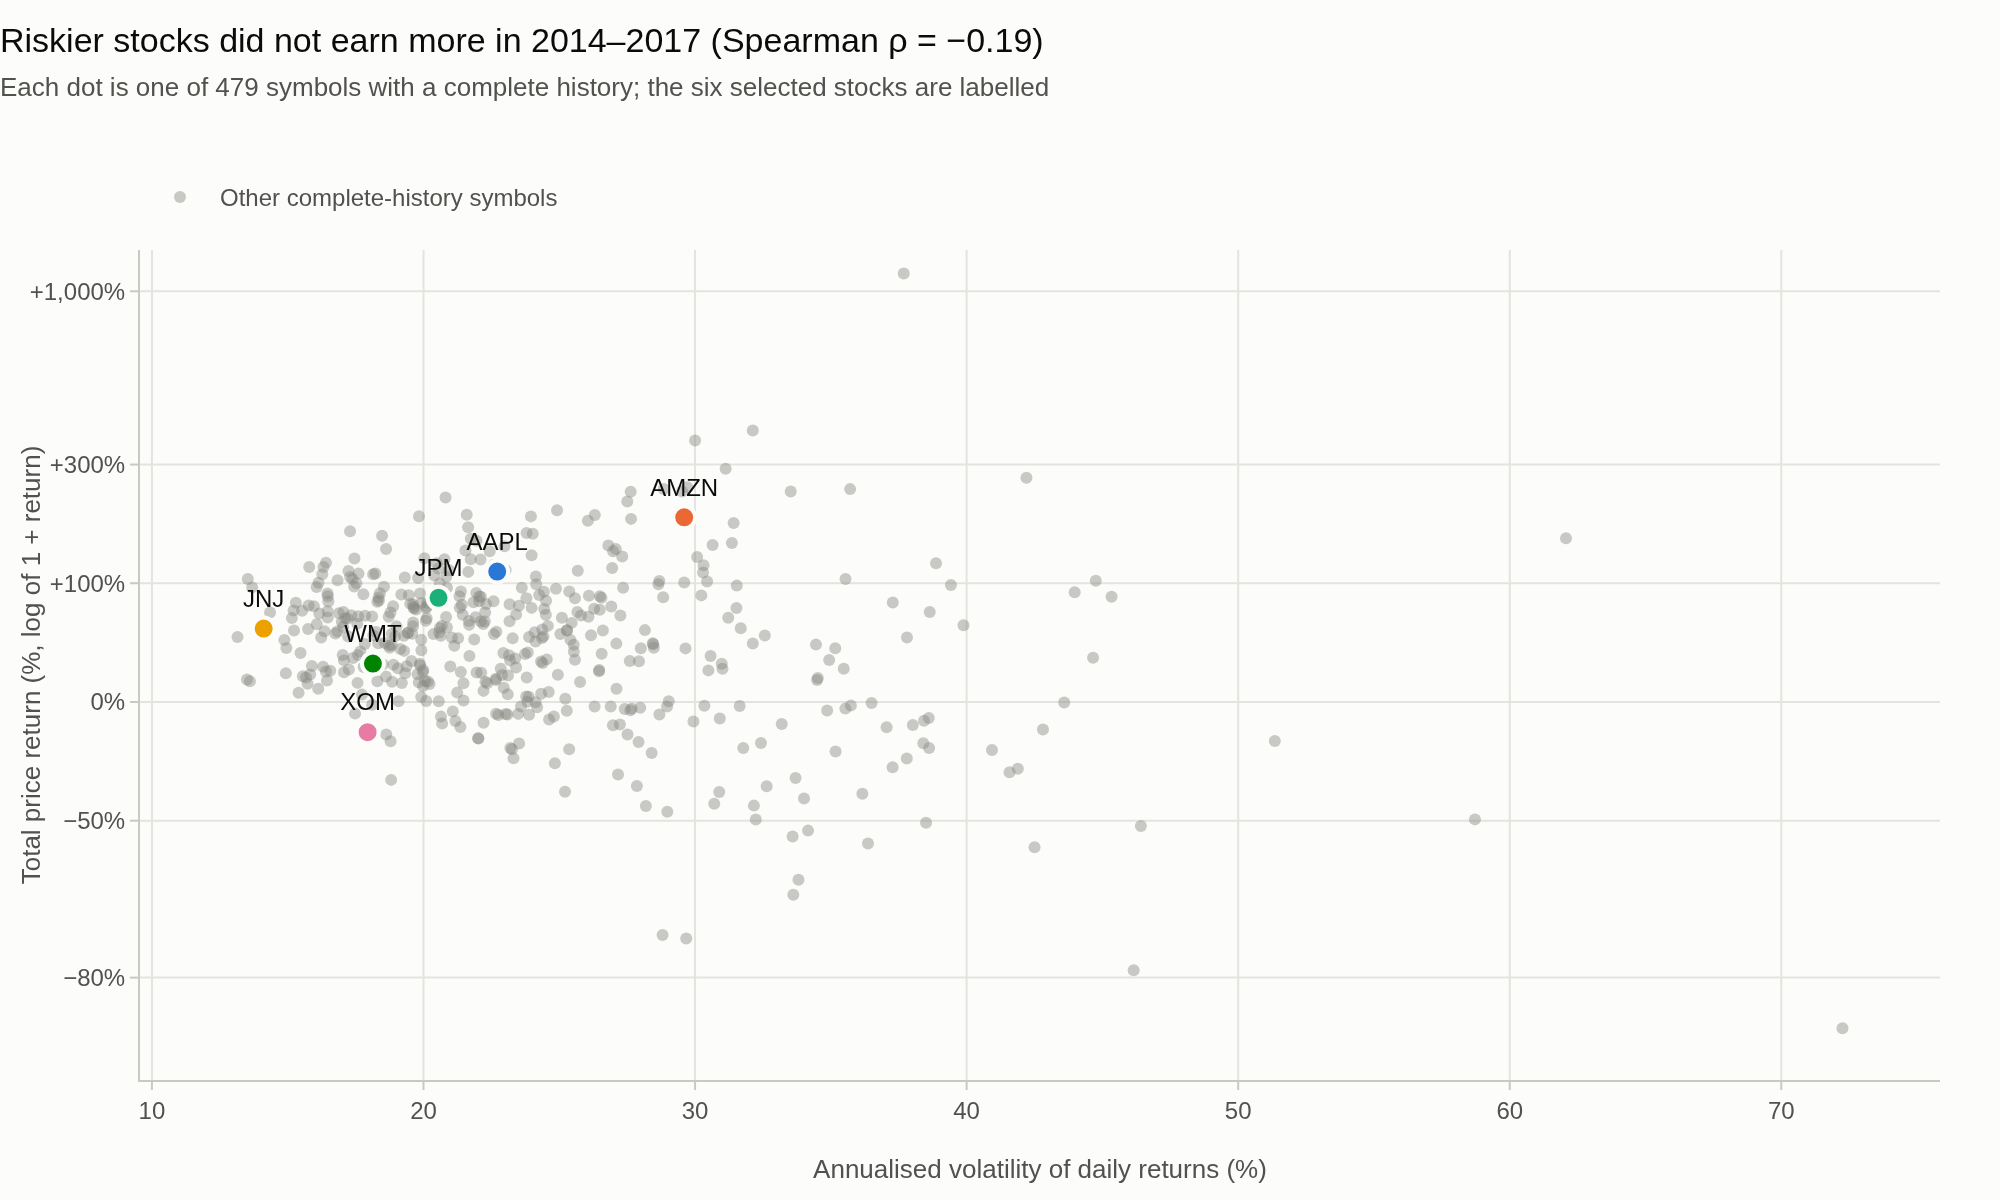

In [19]:
fig = go.Figure()
others = xs[~xs.index.isin(S)]
fig.add_scatter(x=100 * others.ann_volatility, y=100 * others.total_return, mode="markers", name="Other complete-history symbols",
                marker=dict(color=ch.MARKET_COLOR, size=6, opacity=0.45, line=dict(width=0)),
                text=others.index, hovertemplate="%{text}: volatility %{x:.0f}%, return %{y:.0f}%<extra></extra>")
for s in S:
    fig.add_scatter(x=[100 * xs.loc[s, "ann_volatility"]], y=[100 * xs.loc[s, "total_return"]], mode="markers+text", name=s,
                    text=[s], textposition="top center", textfont=dict(color=ch.TEXT, size=12), showlegend=False,
                    marker=dict(color=ch.color(s), size=11, line=dict(width=2, color=ch.SURFACE)))
rho_vr = stats.spearmanr(xs.ann_volatility, xs.total_return)
fig.update_yaxes(type="log", title_text="Total price return (%, log of 1 + return)", tickvals=[-80, -50, 0, 100, 300, 1000],
                 range=[np.log10(11), np.log10(1400)])
fig.data[0].y = 100 * (1 + others.total_return)
for t, s in zip(fig.data[1:], S):
    t.y = [100 * (1 + xs.loc[s, "total_return"])]
fig.update_yaxes(tickvals=[20, 50, 100, 200, 400, 1100], ticktext=["−80%", "−50%", "0%", "+100%", "+300%", "+1,000%"])
fig.update_layout(title=ch.title(f"Riskier stocks did not earn more in 2014–2017 (Spearman ρ = {rho_vr.statistic:.2f})".replace("-", "−"),
                                 "Each dot is one of 479 symbols with a complete history; the six selected stocks are labelled"),
                  xaxis_title="Annualised volatility of daily returns (%)")
ch.save(fig, "07_risk_vs_return_all_stocks", height=600)

Across the 479 stocks, higher volatility was **not** rewarded with higher return over these four years. The rank correlation between volatility and total return is weakly **negative**, driven by energy and commodity stocks that were both volatile and fell with oil prices. Finance theory expects higher risk to earn more over the long run, but four years with an oil crash is one period, not the long run. The six selected stocks sit in the middle of the cloud: none is among the most volatile.

## 4. Descriptive statistics
### 4.1 Closing prices
Price statistics describe each stock's price **level** in US dollars. Variance and standard deviation of price grow with trend and price level, so they measure how far the price **travelled**, not risk. Risk is measured on returns (4.2).

In [20]:
desc_p = pd.DataFrame({s: sp.describe(C[s]) for s in S}).T
desc_p["cv"] = desc_p["std"] / desc_p["mean"]
desc_p["first_close"] = C.iloc[0]; desc_p["last_close"] = C.iloc[-1]
desc_p["date_of_max"] = C.idxmax().dt.date; desc_p["date_of_min"] = C.idxmin().dt.date
cols_p = ["n", "first_close", "last_close", "mean", "median", "min", "date_of_min", "max", "date_of_max", "std", "variance", "q1", "q3", "iqr", "cv", "skewness"]
desc_p[cols_p].to_csv(OUT / "descriptive_stats_closing_price.csv")
display(desc_p[cols_p])

,n,first_close,last_close,mean,median,min,date_of_min,max,date_of_max,std,variance,q1,q3,iqr,cv,skewness
AAPL,"1,007.0000",79.0185,169.2300,116.8399,113.0500,71.3974,2014-01-30,176.4200,2017-12-18,24.5473,602.5686,99.0250,129.3600,30.3350,0.2101,0.4682
AMZN,"1,007.0000",397.9700,"1,169.4700",619.2448,591.4300,286.9500,2015-01-15,"1,195.8300",2017-11-27,256.4504,"65,766.7962",370.5700,818.1200,447.5500,0.4141,0.3725
JPM,"1,007.0000",58.2100,106.9400,69.8867,64.0400,53.0700,2016-02-11,107.8300,2017-12-21,14.1411,199.9720,59.3950,84.4300,25.0350,0.2023,0.9905
JNJ,"1,007.0000",91.0300,139.7200,110.9646,106.4700,86.6200,2014-02-04,143.6200,2017-10-23,13.6349,185.9092,100.4500,120.1150,19.6650,0.1229,0.6448
XOM,"1,007.0000",99.7500,83.6400,87.0490,85.4800,68.7100,2015-08-25,104.3800,2014-06-23,7.4565,55.5990,81.7900,92.1300,10.3400,0.0857,0.4240
WMT,"1,007.0000",78.9100,98.7500,74.5777,74.3800,56.4200,2015-11-13,99.6200,2017-11-16,7.9194,62.7176,69.6800,78.5250,8.8450,0.1062,0.5131


### 4.2 Daily percentage returns

In [21]:
desc_r = pd.DataFrame({s: sp.describe(R[s]) for s in S}).T
desc_r["total_return"] = [sp.total_return(C[s]) for s in S]
desc_r["annualised_return"] = [sp.annualised_return(C[s]) for s in S]
desc_r["ann_volatility"] = desc_r["std"] * np.sqrt(sp.TRADING_DAYS)
desc_r["sharpe_like"] = desc_r["mean"] / desc_r["std"] * np.sqrt(sp.TRADING_DAYS)
dd = {s: sp.max_drawdown(C[s]) for s in S}
desc_r["max_drawdown"] = [dd[s][0] for s in S]
desc_r["drawdown_peak"] = [dd[s][1].date() for s in S]; desc_r["drawdown_trough"] = [dd[s][2].date() for s in S]
desc_r["share_up_days"] = (R > 0).mean()
desc_r["jarque_bera_p"] = [stats.jarque_bera(R[s]).pvalue for s in S]
m_d = sp.describe(mret)
desc_r.loc["Market avg"] = {**m_d, "total_return": mkt.market_index.iloc[-1] / 100 - 1,
                            "annualised_return": (mkt.market_index.iloc[-1] / 100) ** (252 / len(mret)) - 1,
                            "ann_volatility": m_d["std"] * np.sqrt(252), "sharpe_like": m_d["mean"] / m_d["std"] * np.sqrt(252),
                            "max_drawdown": sp.max_drawdown(mkt.market_index)[0], "share_up_days": (mret > 0).mean(),
                            "jarque_bera_p": stats.jarque_bera(mret).pvalue}
desc_r.to_csv(OUT / "descriptive_stats_daily_returns.csv")
show = desc_r[["n", "mean", "median", "std", "variance", "min", "max", "skewness", "excess_kurtosis", "total_return",
               "annualised_return", "ann_volatility", "sharpe_like", "max_drawdown", "share_up_days", "jarque_bera_p"]].copy()
pct_cols = ["mean", "median", "std", "min", "max", "total_return", "annualised_return", "ann_volatility", "max_drawdown", "share_up_days"]
display(show.style.format({c: "{:.2%}" for c in pct_cols} | {"variance": "{:.6f}", "skewness": "{:.2f}", "excess_kurtosis": "{:.1f}",
                                                               "sharpe_like": "{:.2f}", "jarque_bera_p": "{:.1e}", "n": "{:.0f}"}))

,n,mean,median,std,variance,min,max,skewness,excess_kurtosis,total_return,annualised_return,ann_volatility,sharpe_like,max_drawdown,share_up_days,jarque_bera_p
AAPL,1006,0.09%,0.05%,1.43%,0.000205,-7.99%,8.20%,0.02,4.6,114.17%,21.02%,22.71%,0.95,-32.08%,52.09%,4.8e-193
AMZN,1006,0.12%,0.09%,1.86%,0.000348,-11.00%,14.13%,0.78,13.1,193.86%,31.00%,29.60%,1.06,-30.53%,53.78%,0.0e+00
JPM,1006,0.07%,0.05%,1.29%,0.000168,-6.95%,8.33%,0.08,3.8,83.71%,16.46%,20.55%,0.84,-24.27%,51.69%,8.2e-133
JNJ,1006,0.05%,0.02%,0.89%,0.000079,-3.27%,4.96%,0.17,2.7,53.49%,11.33%,14.11%,0.83,-16.81%,51.29%,2.4e-66
XOM,1006,-0.01%,-0.01%,1.13%,0.000128,-4.73%,5.52%,0.11,3.0,-16.15%,-4.32%,17.94%,-0.16,-34.17%,49.40%,1.3e-84
WMT,1006,0.03%,0.04%,1.14%,0.000131,-10.04%,10.90%,0.60,19.5,25.14%,5.78%,18.14%,0.40,-37.64%,51.99%,0.0e+00
Market avg,1006,0.05%,0.07%,0.80%,0.000064,-4.13%,3.24%,-0.45,2.7,54.85%,11.58%,12.66%,0.93,-16.43%,55.47%,3.3e-75


**Reading the table** (daily returns are fractions shown as %; *annualised* figures use 252 trading days a year):

* **Return:** AMZN had the highest mean daily return (0.12%, +194% in total, 31% a year compounded), then AAPL (+114%) and JPM (+84%). XOM was the only one with a loss (−16%). The mean and median daily returns are close for every stock.
* **Volatility:** JNJ was the calmest stock (daily SD 0.89%, 14% a year) and AMZN the most volatile (1.86%, 30% a year). That is a twofold difference in risk. The equal-weighted market average was less volatile (13% a year) than any single stock except JNJ, because averaging many stocks diversifies away much of each stock's own risk.
* **Return per unit of risk** (*sharpe_like* = mean ÷ SD × √252, without a risk-free rate): AMZN 1.06, AAPL 0.95, JPM 0.84, JNJ 0.83, WMT 0.40 and XOM −0.16; the market average 0.93. This is a historical ratio, not a forecast.
* **Drawdown:** every stock lost 17% to 38% from a peak at some point. WMT's −38% from January to November 2015 was the deepest. Even AMZN fell 31% in six weeks, from late December 2015 to early February 2016.
* **Shape:** excess kurtosis is 2.7 to 19.5 (0 for a normal distribution), and the Jarque-Bera test rejects normality for every stock (p < 10⁻¹⁰⁰).

### 4.3 Year-by-year returns, volatility and volume

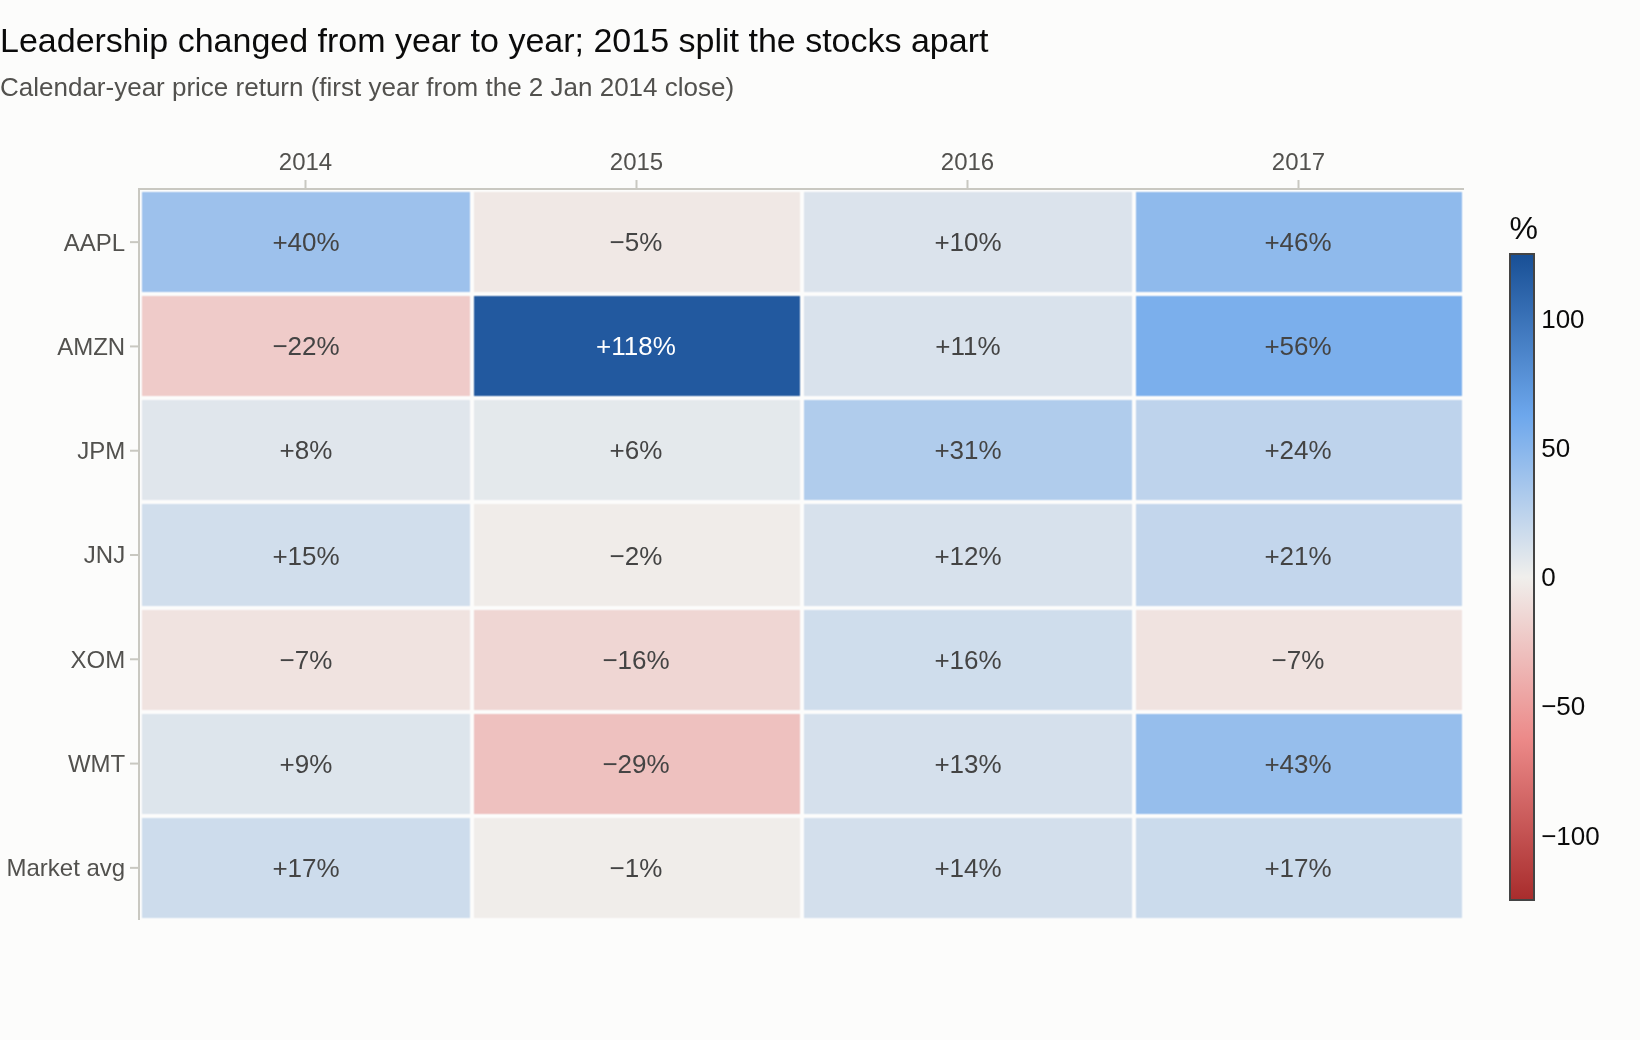

year,2014,2015,2016,2017
symbol,,,,
AAPL,21.7%,26.7%,23.4%,18.3%
AMZN,32.3%,33.6%,29.7%,21.0%
JPM,17.9%,22.3%,24.8%,16.2%
JNJ,14.6%,16.5%,13.5%,11.3%
XOM,16.4%,22.7%,19.3%,11.4%
WMT,13.3%,20.7%,19.3%,18.2%
Market avg,11.7%,15.3%,14.8%,7.2%


In [22]:
yr = []
for s in S + ["Market avg"]:
    for y in range(2014, 2018):
        if s == "Market avg":
            r = mret[mret.index.year == y]; tot = (1 + r).prod() - 1
        else:
            c_y = C[s][C.index.year <= y]; c_prev = C[s][C.index.year < y]
            start = c_prev.iloc[-1] if len(c_prev) else C[s].iloc[0]
            tot = c_y.iloc[-1] / start - 1; r = R[s][R.index.year == y]
        yr.append({"symbol": s, "year": y, "price_return": tot, "ann_volatility": r.std() * np.sqrt(252), "mean_daily": r.mean(),
                   "avg_volume_m": (V[s][V.index.year == y].mean() / 1e6) if s in S else np.nan})
yr = pd.DataFrame(yr)
yr.to_csv(OUT / "yearly_performance.csv", index=False)
pv = yr.pivot(index="symbol", columns="year", values="price_return").loc[S + ["Market avg"]]
fig = go.Figure(go.Heatmap(z=100 * pv.values, x=[str(c) for c in pv.columns], y=pv.index, colorscale=[[0.0, "#a82c2c"], [0.25, "#ec8a89"], [0.5, "#f0efec"], [0.75, "#6da7ec"], [1.0, "#184f95"]], zmid=0,
                           zmin=-125, zmax=125, text=[[f"{100 * v:+.0f}%".replace("-", "−") for v in row] for row in pv.values],
                           texttemplate="%{text}", textfont=dict(size=13), colorbar=dict(title="%", thickness=12),
                           hovertemplate="%{y} %{x}: %{text}<extra></extra>", xgap=2, ygap=2))
fig.update_yaxes(autorange="reversed", showgrid=False); fig.update_xaxes(showgrid=False, side="top", type="category")
fig.update_layout(title=ch.title("Leadership changed from year to year; 2015 split the stocks apart",
                                 "Calendar-year price return (first year from the 2 Jan 2014 close)"))
ch.save(fig, "08_yearly_returns_heatmap", width=820, height=520)
display(yr.pivot(index="symbol", columns="year", values="ann_volatility").loc[S + ["Market avg"]].style.format("{:.1%}").set_caption("Annualised volatility by year"))

**How prices changed between 2014 and 2017.** The best stock was different each year: AAPL in 2014, AMZN in 2015 (+119%), JPM in 2016 and AMZN again in 2017. 2015 was the weak year (WMT −29%, XOM −16%), and 2016 to 2017 were strong for almost everything. **Volatility was lowest in 2017** for five of the six stocks and for the market average (WMT was calmest in 2014), and highest in 2015 or 2016 for every stock. One year's ranking says little about the next.

## 5. Hypothesis testing
All tests use **α = 0.05**. When the same hypothesis is tested for six stocks (or 15 pairs), p-values are adjusted with **Holm's method** so the chance of at least one false positive stays at 5%. Daily returns have fat tails and volatility clusters (Section 6), so each test is chosen to be robust to these, and a rank-based or robust version is reported next to any classical test.

### 5.1 Hypothesis 1: Is the mean daily return different from zero?
* **H₀:** the stock's mean daily return is 0. **H₁:** it is not 0 (two-sided).
* **Tests:** (a) the one-sample **t-test**. With n = 1,006 the central limit theorem makes it reasonable despite fat tails, but it assumes independent days. (b) The same test with **Newey-West (HAC) standard errors** (`statsmodels`), which allow for autocorrelation and changing volatility: this is the main test. (c) The **Wilcoxon signed-rank test** of whether the returns are centred at zero (median-type, robust to outliers). (d) A **20-day moving-block bootstrap** 95% interval for the mean.

In [23]:
h1 = []
for s in S + ["Market avg"]:
    r = (R[s] if s in S else mret).values
    t = stats.ttest_1samp(r, 0.0); h = sp.hac_mean_test(r); w = stats.wilcoxon(r)
    boot = sp.block_bootstrap(r, lambda a: a.mean(), block=20, n_boot=2000, seed=SEED)
    lo, hi_ = sp.percentile_ci(boot)
    h1.append({"symbol": s, "n": len(r), "mean_daily_pct": 100 * r.mean(), "t_stat": t.statistic, "p_ttest": t.pvalue,
               "t_hac": h["t_hac"], "p_hac": h["p_hac"], "p_wilcoxon": w.pvalue, "boot_ci_low_pct": 100 * lo, "boot_ci_high_pct": 100 * hi_,
               "min_detectable_mean_pct": 100 * sp.min_detectable_mean(r.std(ddof=1), len(r)),
               "cohens_d": r.mean() / r.std(ddof=1)})
h1 = pd.DataFrame(h1).set_index("symbol")
h1["p_hac_holm"] = np.r_[sp.holm(h1.loc[S, "p_hac"]), np.nan]
h1["p_wilcoxon_holm"] = np.r_[sp.holm(h1.loc[S, "p_wilcoxon"]), np.nan]
h1["decision_5pct"] = np.where(h1.p_hac_holm.fillna(h1.p_hac) < ALPHA, "Reject H0", "Do not reject H0")
h1.to_csv(OUT / "h1_mean_return_tests.csv")
display(h1)

,n,mean_daily_pct,t_stat,p_ttest,t_hac,p_hac,p_wilcoxon,boot_ci_low_pct,boot_ci_high_pct,min_detectable_mean_pct,cohens_d,p_hac_holm,p_wilcoxon_holm,decision_5pct
symbol,,,,,,,,,,,,,,
AAPL,1006,0.0860,1.9053,0.0570,1.9410,0.0525,0.0194,0.0055,0.1769,0.1264,0.0601,0.2627,0.0969,Do not reject H0
AMZN,1006,0.1244,2.1166,0.0345,2.2068,0.0276,0.0081,0.0196,0.2375,0.1647,0.0667,0.1653,0.0484,Do not reject H0
JPM,1006,0.0688,1.6865,0.0920,1.7584,0.0790,0.0556,-0.0057,0.1417,0.1144,0.0532,0.3159,0.2224,Do not reject H0
JNJ,1006,0.0465,1.6603,0.0972,1.7020,0.0891,0.0632,-0.0052,0.0951,0.0785,0.0523,0.3159,0.2224,Do not reject H0
XOM,1006,-0.0111,-0.3123,0.7549,-0.3499,0.7265,0.7245,-0.0690,0.0461,0.0998,-0.0098,0.7721,0.7245,Do not reject H0
WMT,1006,0.0288,0.7993,0.4243,0.8672,0.3860,0.2399,-0.0313,0.0960,0.1009,0.0252,0.7721,0.4798,Do not reject H0
Market avg,1006,0.0467,1.8561,0.0637,1.9651,0.0497,0.0019,0.0024,0.0879,0.0704,0.0585,NaN,NaN,Reject H0


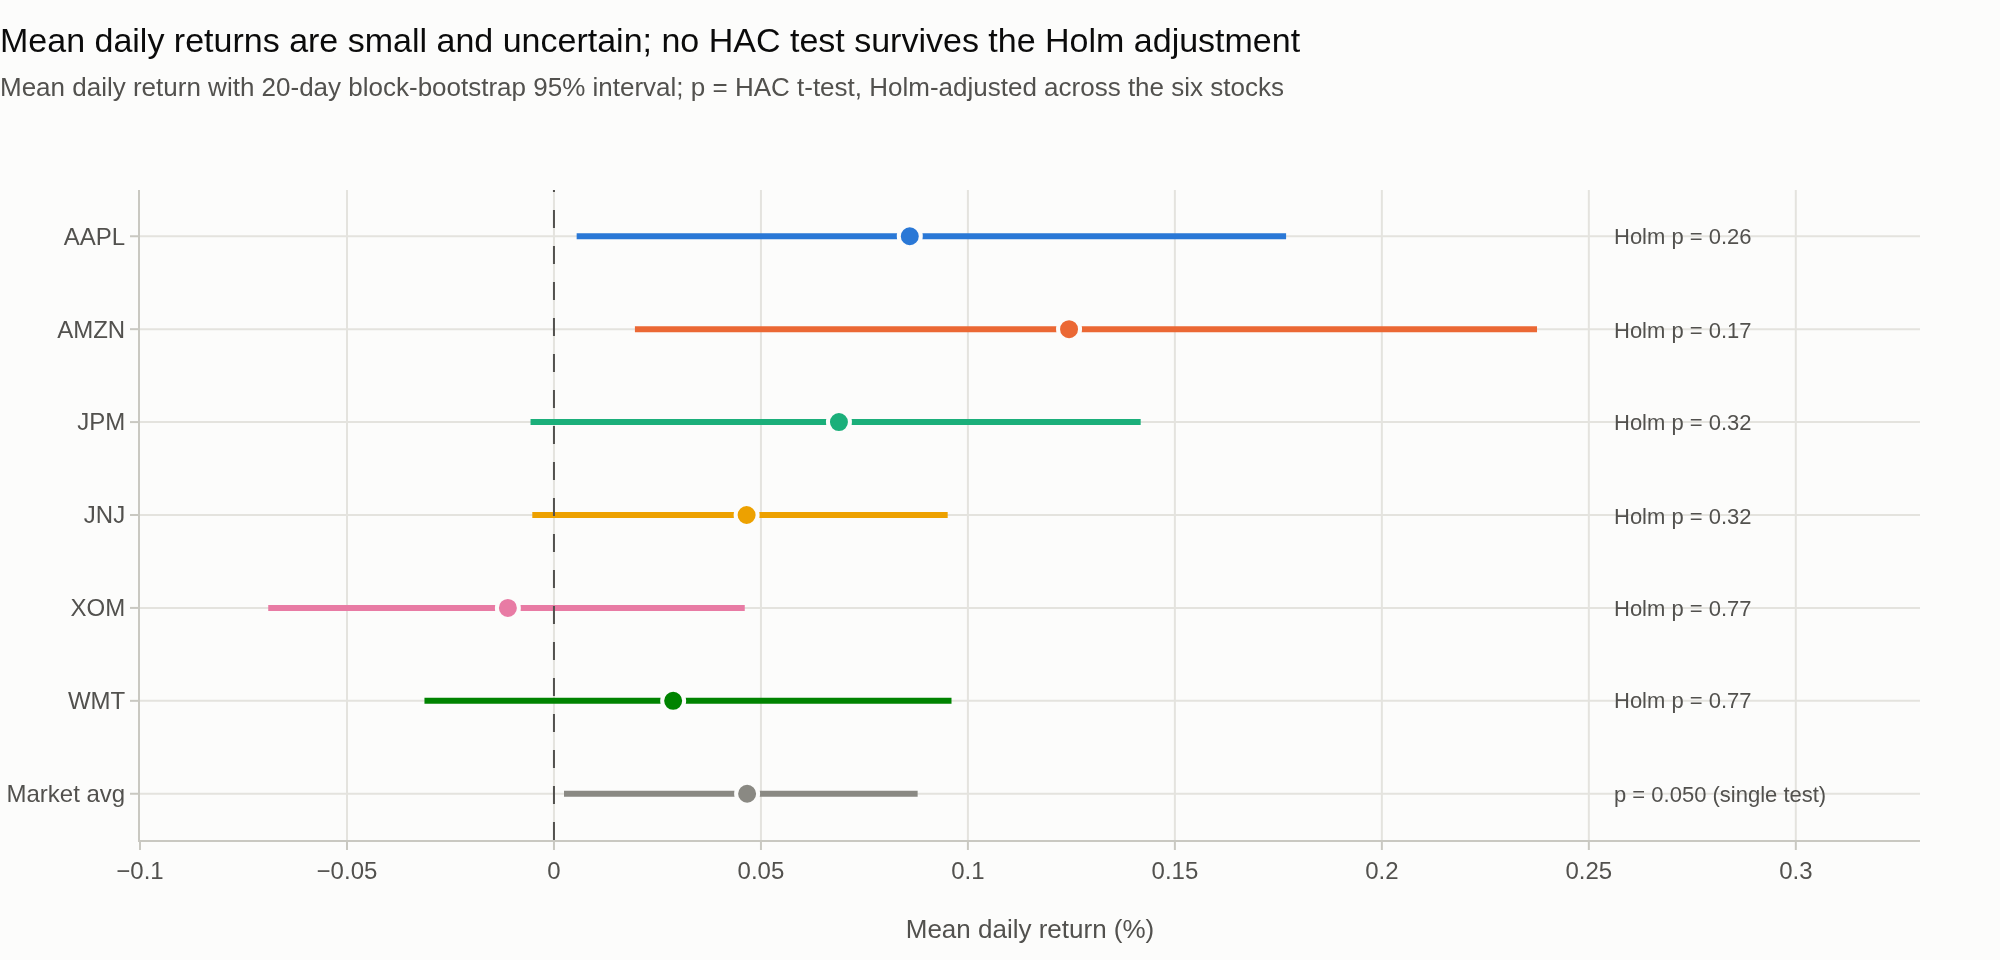

In [24]:
fig = go.Figure()
order = S + ["Market avg"]
for k, s in enumerate(order):
    row = h1.loc[s]
    fig.add_scatter(x=[row.boot_ci_low_pct, row.boot_ci_high_pct], y=[s, s], mode="lines",
                    line=dict(color=ch.color(s), width=3), showlegend=False, hoverinfo="skip")
    fig.add_scatter(x=[row.mean_daily_pct], y=[s], mode="markers", marker=dict(color=ch.color(s), size=11), showlegend=False,
                    hovertemplate=f"{s}: mean %{{x:.3f}}% (95% CI {row.boot_ci_low_pct:.3f} to {row.boot_ci_high_pct:.3f}); Holm p = {row.p_hac_holm if s in S else row.p_hac:.2f}<extra></extra>")
    fig.add_annotation(x=0.255, y=s, text=(f"Holm p = {row.p_hac_holm:.2f}" if s in S else f"p = {row.p_hac:.3f} (single test)"), showarrow=False, xanchor="left",
                       font=dict(size=11, color=ch.TEXT_2))
fig.add_vline(x=0, line=dict(color=ch.TEXT_2, width=1, dash="dash"))
fig.update_yaxes(autorange="reversed", categoryorder="array", categoryarray=order)
fig.update_layout(title=ch.title("Mean daily returns are small and uncertain; no HAC test survives the Holm adjustment",
                                 "Mean daily return with 20-day block-bootstrap 95% interval; p = HAC t-test, Holm-adjusted across the six stocks"),
                  xaxis_title="Mean daily return (%)", xaxis_range=[-0.1, 0.33], margin_r=40)
ch.save(fig, "09_mean_return_confidence_intervals", height=480)

**Result.** On the main (HAC) test, no stock's mean daily return is significantly different from zero after the Holm adjustment (smallest adjusted p = 0.17, AMZN; unadjusted p = 0.028). **We do not reject H₀ for any stock.** The bootstrap intervals agree for four stocks, but those for AMZN and AAPL just exclude zero (lower bounds 0.020% and 0.006%). The rank-based Wilcoxon test is significant for AMZN even after Holm (p = 0.048) and for AAPL before it (p = 0.019; Holm p = 0.097). So there is **weak, borderline evidence** that AMZN's returns were centred above zero, and none for the other stocks. The equal-weighted market average (one test, no adjustment) is borderline too: HAC p = 0.0497.

**Interpretation, and why this is not a contradiction.** AMZN nearly tripled, yet its mean daily return is at best borderline significant. Daily returns are small relative to their noise: AMZN's mean of 0.12% sits against a daily SD of 1.9%, an effect size of d = 0.06. With 1,006 days, a test at 80% power can only detect a true mean of about 0.16% a day for AMZN (about 0.08% for JNJ). That is roughly 40% a year for AMZN, more than it actually earned. **Not rejecting H₀ does not mean the true mean is zero. It means four years of daily data cannot tell a good stock from a lucky one.** Historical average returns are therefore weak evidence about future returns.

**Assumptions and limitations.** The HAC test assumes the mean was stable over the four years. The bootstrap assumes dependence lasts less than about 20 days. Results use price returns (without dividends), which slightly understate the mean for dividend payers.

### 5.2 Hypothesis 2: Is trading volume related to daily returns?
* **H₀:** there is no monotonic relationship between trading volume and daily returns. **H₁:** there is one.
* Volume trends over time (5.2 uses **relative volume**: the day's volume ÷ the median of the previous 20 days, logged, so trends and level differences drop out). It is tested against (a) the **signed return** (does high volume go with rises or with falls?) and (b) the **absolute return** (does high volume go with large moves in either direction?).
* **Test:** **Spearman's ρ**, because the relationship need not be linear and returns have extreme tails. Relative volume is autocorrelated, so p-values use an **effective sample size** (Pyper & Peterman 1998) rather than n. Holm adjustment across the six stocks for each version.

In [25]:
h2 = []
for s in S:
    d = sel[(sel.symbol == s) & sel.valid_return & sel.rel_volume.notna()]
    lv = np.log(d.rel_volume.values)
    a = sp.corr_test(lv, d.pct_return.values, "spearman"); b = sp.corr_test(lv, d.pct_return.abs().values, "spearman")
    c_ = sp.corr_test(np.log(d.volume_clean.values), d.pct_return.abs().values, "spearman")
    h2.append({"symbol": s, "n": a["n"], "rho_signed": a["r"], "p_signed_adj": a["p_adjusted"], "n_eff_signed": a["n_eff"],
               "rho_abs": b["r"], "ci_low_abs": b["ci_low"], "ci_high_abs": b["ci_high"], "p_abs_adj": b["p_adjusted"], "n_eff_abs": b["n_eff"],
               "rho_abs_raw_volume": c_["r"], "n_eff_raw_volume": c_["n_eff"], "p_abs_raw_volume_adj": c_["p_adjusted"]})
h2 = pd.DataFrame(h2).set_index("symbol")
h2["p_signed_holm"] = sp.holm(h2.p_signed_adj); h2["p_abs_holm"] = sp.holm(h2.p_abs_adj)
h2["strength_abs"] = h2.rho_abs.map(sp.strength_label); h2["strength_signed"] = h2.rho_signed.map(sp.strength_label)
h2.to_csv(OUT / "h2_volume_return_tests.csv")
display(h2[["n", "rho_signed", "p_signed_holm", "strength_signed", "rho_abs", "ci_low_abs", "ci_high_abs", "p_abs_holm", "strength_abs",
            "n_eff_abs", "rho_abs_raw_volume", "n_eff_raw_volume"]])

,n,rho_signed,p_signed_holm,strength_signed,rho_abs,ci_low_abs,ci_high_abs,p_abs_holm,strength_abs,n_eff_abs,rho_abs_raw_volume,n_eff_raw_volume
symbol,,,,,,,,,,,,
AAPL,992,-0.0430,0.5283,negligible,0.4577,0.4000,0.5118,0.0000,moderate positive,851.2150,0.4429,215.9503
AMZN,992,-0.0329,0.6015,negligible,0.4567,0.3982,0.5115,0.0000,moderate positive,829.2453,0.5007,568.4436
JPM,992,-0.0502,0.4565,negligible,0.4497,0.3902,0.5054,0.0000,moderate positive,812.9122,0.5157,636.1031
JNJ,992,-0.0537,0.4559,negligible,0.4202,0.3580,0.4786,0.0000,moderate positive,780.9795,0.4476,402.6929
XOM,992,-0.0175,0.6015,negligible,0.3466,0.2860,0.4044,0.0000,moderate positive,901.0377,0.4747,324.2006
WMT,992,-0.0637,0.2688,negligible,0.3886,0.3299,0.4442,0.0000,moderate positive,914.2576,0.4267,490.7200


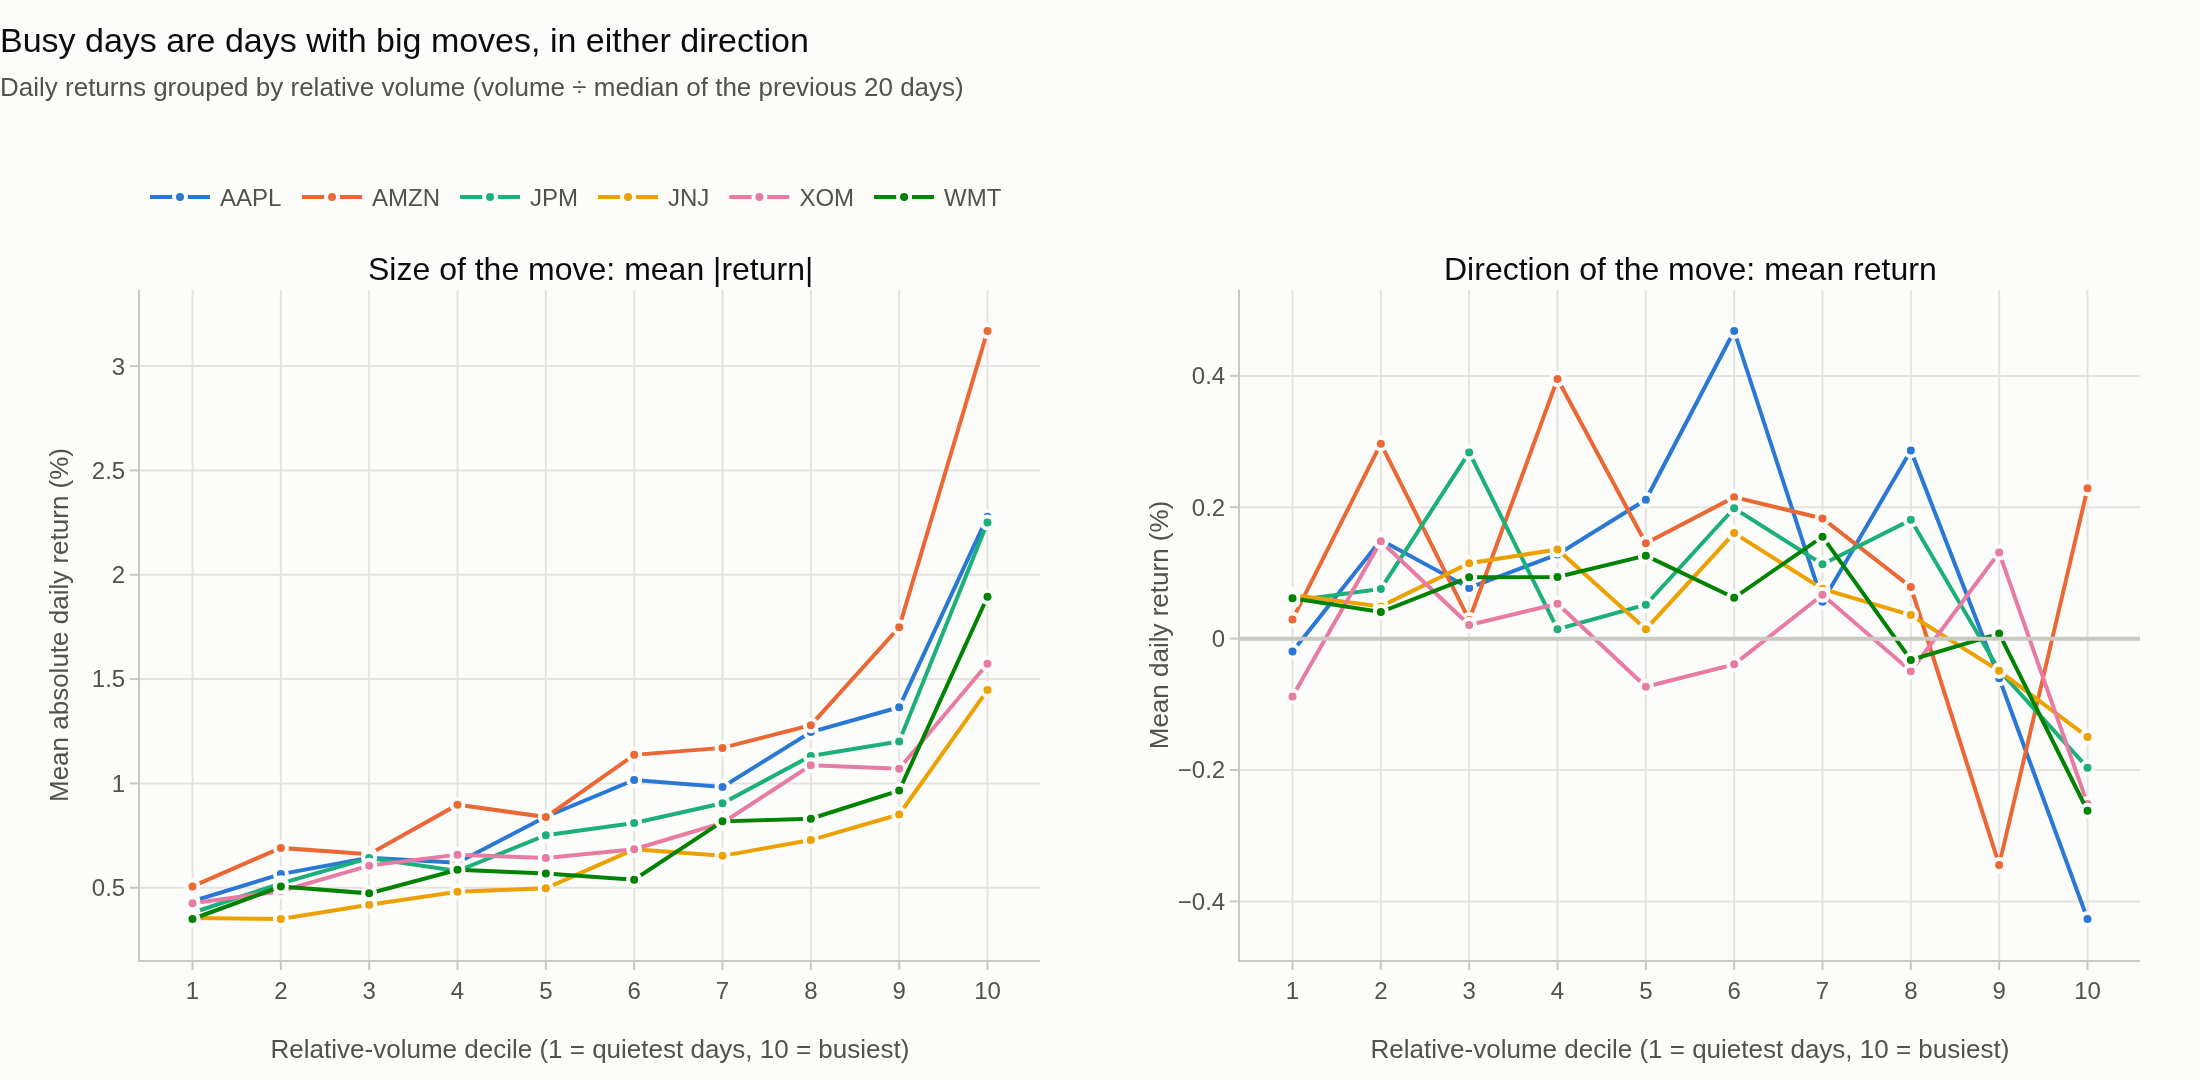

In [26]:
fig = make_subplots(rows=1, cols=2, subplot_titles=["Size of the move: mean |return|", "Direction of the move: mean return"],
                    horizontal_spacing=0.1)
for s in S:
    d = sel[(sel.symbol == s) & sel.valid_return & sel.rel_volume.notna()].copy()
    d["decile"] = pd.qcut(d.rel_volume.rank(method="first"), 10, labels=range(1, 11))
    g = d.groupby("decile", observed=True).pct_return
    fig.add_scatter(x=list(range(1, 11)), y=100 * g.apply(lambda x: x.abs().mean()), name=s, line=dict(color=ch.color(s)),
                    mode="lines+markers", marker=dict(size=6), legendgroup=s, row=1, col=1)
    fig.add_scatter(x=list(range(1, 11)), y=100 * g.mean(), name=s, line=dict(color=ch.color(s)), mode="lines+markers",
                    marker=dict(size=6), legendgroup=s, showlegend=False, row=1, col=2)
fig.add_hline(y=0, line=dict(color=ch.AXIS), row=1, col=2)
fig.update_xaxes(title_text="Relative-volume decile (1 = quietest days, 10 = busiest)", dtick=1)
fig.update_yaxes(title_text="Mean absolute daily return (%)", row=1, col=1)
fig.update_yaxes(title_text="Mean daily return (%)", row=1, col=2)
fig.update_layout(title=ch.title("Busy days are days with big moves, in either direction",
                                 "Daily returns grouped by relative volume (volume ÷ median of the previous 20 days)"))
ch.save(fig, "10_volume_vs_returns", width=1100, height=540)

**Result.**
* **Direction (signed return):** ρ is between −0.06 and −0.02, negligible for every stock, and no Holm-adjusted p-value is below 0.05 (WMT's unadjusted p is 0.045). **Do not reject H₀**: high volume does not systematically go with rises or with falls.
* **Size (absolute return):** ρ = 0.35 (XOM) to 0.46 (AAPL, AMZN), a **moderate positive** relationship, with every Holm-adjusted p < 10⁻²⁵ and every 95% interval well above zero. **Reject H₀**: days with unusually high volume are days with unusually large price moves. The busiest tenth of days have average moves **3.7 to 6.3 times** the size of the quietest tenth's.
* Raw (unadjusted) volume gives similar ρ values, but its effective sample size is much smaller (216 to 636 rather than about 800 to 900) because raw volume trends, so the relative-volume version is the cleaner test.

**Interpretation.** Volume measures how much the market is reacting, not which way. A volume spike signals a large move or new information. It does not predict direction. The relationship is same-day and is an association, not a cause in either direction.

### 5.3 Hypothesis 3: Do the stocks' return distributions differ?
A distribution can differ in **location** (typical return) or in **spread** (volatility). Both are tested.
* **H₀ (location):** the six stocks' daily returns have the same typical level. **H₁:** at least one differs. **Test:** the **Friedman test** with each trading day as a block. The six returns on a day are **not independent** (they share market moves), and Friedman compares the stocks within each day, which is what the design requires. Kruskal-Wallis (which assumes independent groups) is shown for comparison. Effect size: Kendall's W.
* **H₀ (spread):** the six stocks have equal variability of daily returns. **H₁:** at least one differs. **Tests:** **Brown-Forsythe** (Levene's test centred on the median, robust to fat tails), plus a Friedman test on each day's absolute deviations from each stock's median, which respects the pairing by day. Pairwise: **Wilcoxon signed-rank** tests on the paired absolute deviations, Holm-adjusted over 15 pairs, and 20-day block-bootstrap intervals for each stock's annualised volatility.

In [27]:
fr = stats.friedmanchisquare(*[R[s] for s in S]); kw = stats.kruskal(*[R[s] for s in S])
absdev = (R - R.median()).abs()
bf = stats.levene(*[R[s] for s in S], center="median"); fr_s = stats.friedmanchisquare(*[absdev[s] for s in S])
n = len(R)
h3 = pd.DataFrame([
    ("Location", "Friedman (days as blocks)", fr.statistic, fr.pvalue, "Kendall's W", sp.kendalls_w(fr.statistic, n, 6)),
    ("Location", "Kruskal-Wallis (assumes independence)", kw.statistic, kw.pvalue, "epsilon²", sp.epsilon_squared(kw.statistic, 6 * n)),
    ("Spread", "Brown-Forsythe (Levene, median)", bf.statistic, bf.pvalue, "ratio of largest to smallest SD", R.std().max() / R.std().min()),
    ("Spread", "Friedman on |return − median| (days as blocks)", fr_s.statistic, fr_s.pvalue, "Kendall's W", sp.kendalls_w(fr_s.statistic, n, 6)),
], columns=["aspect", "test", "statistic", "p_value", "effect_size_measure", "effect_size"])
h3["decision_5pct"] = np.where(h3.p_value < ALPHA, "Reject H0", "Do not reject H0")
h3.to_csv(OUT / "h3_distribution_tests.csv", index=False)
display(h3)

mean_rank = R.rank(axis=1).mean().rename("mean_rank_within_day")
display(mean_rank.to_frame().T)

pairs = []
for i, a in enumerate(S):
    for b in S[i + 1:]:
        w = stats.wilcoxon(absdev[a], absdev[b])
        from_rb = stats.rankdata(np.abs((absdev[a] - absdev[b])[absdev[a] != absdev[b]]))
        dd_ = (absdev[a] - absdev[b])[absdev[a] != absdev[b]]
        rb = (from_rb[dd_.values > 0].sum() - from_rb[dd_.values < 0].sum()) / from_rb.sum()
        pairs.append({"stock_a": a, "stock_b": b, "sd_ratio_a_over_b": R[a].std() / R[b].std(), "wilcoxon_p": w.pvalue, "rank_biserial": rb})
pairs = pd.DataFrame(pairs); pairs["p_holm"] = sp.holm(pairs.wilcoxon_p)
# direction from the tested quantity (typical absolute deviation): rank-biserial > 0 means stock_a moves more
pairs["larger_typical_move"] = np.where(pairs.p_holm < ALPHA, np.where(pairs.rank_biserial > 0, pairs.stock_a, pairs.stock_b), "no significant difference")
pairs.to_csv(OUT / "h3_pairwise_volatility.csv", index=False)
display(pairs.sort_values("p_holm"))

,aspect,test,statistic,p_value,effect_size_measure,effect_size,decision_5pct
0,Location,Friedman (days as blocks),13.8686,0.0165,Kendall's W,0.0028,Reject H0
1,Location,Kruskal-Wallis (assumes independence),7.8764,0.1632,epsilon²,0.0013,Do not reject H0
2,Spread,"Brown-Forsythe (Levene, median)",42.2084,0.0000,ratio of largest to smallest SD,2.0970,Reject H0
3,Spread,Friedman on |return − median| (days as blocks),204.8072,0.0000,Kendall's W,0.0407,Reject H0


symbol,AAPL,AMZN,JPM,JNJ,XOM,WMT
mean_rank_within_day,3.5726,3.6213,3.5184,3.4930,3.3390,3.4558


,stock_a,stock_b,sd_ratio_a_over_b,wilcoxon_p,rank_biserial,p_holm,larger_typical_move
6,AMZN,JNJ,2.0970,0.0000,0.4947,0.0000,AMZN
8,AMZN,WMT,1.6318,0.0000,0.3818,0.0000,AMZN
2,AAPL,JNJ,1.6093,0.0000,0.3573,0.0000,AAPL
7,AMZN,XOM,1.6497,0.0000,0.3340,0.0000,AMZN
9,JPM,JNJ,1.4562,0.0000,0.3309,0.0000,JPM
4,AAPL,WMT,1.2523,0.0000,0.2774,0.0000,AAPL
5,AMZN,JPM,1.4401,0.0000,0.2235,0.0000,AMZN
11,JPM,WMT,1.1331,0.0000,0.2024,0.0000,JPM
3,AAPL,XOM,1.2660,0.0000,0.1957,0.0000,AAPL
12,JNJ,XOM,0.7867,0.0000,-0.1706,0.0000,XOM


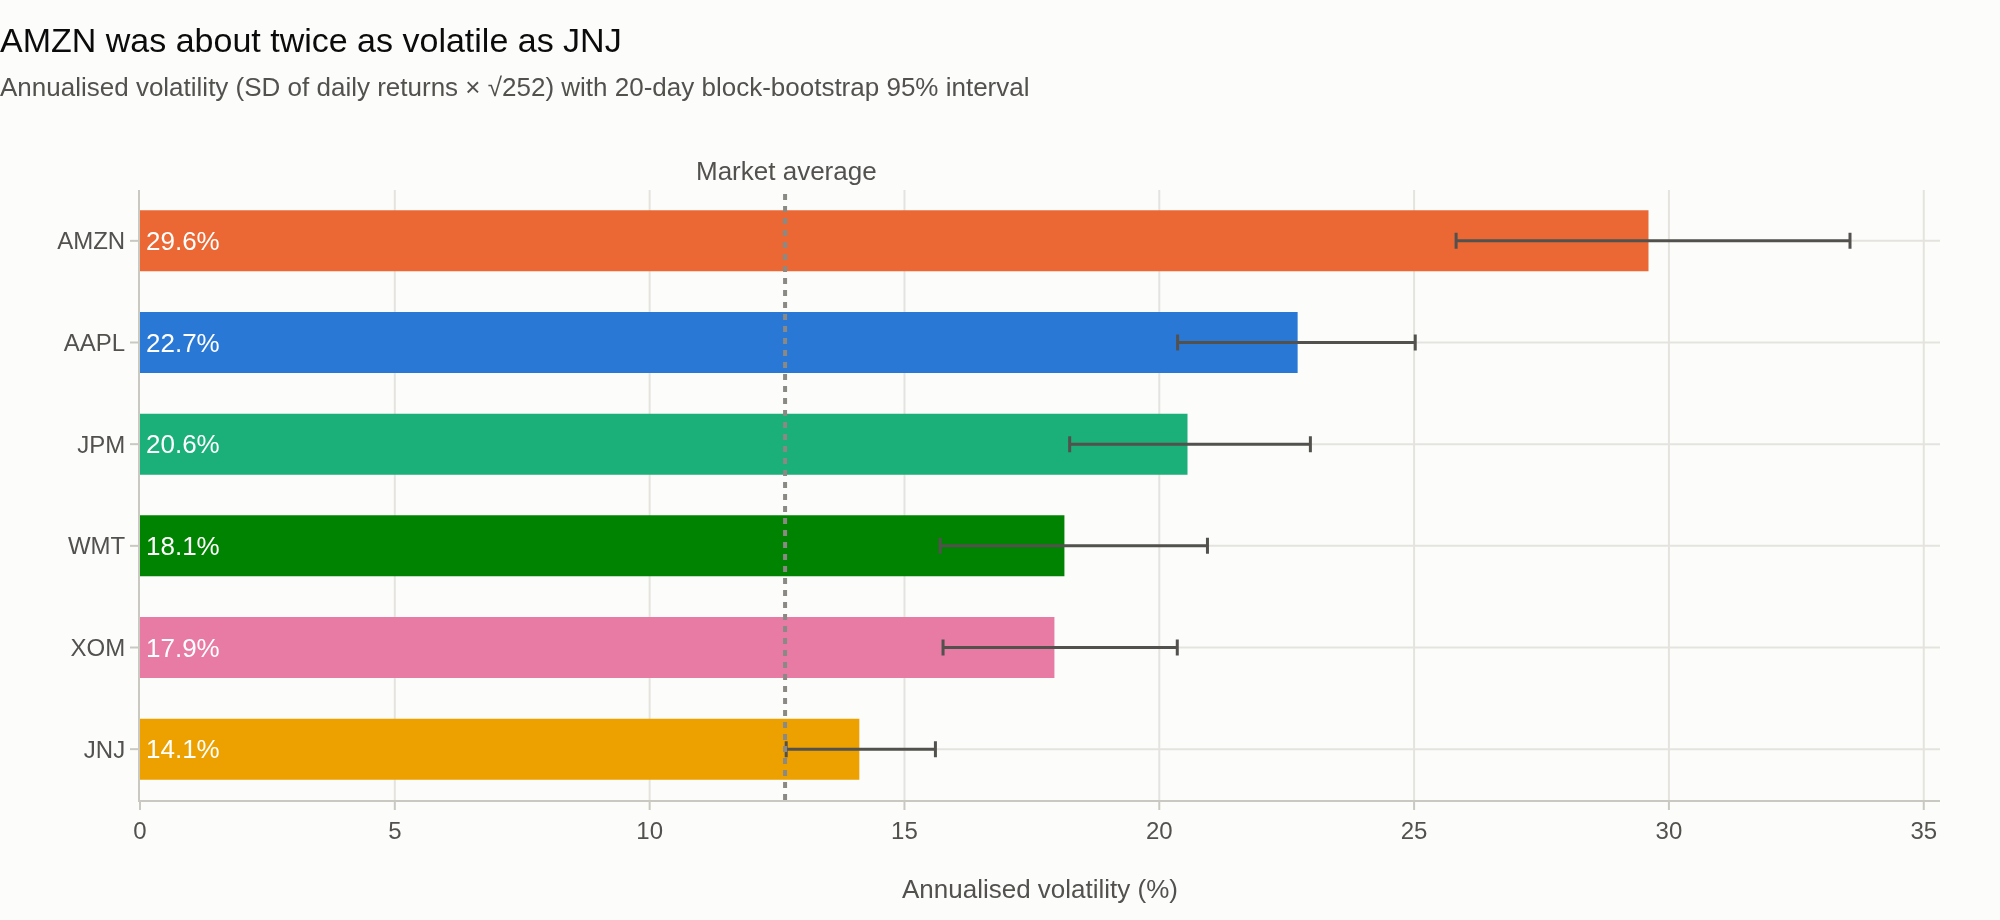

In [28]:
vol_ci = {}
for s in S:
    b = sp.block_bootstrap(R[s].values, lambda a: a.std(ddof=1) * np.sqrt(252), block=20, n_boot=2000, seed=SEED)
    vol_ci[s] = (R[s].std() * np.sqrt(252), *sp.percentile_ci(b))
vci = pd.DataFrame(vol_ci, index=["ann_vol", "ci_low", "ci_high"]).T.sort_values("ann_vol")
vci.to_csv(OUT / "volatility_bootstrap_ci.csv")
fig = go.Figure()
for s in vci.index:
    v, lo_, hi_ = vci.loc[s]
    fig.add_bar(x=[100 * v], y=[s], orientation="h", marker_color=ch.color(s), showlegend=False, width=0.6,
                error_x=dict(type="data", symmetric=False, array=[100 * (hi_ - v)], arrayminus=[100 * (v - lo_)], color=ch.TEXT_2, thickness=1.5),
                text=[f"{100 * v:.1f}%"], textposition="inside", insidetextanchor="start", textfont=dict(color="white"),
                hovertemplate=f"{s}: {100 * v:.1f}% (95% CI {100 * lo_:.1f} to {100 * hi_:.1f})<extra></extra>")
fig.add_vline(x=100 * mret.std() * np.sqrt(252), line=dict(color=ch.MARKET_COLOR, dash="dot", width=2),
              annotation_text="Market average", annotation_position="top", annotation_font_color=ch.TEXT_2)
fig.update_layout(title=ch.title("AMZN was about twice as volatile as JNJ",
                                 "Annualised volatility (SD of daily returns × √252) with 20-day block-bootstrap 95% interval"),
                  xaxis_title="Annualised volatility (%)", bargap=0.3)
ch.save(fig, "11_volatility_comparison", height=460)

**Result: location.** The Friedman test gives p = 0.016, so formally **H₀ is rejected**. But the effect is negligible (Kendall's W = 0.003), and the Kruskal-Wallis test, which ignores the pairing, does not reject (p = 0.16). Within a typical day the stocks' ranks hardly differ. The small difference comes from AMZN and AAPL ranking slightly higher on average over four years. In practical terms, the stocks **do not differ meaningfully in their typical daily return**.

**Result: spread.** Both tests reject equal volatility decisively (Brown-Forsythe p < 10⁻⁴⁰; paired Friedman p < 10⁻⁴⁰). **Reject H₀**: the stocks differ clearly in risk. Pairwise, **14 of 15 pairs** differ after the Holm adjustment; only AAPL against JPM does not. XOM and WMT have almost the same SD (ratio 0.99), but XOM's typical day moves more, while WMT has bigger extreme days. By SD, the ordering from calmest to most volatile is **JNJ < XOM ≈ WMT < JPM ≈ AAPL < AMZN**, and the bootstrap intervals for JNJ and AMZN do not overlap any other stock's.

**Overall.** **The selected stocks differ in risk, not in average daily return.** For comparing these stocks, volatility is the reliable, statistically supported difference. Differences in average daily return are too small relative to noise to establish from four years of data.

**Assumptions and limitations.** The Friedman test assumes days are exchangeable blocks. Volatility clustering makes days unequal, but the comparison is within each day, which limits the impact. The Brown-Forsythe test assumes independent groups, which is why the paired test is also reported.

### 5.4 Hypothesis 4: Do returns depend on their own past (autocorrelation and volatility clustering)?
* **H₀ (returns):** daily returns are not autocorrelated up to lag 10. **H₁:** some autocorrelation at lags 1 to 10. **Test:** **Ljung-Box** on returns.
* **H₀ (volatility):** there is no volatility clustering (squared returns are not autocorrelated). **H₁:** large moves tend to follow large moves. **Tests:** **Ljung-Box** on squared returns (lag 10) and Engle's **ARCH-LM** test (5 lags).

In [29]:
h4 = []
for s in S + ["Market avg"]:
    r = (R[s] if s in S else mret)
    lb = acorr_ljungbox(r, lags=[10]); lb2 = acorr_ljungbox(r ** 2, lags=[10]); arch = het_arch(r, nlags=5)
    h4.append({"symbol": s, "acf_lag1": sp.acf(r.values, 1)[1], "ljungbox_r_stat": lb.lb_stat.iloc[0], "ljungbox_r_p": lb.lb_pvalue.iloc[0],
               "acf_sq_lag1": sp.acf((r ** 2).values, 1)[1], "ljungbox_r2_stat": lb2.lb_stat.iloc[0], "ljungbox_r2_p": lb2.lb_pvalue.iloc[0],
               "arch_lm_stat": arch[0], "arch_lm_p": arch[1]})
h4 = pd.DataFrame(h4).set_index("symbol")
for c in ["ljungbox_r_p", "ljungbox_r2_p", "arch_lm_p"]:
    h4[c.replace("_p", "_p_holm")] = np.r_[sp.holm(h4.loc[S, c]), np.nan]
h4.to_csv(OUT / "h4_autocorrelation_volatility_clustering.csv")
display(h4)

,acf_lag1,ljungbox_r_stat,ljungbox_r_p,acf_sq_lag1,ljungbox_r2_stat,ljungbox_r2_p,arch_lm_stat,arch_lm_p,ljungbox_r_p_holm,ljungbox_r2_p_holm,arch_lm_p_holm
symbol,,,,,,,,,,,
AAPL,0.0209,6.1975,0.7984,0.0589,20.2746,0.0268,11.0925,0.0496,1.0000,0.0803,0.1487
AMZN,0.0295,11.8941,0.2922,0.0617,6.7779,0.7462,4.8523,0.4342,1.0000,1.0000,0.8683
JPM,0.0160,10.5011,0.3977,0.1912,82.7518,0.0000,45.9506,0.0000,1.0000,0.0000,0.0000
JNJ,-0.0598,18.4582,0.0477,0.1161,100.0251,0.0000,45.1828,0.0000,0.2863,0.0000,0.0000
XOM,-0.0226,11.6302,0.3106,0.1554,252.3956,0.0000,95.9232,0.0000,1.0000,0.0000,0.0000
WMT,-0.0325,9.4552,0.4895,0.0434,2.8958,0.9838,2.3765,0.7950,1.0000,1.0000,0.8683
Market avg,0.0031,11.1437,0.3464,0.3154,408.3463,0.0000,155.9086,0.0000,NaN,NaN,NaN


**Result.**
* **Returns:** no stock shows significant autocorrelation after the Holm adjustment. JNJ's unadjusted Ljung-Box p is 0.048, and its adjusted p is 0.29. Lag-1 autocorrelations are between −0.07 and +0.03. **Do not reject H₀**: past returns carry almost no linear information about the next day's return. Section 6.4 tests this out of sample.
* **Volatility:** JPM, JNJ and XOM, and the market average, show **strong volatility clustering** (Ljung-Box and ARCH-LM p < 0.001). AAPL shows weak evidence (not significant after Holm). For **AMZN and WMT** the tests do not reject. Their volatility is dominated by a few isolated large one-day moves, which are not followed by turbulent periods, so they do not register as clusters. **Reject H₀ for JPM, JNJ, XOM and the market.**

**Interpretation.** The **direction** of returns is close to unpredictable from their own past, but the **size** of returns is partly predictable for several stocks: calm periods and turbulent periods each persist. This is why rolling volatility (6.2) is informative, and why the ML track should forecast risk rather than expect much from direction.

### 5.5 Calendar effects (supporting check)
* **H₀:** the distribution of daily returns is the same on every weekday (and in every calendar month). **H₁:** it differs for at least one. **Test:** **Kruskal-Wallis** (rank-based, robust to fat tails), Holm-adjusted across the 12 tests (6 stocks × 2 calendar factors).

In [30]:
cal_t = []
for s in S:
    r = R[s]
    k1 = stats.kruskal(*[r[r.index.day_of_week == d] for d in range(5)])
    k2 = stats.kruskal(*[r[r.index.month == m] for m in range(1, 13)])
    cal_t += [{"symbol": s, "factor": "day of week", "H": k1.statistic, "p": k1.pvalue, "epsilon2": sp.epsilon_squared(k1.statistic, len(r))},
              {"symbol": s, "factor": "month", "H": k2.statistic, "p": k2.pvalue, "epsilon2": sp.epsilon_squared(k2.statistic, len(r))}]
cal_t = pd.DataFrame(cal_t); cal_t["p_holm"] = sp.holm(cal_t.p)
cal_t["decision_5pct"] = np.where(cal_t.p_holm < ALPHA, "Reject H0", "Do not reject H0")
cal_t.to_csv(OUT / "calendar_effect_tests.csv", index=False)
display(cal_t)

,symbol,factor,H,p,epsilon2,p_holm,decision_5pct
0,AAPL,day of week,11.4743,0.0217,0.0114,0.2606,Do not reject H0
1,AAPL,month,17.0668,0.1059,0.0170,1.0000,Do not reject H0
2,AMZN,day of week,0.8774,0.9278,0.0009,1.0000,Do not reject H0
3,AMZN,month,7.4041,0.7655,0.0074,1.0000,Do not reject H0
4,JPM,day of week,3.2475,0.5173,0.0032,1.0000,Do not reject H0
5,JPM,month,11.2556,0.4221,0.0112,1.0000,Do not reject H0
6,JNJ,day of week,2.8761,0.5788,0.0029,1.0000,Do not reject H0
7,JNJ,month,15.6028,0.1565,0.0155,1.0000,Do not reject H0
8,XOM,day of week,1.5859,0.8113,0.0016,1.0000,Do not reject H0
9,XOM,month,11.7092,0.3859,0.0117,1.0000,Do not reject H0


**Result.** None of the 12 tests is significant after the Holm adjustment. The smallest raw p-value is AAPL's day-of-week test (p = 0.02, Holm p = 0.26). **There is no supported day-of-week or month-of-year effect** in these stocks' returns over 2014 to 2017. This matters for Section 6.3: a seasonal pattern in prices would need a seasonal pattern in returns, and there is none.

## 6. Time-series analysis

### 6.1 Stationarity: prices versus returns
Time-series methods (correlation, ACF, regression) assume a **stationary** series, one whose mean and variance do not drift. Two complementary tests: **ADF** (H₀: unit root, non-stationary) and **KPSS** (H₀: stationary). A series is called stationary when ADF rejects and KPSS does not.

In [31]:
st = []
for s in S + ["Market avg"]:
    lp = np.log(C[s]) if s in S else np.log(mkt.market_index)
    r = R[s] if s in S else mret
    for name, x, reg in [("log close", lp, "ct"), ("daily return", r, "c")]:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")   # KPSS warns when p lies outside its 0.01-0.10 table
            adf = adfuller(x, regression=reg, autolag="AIC"); kp = kpss(x, regression=reg, nlags="auto")
        verdict = ("stationary" if adf[1] < ALPHA and kp[1] >= ALPHA else
                   "non-stationary" if adf[1] >= ALPHA and kp[1] < ALPHA else "mixed")
        st.append({"symbol": s, "series": name, "adf_stat": adf[0], "adf_p": adf[1], "kpss_stat": kp[0], "kpss_p": kp[1], "conclusion": verdict})
st = pd.DataFrame(st)
st.to_csv(OUT / "stationarity_tests.csv", index=False)
display(st)
print("Note: KPSS p-values are reported within the table bounds 0.01–0.10; values at a bound mean 'at most'/'at least' that value.")

,symbol,series,adf_stat,adf_p,kpss_stat,kpss_p,conclusion
0,AAPL,log close,-1.6719,0.7630,0.5726,0.0100,non-stationary
1,AAPL,daily return,-31.0423,0.0000,0.0993,0.1000,stationary
2,AMZN,log close,-3.5704,0.0324,0.3149,0.0100,mixed
3,AMZN,daily return,-17.4170,0.0000,0.1642,0.1000,stationary
4,JPM,log close,-2.0467,0.5758,0.8125,0.0100,non-stationary
5,JPM,daily return,-16.9270,0.0000,0.1807,0.1000,stationary
6,JNJ,log close,-2.3560,0.4033,0.7052,0.0100,non-stationary
7,JNJ,daily return,-13.7966,0.0000,0.0536,0.1000,stationary
8,XOM,log close,-2.3164,0.4249,0.5769,0.0100,non-stationary
9,XOM,daily return,-18.1591,0.0000,0.0725,0.1000,stationary


Note: KPSS p-values are reported within the table bounds 0.01–0.10; values at a bound mean 'at most'/'at least' that value.


The **log price** series are **non-stationary**: for five stocks and the market average, ADF does not reject a unit root (p = 0.23 to 0.97) and KPSS rejects stationarity around a trend (p ≤ 0.01). AMZN is mixed (ADF p = 0.03 with a trend, KPSS still rejects), so it is not stationary either. Every **return** series is **stationary** (ADF p < 0.001, KPSS p ≥ 0.06). Prices wander, and returns fluctuate around a stable level. So **statistics and correlations are computed on returns, never on prices**. Two price series that both trend upwards will look highly correlated even when the companies are unrelated.

### 6.2 Daily returns and rolling volatility

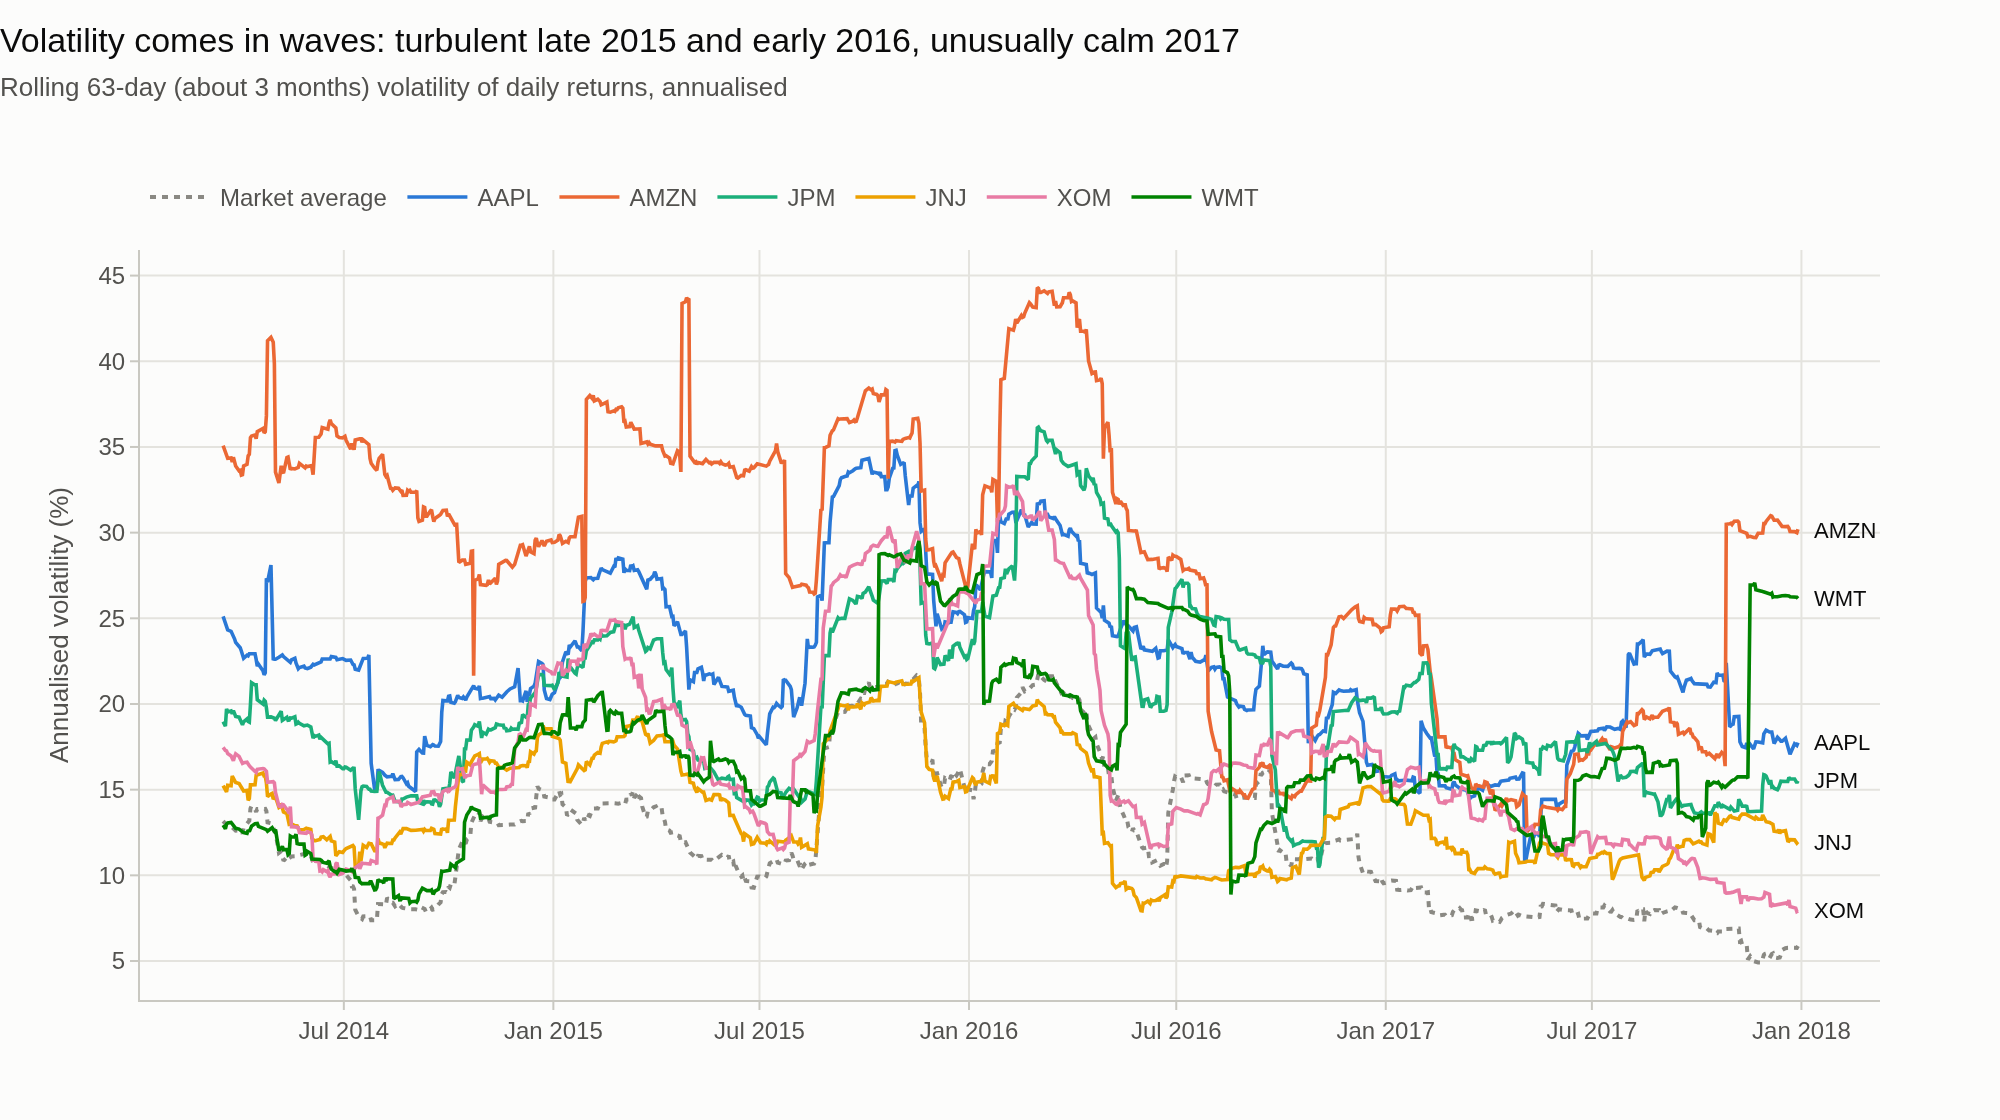

In [32]:
rv = R.rolling(63, min_periods=50).std() * np.sqrt(252)
mrv = mret.rolling(63, min_periods=50).std() * np.sqrt(252)
fig = go.Figure()
fig.add_scatter(x=mrv.index, y=100 * mrv, name="Market average", line=dict(color=ch.MARKET_COLOR, width=2, dash="dot"))
for s in S:
    fig.add_scatter(x=rv.index, y=100 * rv[s], name=s, line=dict(color=ch.color(s), width=1.8),
                    hovertemplate=f"{s} %{{x|%d %b %Y}}: %{{y:.1f}}%<extra></extra>")
ch.end_labels(fig, {s: (rv.index[-1], 100 * rv[s].iloc[-1]) for s in S})
fig.update_layout(title=ch.title("Volatility comes in waves: turbulent late 2015 and early 2016, unusually calm 2017",
                                 "Rolling 63-day (about 3 months) volatility of daily returns, annualised"),
                  yaxis_title="Annualised volatility (%)", margin_r=60)
ch.save(fig, "12_rolling_volatility", height=560)

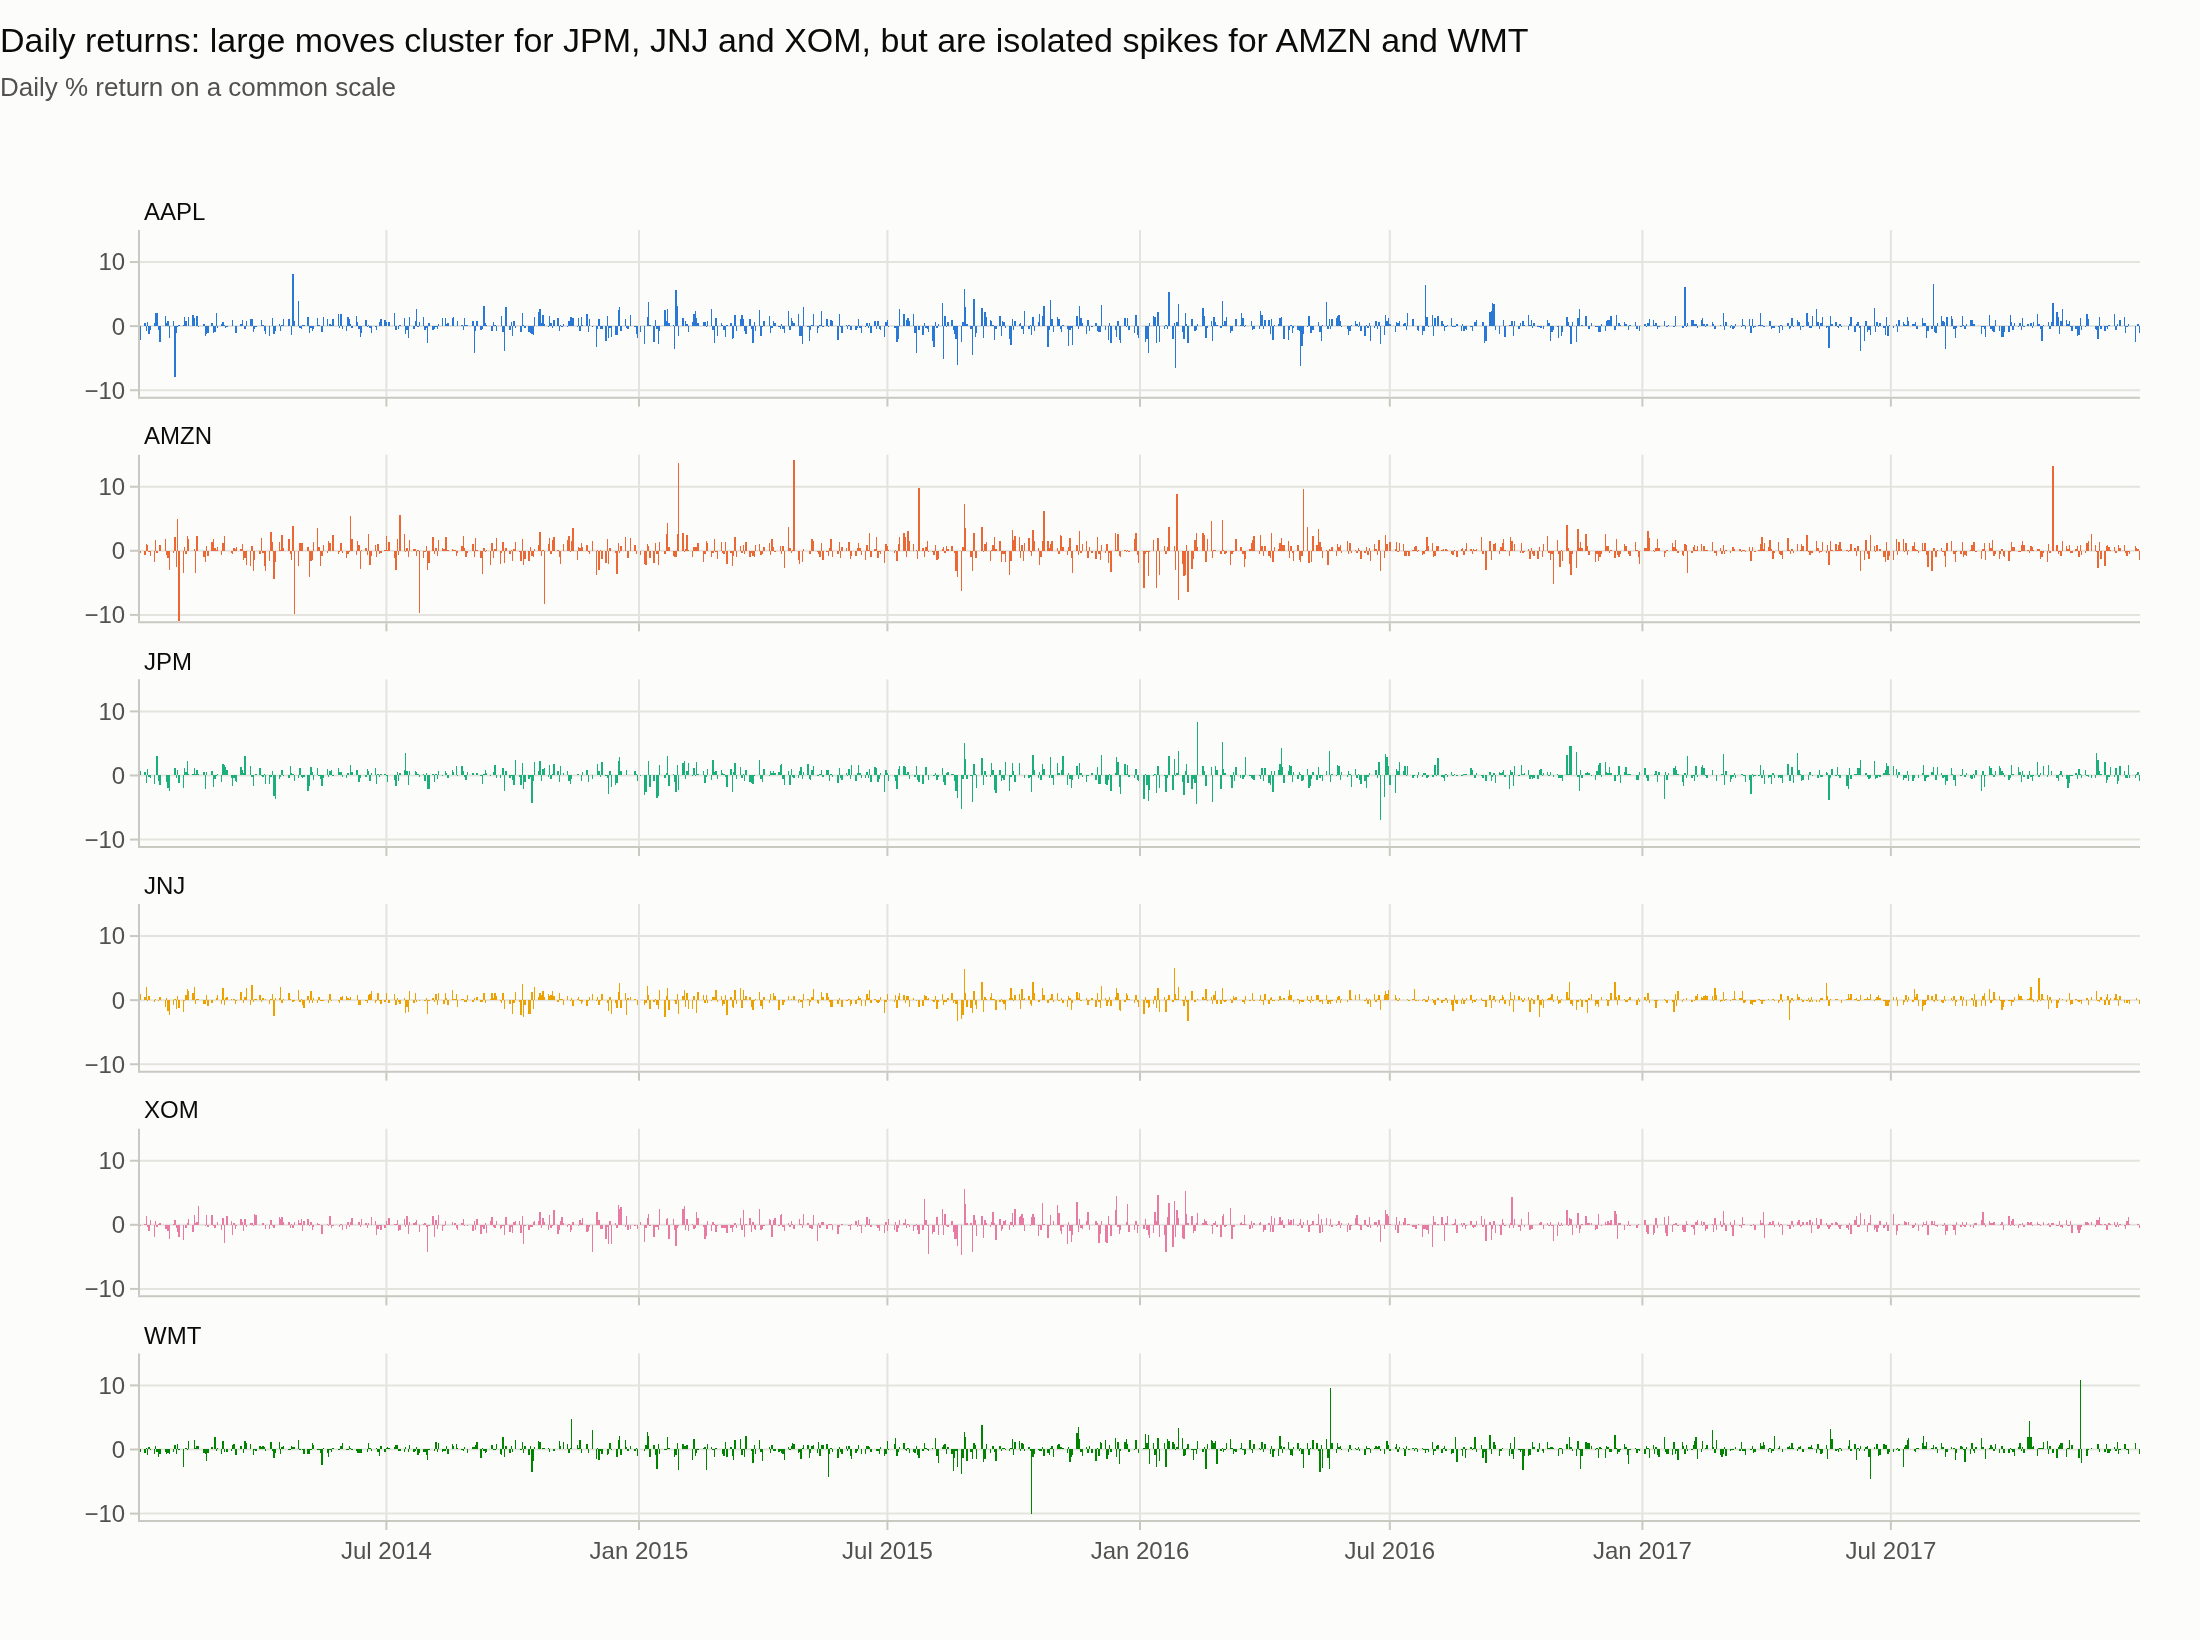

In [33]:
fig = make_subplots(rows=6, cols=1, shared_xaxes=True, vertical_spacing=0.045, subplot_titles=S)
for i, s in enumerate(S, start=1):
    fig.add_bar(x=R.index, y=100 * R[s], marker_color=ch.color(s), marker_line_width=0, showlegend=False, row=i, col=1,
                hovertemplate=f"{s} %{{x|%d %b %Y}}: %{{y:.2f}}%<extra></extra>")
    fig.update_yaxes(range=[-11, 15], dtick=10, row=i, col=1)
fig.update_layout(title=ch.title("Daily returns: large moves cluster for JPM, JNJ and XOM, but are isolated spikes for AMZN and WMT",
                                 "Daily % return on a common scale"), bargap=0)
fig.update_annotations(x=0.0, xanchor="left", font=dict(size=12, color=ch.TEXT))
ch.save(fig, "13_daily_returns_over_time", width=1100, height=820)

Rolling volatility shows the clustering found in 5.4. All six stocks and the market average became more volatile together in **August 2015 and January to February 2016**, and were unusually calm in **2017**, when the market average's rolling volatility fell below 5%. Stock-specific events add spikes on top: WMT in late 2015, AMZN around several large one-day moves.

**Interpretation.** A single volatility figure for 2014 to 2017 hides large swings. AMZN's 3-month volatility ranged from 13% to 44%, and XOM's from 8% to 33%. Risk measures should be reported for a stated window and refreshed regularly.

### 6.3 Decomposition: is there a stable trend and seasonal pattern?
**Method.** STL (Seasonal-Trend decomposition using LOESS, `statsmodels`) is applied to the **weekly log closing price** with an annual period (52 weeks), using the robust option so single extreme weeks do not distort the fit. The strength of each component is measured with Wang, Smith & Hyndman's (2006) index (0 = none, 1 = dominant). The brief warns that a decomposition can always be produced, so two checks follow: (1) the **seasonal strength**, and (2) whether the seasonal shape estimated for **2014–15 matches 2016–17**. A real seasonal pattern should repeat.

In [34]:
dec = []
stl_res = {}
for s in S + ["Market avg"]:
    x = (np.log(C[s]) if s in S else np.log(mkt.market_index)).resample("W-FRI").last()
    res = STL(x, period=52, robust=True).fit(); stl_res[s] = (x, res)
    seas = res.seasonal; wk = seas.index.isocalendar().week.values
    a = seas[seas.index.year <= 2015].groupby(wk[seas.index.year <= 2015]).mean()
    b = seas[seas.index.year >= 2016].groupby(wk[seas.index.year >= 2016]).mean()
    j = a.index.intersection(b.index)
    r = R[s] if s in S else mret
    mm = r.groupby([r.index.year, r.index.month]).sum().unstack()
    dec.append({"symbol": s, "weeks": len(x), "trend_strength": sp.trend_strength(res.trend, res.resid),
                "seasonal_strength": sp.seasonal_strength(res.seasonal, res.resid),
                "seasonal_range_log": seas.max() - seas.min(),
                "seasonal_shape_corr_2014_15_vs_2016_17": np.corrcoef(a[j], b[j])[0, 1],
                "monthly_return_rank_corr_2014_15_vs_2016_17": stats.spearmanr(mm.loc[[2014, 2015]].mean(), mm.loc[[2016, 2017]].mean()).statistic})
dec = pd.DataFrame(dec).set_index("symbol")
dec.to_csv(OUT / "decomposition_strength.csv")
display(dec)

,weeks,trend_strength,seasonal_strength,seasonal_range_log,seasonal_shape_corr_2014_15_vs_2016_17,monthly_return_rank_corr_2014_15_vs_2016_17
symbol,,,,,,
AAPL,209,0.5150,0.0000,0.4046,0.7230,0.1538
AMZN,209,0.9334,0.0000,0.5739,0.1028,-0.1399
JPM,209,0.8759,0.0488,0.1899,0.4154,0.1818
JNJ,209,0.8243,0.0045,0.1844,0.7758,0.4895
XOM,209,0.6134,0.1083,0.1886,0.1580,0.1608
WMT,209,0.1148,0.0000,0.3631,0.8993,-0.0070
Market avg,209,0.8836,0.0187,0.1010,0.2506,0.1608


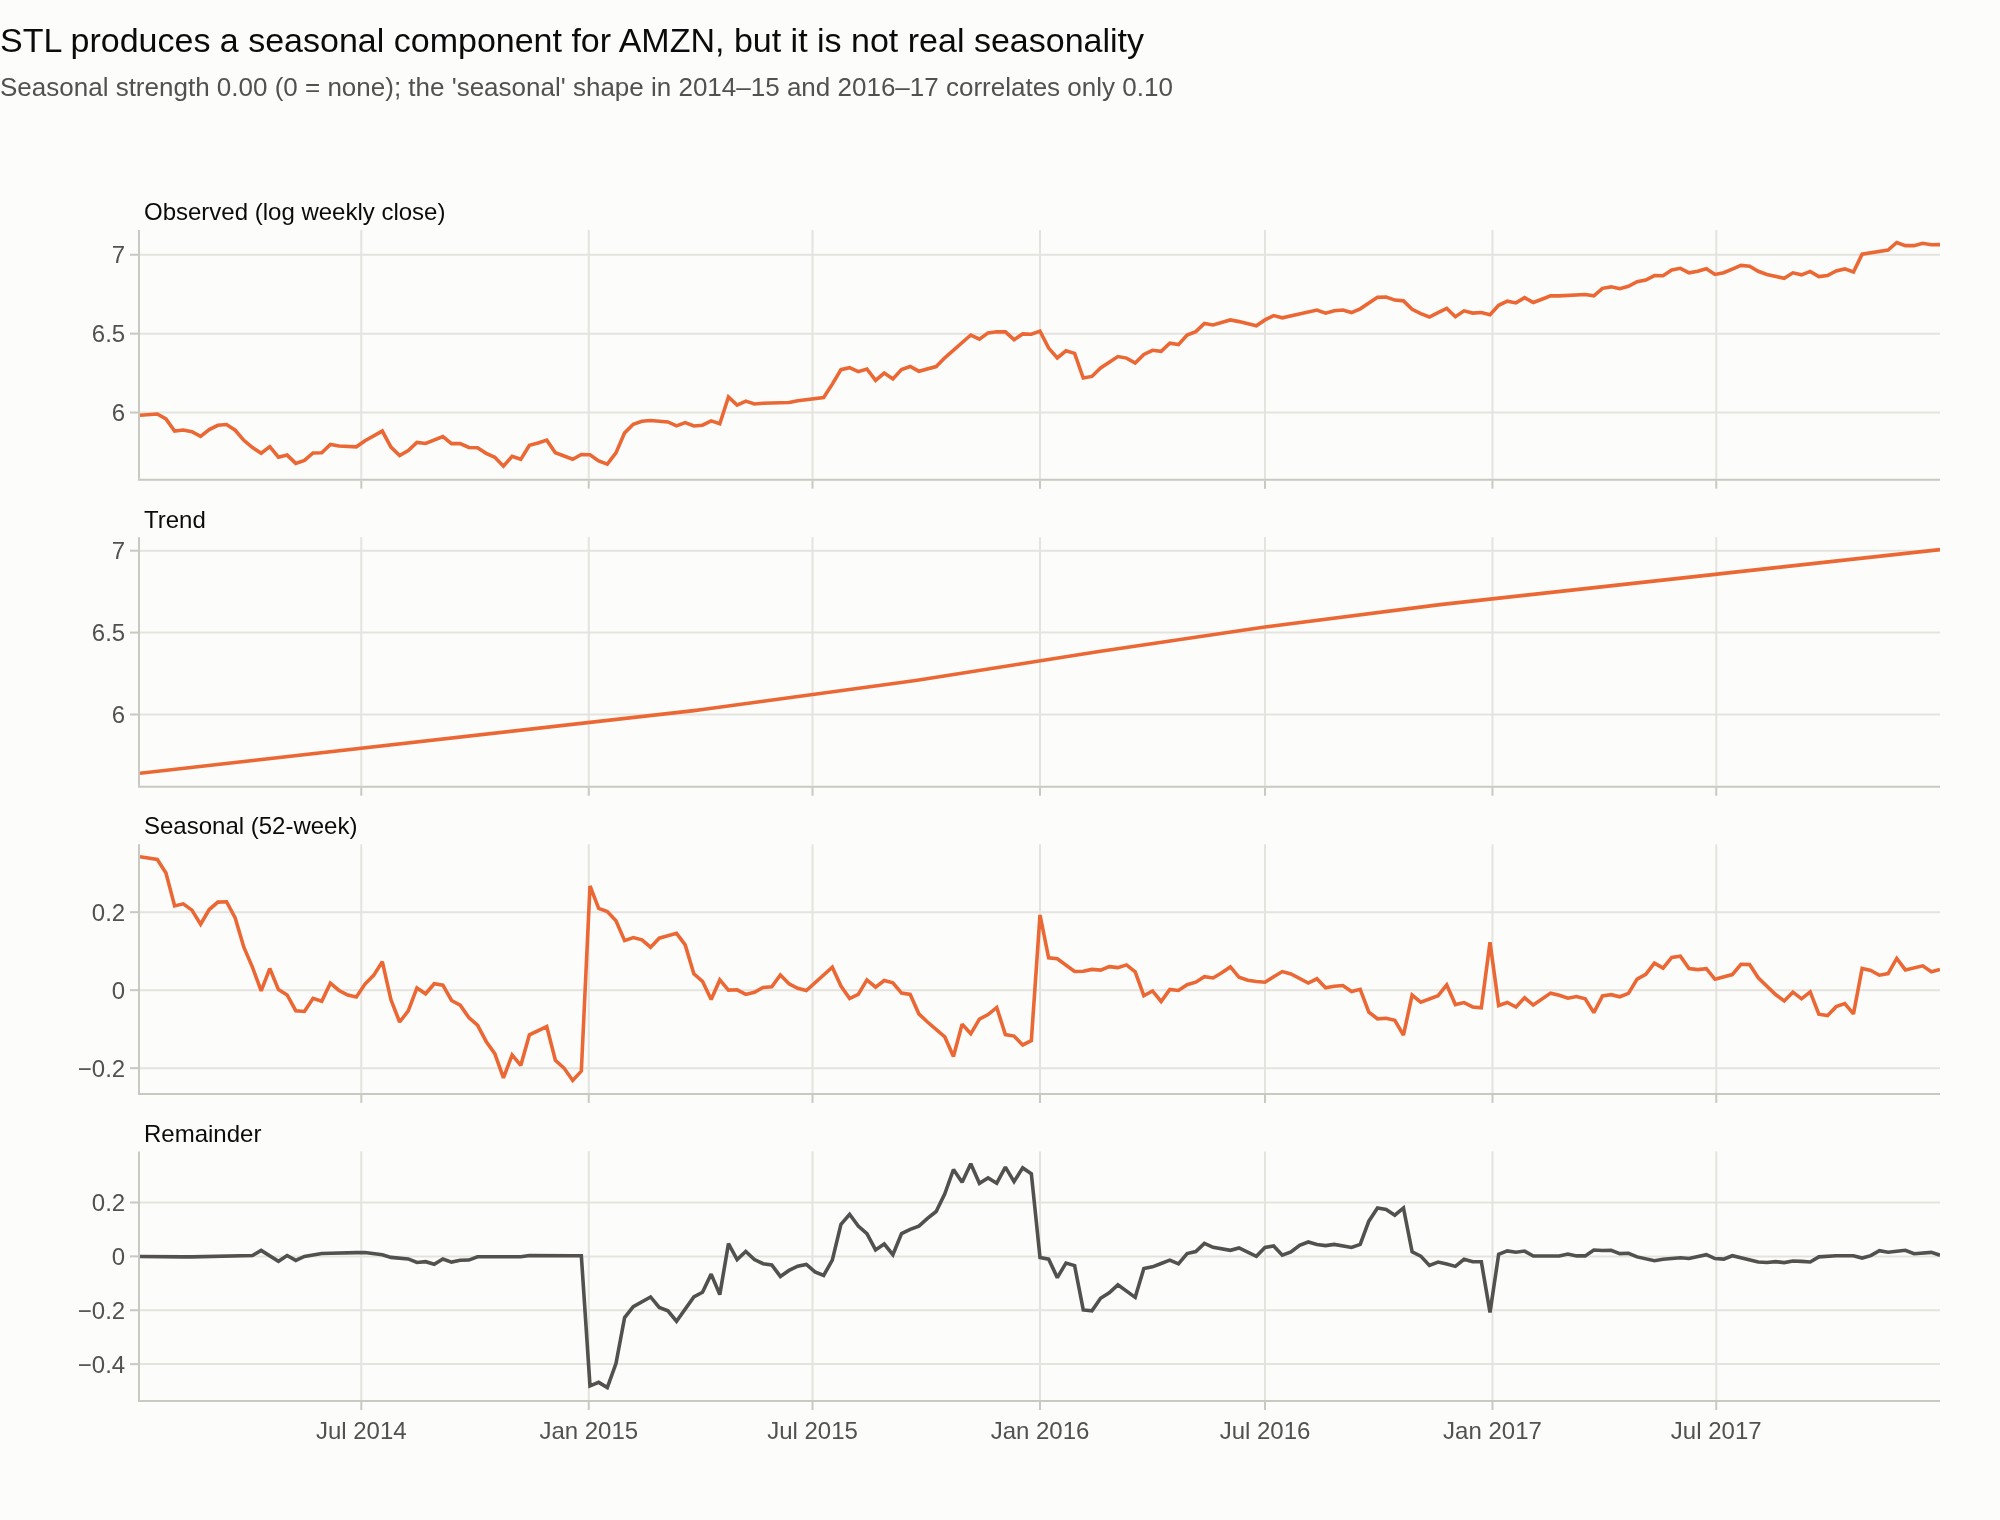

In [35]:
s0 = "AMZN"; x, res = stl_res[s0]
fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.05,
                    subplot_titles=["Observed (log weekly close)", "Trend", "Seasonal (52-week)", "Remainder"])
for i, (y, nm) in enumerate([(x, "Observed"), (res.trend, "Trend"), (res.seasonal, "Seasonal"), (res.resid, "Remainder")], start=1):
    fig.add_scatter(x=x.index, y=y, line=dict(color=ch.color(s0) if i < 4 else ch.TEXT_2, width=1.8), name=nm, showlegend=False, row=i, col=1)
fig.update_annotations(x=0.0, xanchor="left", font=dict(size=12, color=ch.TEXT))
fig.update_layout(title=ch.title(f"STL produces a seasonal component for {s0}, but it is not real seasonality",
                                 f"Seasonal strength {dec.loc[s0, 'seasonal_strength']:.2f} (0 = none); the 'seasonal' shape in 2014–15 and 2016–17 correlates only {dec.loc[s0, 'seasonal_shape_corr_2014_15_vs_2016_17']:.2f}"))
ch.save(fig, "14_stl_decomposition_amzn", width=1000, height=760)

**Result.** **Trend** dominates most price series (trend strength 0.82 to 0.93 for AMZN, JPM, JNJ and the market average). **Seasonal strength is 0.00 to 0.11 for every stock**: once the trend is removed, the "seasonal" component explains almost nothing beyond the remainder. STL still draws a 52-week pattern (for AMZN with a range of 0.57 in log price, which looks large), but it is the trend's wiggles being fitted into a seasonal shape. The seasonal shapes from 2014–15 and 2016–17 do not agree consistently (correlations from 0.1 to 0.9, depending on how smooth the trend is), and month-of-year average returns in the two halves are uncorrelated (ρ between −0.14 and 0.49). Section 5.5 found no significant month effect.

**Conclusion.** Stock prices here have **no stable seasonal pattern**, so the decomposition is reported only to show this. **Trend + noise** describes them better. Four years give only four annual cycles, which is too few to establish annual seasonality even if it existed.

### 6.4 Autocorrelation and a test of next-day predictability
The ACF and PACF show how strongly returns (and squared returns, a measure of volatility) relate to their own past values. The shaded band is the 95% interval under "no autocorrelation".

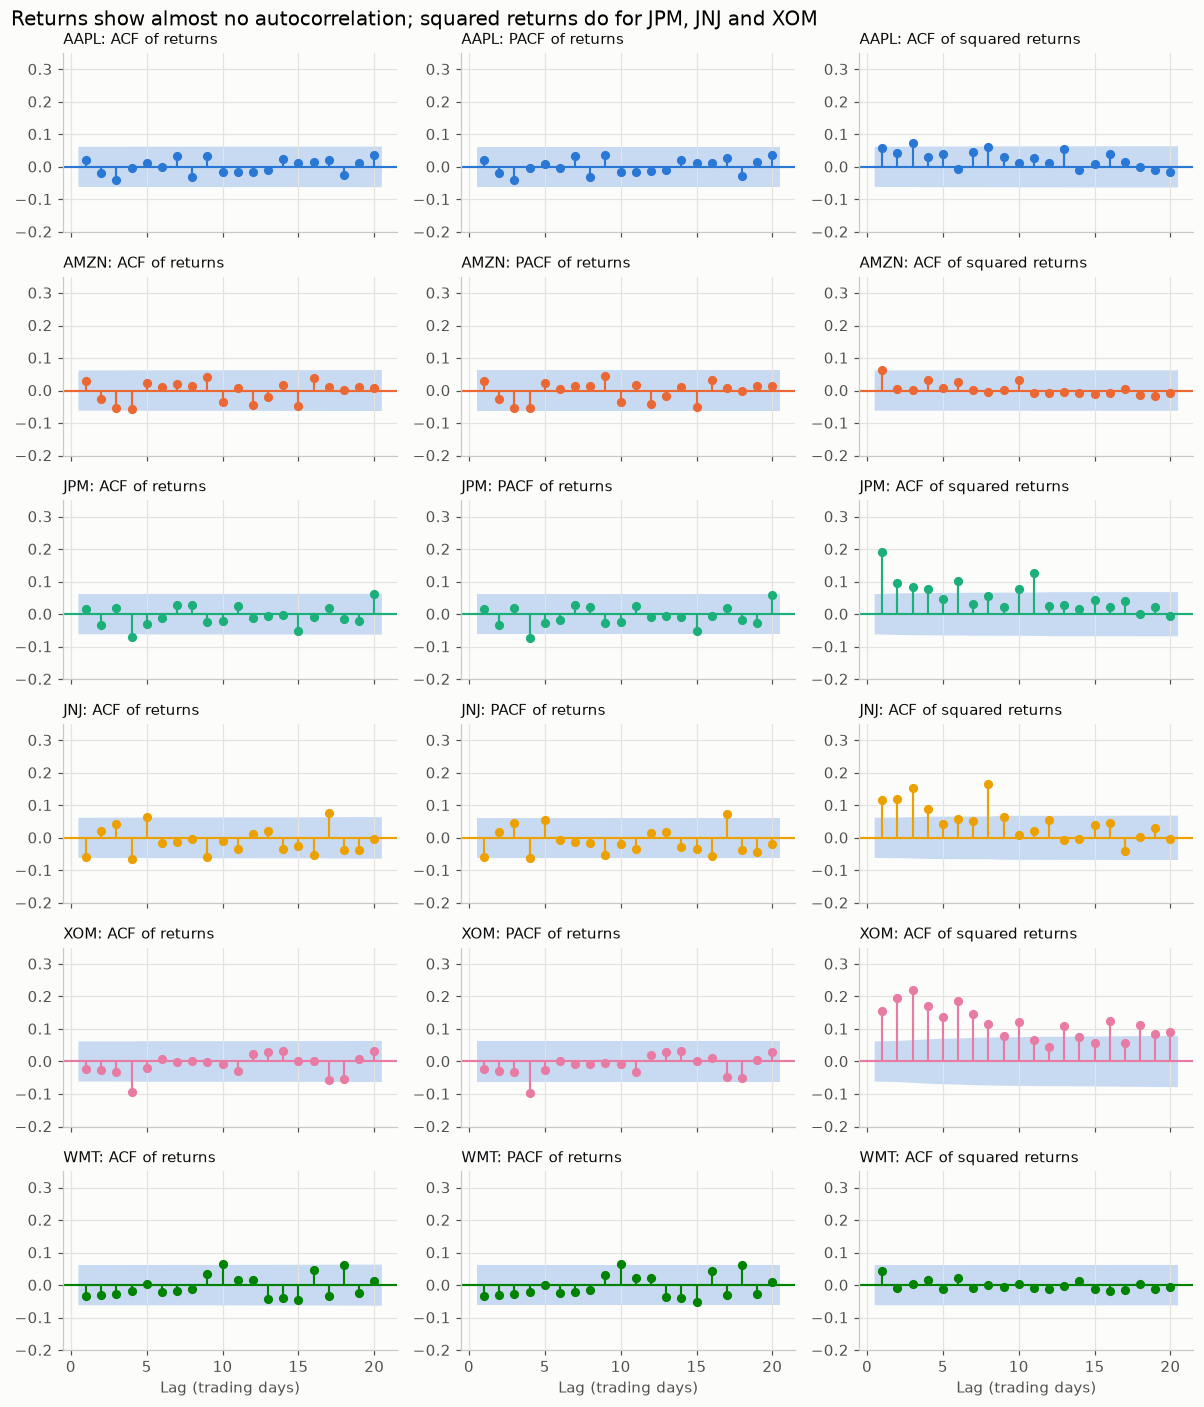

In [36]:
fig, axes = plt.subplots(6, 3, figsize=(11, 13), sharex=True)
for i, s in enumerate(S):
    plot_acf(R[s], lags=20, ax=axes[i, 0], zero=False, color=ch.color(s), vlines_kwargs={"colors": ch.color(s)}, title=None)
    plot_pacf(R[s], lags=20, ax=axes[i, 1], zero=False, method="ywm", color=ch.color(s), vlines_kwargs={"colors": ch.color(s)}, title=None)
    plot_acf(R[s] ** 2, lags=20, ax=axes[i, 2], zero=False, color=ch.color(s), vlines_kwargs={"colors": ch.color(s)}, title=None)
    for j, t in enumerate(["ACF of returns", "PACF of returns", "ACF of squared returns"]):
        axes[i, j].set_title(f"{s}: {t}", fontsize=9.5); axes[i, j].set_ylim(-0.2, 0.35)
for ax in axes[-1]:
    ax.set_xlabel("Lag (trading days)")
fig.suptitle("Returns show almost no autocorrelation; squared returns do for JPM, JNJ and XOM", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
ch.save_mpl(fig, "15_acf_pacf"); plt.show()

Return autocorrelations stay inside or barely outside the 95% band at every lag, so the occasional bar beyond it is what chance produces over 20 lags. Squared returns show many positive bars for JPM, JNJ and XOM: volatility persists, as in 5.4.

**Can past information estimate the next day's return or closing price?** (brief question 9). A **chronological** test: fit on **2014–2016** and evaluate on all **251 trading days of 2017**, with no shuffling and with every input known by the previous day's close. Three forecasts of tomorrow's return:
1. **No change** (random walk): tomorrow's return = 0, so tomorrow's close = today's close. This is the **baseline**.
2. **Historical mean**: the 2014–2016 average daily return.
3. **AR(1)**: an autoregression on yesterday's return (`statsmodels AutoReg`), estimated on 2014–2016 only.

Each return forecast also gives a price forecast (today's close × (1 + forecast return)). Accuracy is RMSE, and the **Diebold-Mariano test** (with the Harvey et al. small-sample correction) checks whether a model's squared errors are significantly different from the baseline's.

In [37]:
fc = []
for s in S:
    r = R[s]; c = C[s]
    tr, te = r[r.index.year <= 2016], r[r.index.year == 2017]
    ar = AutoReg(tr.values, lags=1, trend="c").fit(); a0, a1 = ar.params
    prev_r = r.shift(1).reindex(te.index).values
    prev_c = c.shift(1).reindex(te.index).values; act_c = c.reindex(te.index).values
    preds = {"No change (baseline)": np.zeros(len(te)), "Historical mean": np.full(len(te), tr.mean()), "AR(1)": a0 + a1 * prev_r}
    base_err = te.values
    for name, p in preds.items():
        e = te.values - p; pe = act_c - prev_c * (1 + p)
        dmr = sp.diebold_mariano(e ** 2, base_err ** 2) if name != "No change (baseline)" else {"dm": np.nan, "p": np.nan}
        direction = np.mean(te.values > 0) if name == "No change (baseline)" else np.mean(np.sign(p) == np.sign(te.values))
        fc.append({"symbol": s, "model": name, "test_days": len(te), "rmse_return_pct": 100 * np.sqrt(np.mean(e ** 2)),
                   "mae_return_pct": 100 * np.mean(np.abs(e)), "rmse_price_usd": np.sqrt(np.mean(pe ** 2)),
                   "mape_price_pct": 100 * np.mean(np.abs(pe / act_c)), "direction_hit_rate": direction,
                   "dm_stat_vs_baseline": dmr["dm"], "dm_p_vs_baseline": dmr["p"], "ar1_coefficient": a1 if name == "AR(1)" else np.nan})
fc = pd.DataFrame(fc)
fc["rmse_vs_baseline_pct"] = 100 * (fc.rmse_return_pct / fc.groupby("symbol").rmse_return_pct.transform("first") - 1)
fc.to_csv(OUT / "next_day_forecast_evaluation.csv", index=False)
display(fc)
print("For the baseline, 'direction_hit_rate' is the share of up days in 2017 (the hit rate of always predicting 'up').")

,symbol,model,test_days,rmse_return_pct,mae_return_pct,rmse_price_usd,mape_price_pct,direction_hit_rate,dm_stat_vs_baseline,dm_p_vs_baseline,ar1_coefficient,rmse_vs_baseline_pct
0,AAPL,No change (baseline),251,1.1602,0.7802,1.7521,0.7763,0.5458,NaN,NaN,NaN,0.0000
1,AAPL,Historical mean,251,1.1534,0.7775,1.7444,0.7741,0.5458,-1.7430,0.0826,NaN,-0.5862
2,AAPL,AR(1),251,1.1534,0.7788,1.7440,0.7754,0.5418,-1.5883,0.1135,0.0247,-0.5845
3,AMZN,No change (baseline),251,1.3305,0.8470,12.9669,0.8400,0.5657,NaN,NaN,NaN,0.0000
4,AMZN,Historical mean,251,1.3200,0.8363,12.8841,0.8301,0.5657,-1.6032,0.1101,NaN,-0.7886
5,AMZN,AR(1),251,1.3182,0.8337,12.8649,0.8275,0.5657,-1.8882,0.0602,0.0242,-0.9244
6,JPM,No change (baseline),251,1.0196,0.7434,0.9300,0.7416,0.4980,NaN,NaN,NaN,0.0000
7,JPM,Historical mean,251,1.0160,0.7452,0.9268,0.7439,0.4980,-0.9322,0.3522,NaN,-0.3553
8,JPM,AR(1),251,1.0159,0.7454,0.9266,0.7441,0.4980,-0.9146,0.3613,0.0165,-0.3604
9,JNJ,No change (baseline),251,0.7153,0.5115,0.9301,0.5103,0.5060,NaN,NaN,NaN,0.0000


For the baseline, 'direction_hit_rate' is the share of up days in 2017 (the hit rate of always predicting 'up').


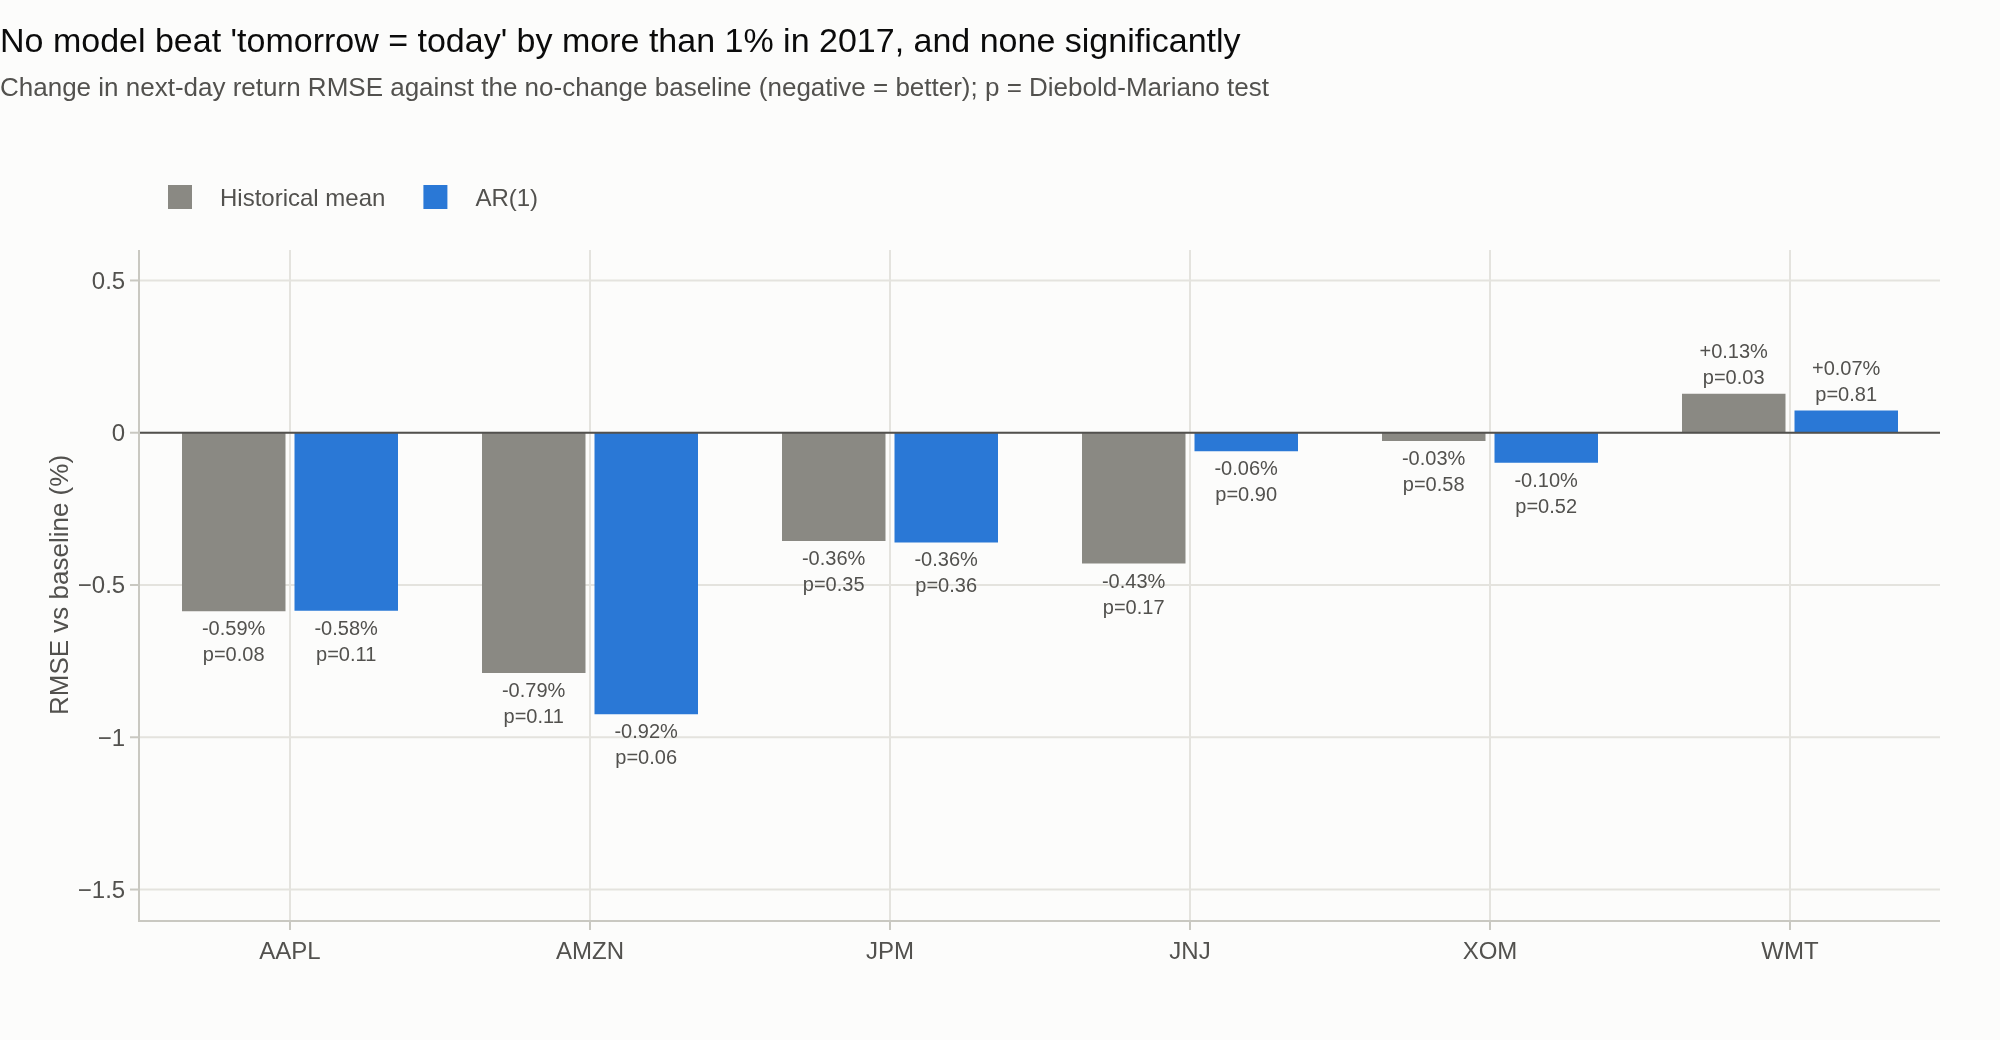

In [38]:
fig = go.Figure()
for m, colr in [("Historical mean", ch.MARKET_COLOR), ("AR(1)", ch.ACCENT)]:
    d = fc[fc.model == m].set_index("symbol").loc[S]
    fig.add_bar(x=S, y=d.rmse_vs_baseline_pct, name=m, marker_color=colr,
                text=[f"{v:+.2f}%<br>p={p:.2f}" for v, p in zip(d.rmse_vs_baseline_pct, d.dm_p_vs_baseline)],
                textposition="outside", textfont=dict(size=10, color=ch.TEXT_2))
fig.add_hline(y=0, line=dict(color=ch.TEXT_2, width=1))
fig.update_layout(title=ch.title("No model beat 'tomorrow = today' by more than 1% in 2017, and none significantly",
                                 "Change in next-day return RMSE against the no-change baseline (negative = better); p = Diebold-Mariano test"),
                  yaxis_title="RMSE vs baseline (%)", yaxis_range=[-1.6, 0.6], barmode="group", bargap=0.25, bargroupgap=0.08)
ch.save(fig, "16_next_day_forecast_vs_baseline", height=520)

**Result.** The best model improves on the no-change baseline by **less than 1% of RMSE** for every stock, and **no improvement is statistically significant** (the closest is AMZN's AR(1), Diebold-Mariano p = 0.06). The only significant difference is in the wrong direction: for WMT the historical mean was *worse* than no change (p = 0.03). The fitted AR(1) coefficients are tiny (−0.07 to +0.02). In price terms, the average error of "tomorrow's close = today's close" is 0.5% to 0.8% of the price (MAPE), and no model reduces it meaningfully. Direction hit rates of 41% to 58% are no better than the share of up days in 2017, a rising year. They reflect that year's upward drift, not skill.

**Answer to "can historical stock information estimate the next trading day's close or return?"** It can produce an estimate, and the next close will usually be close to today's. But using **past returns does not beat the simple "no change" rule** for these stocks in 2017. A model that reports a low price error is mostly reporting today's price back. The ML track should therefore (1) always compare against the no-change baseline, (2) judge accuracy on returns or price changes, not price levels, and (3) expect volatility to be more forecastable than direction (5.4).

## 7. Correlation analysis

**Choice of method.** **Spearman's rank correlation** is the main measure. Daily returns have very fat tails (excess kurtosis up to 19.5), so a few extreme days can dominate Pearson's coefficient. Spearman measures whether two stocks rise and fall together on ordinary days, regardless of outliers. **Pearson** is reported alongside, because it is the version used in portfolio maths (covariance, beta). Where the two disagree, extreme days are driving the result. Correlations use **returns, not prices** (6.1). Daily returns have almost no autocorrelation, so their effective sample size stays close to n. For volatility and volume series, which are autocorrelated, the effective sample size is used.

### 7.1 Daily returns of the selected stocks

,stock_a,stock_b,spearman,ci_low,ci_high,n_eff,p_adjusted,pearson,strength,p_holm
10,JPM,XOM,0.4700,0.4160,0.5206,948.0893,0.0000,0.4985,moderate positive,0.0000
0,AAPL,AMZN,0.4031,0.3473,0.4561,986.1445,0.0000,0.3387,moderate positive,0.0000
1,AAPL,JPM,0.3709,0.3136,0.4256,974.5442,0.0000,0.3686,moderate positive,0.0000
9,JPM,JNJ,0.3704,0.3123,0.4258,951.6772,0.0000,0.4124,moderate positive,0.0000
12,JNJ,XOM,0.3516,0.2930,0.4075,956.7801,0.0000,0.4229,moderate positive,0.0000
13,JNJ,WMT,0.3449,0.2875,0.3998,"1,002.9618",0.0000,0.3065,moderate positive,0.0000
5,AMZN,JPM,0.3354,0.2767,0.3917,967.7754,0.0000,0.2821,moderate positive,0.0000
6,AMZN,JNJ,0.3310,0.2724,0.3873,974.4305,0.0000,0.2746,moderate positive,0.0000
2,AAPL,JNJ,0.2690,0.2096,0.3264,"1,006.0000",0.0000,0.2952,weak positive,0.0000
7,AMZN,XOM,0.2622,0.2022,0.3202,990.1398,0.0000,0.2336,weak positive,0.0000


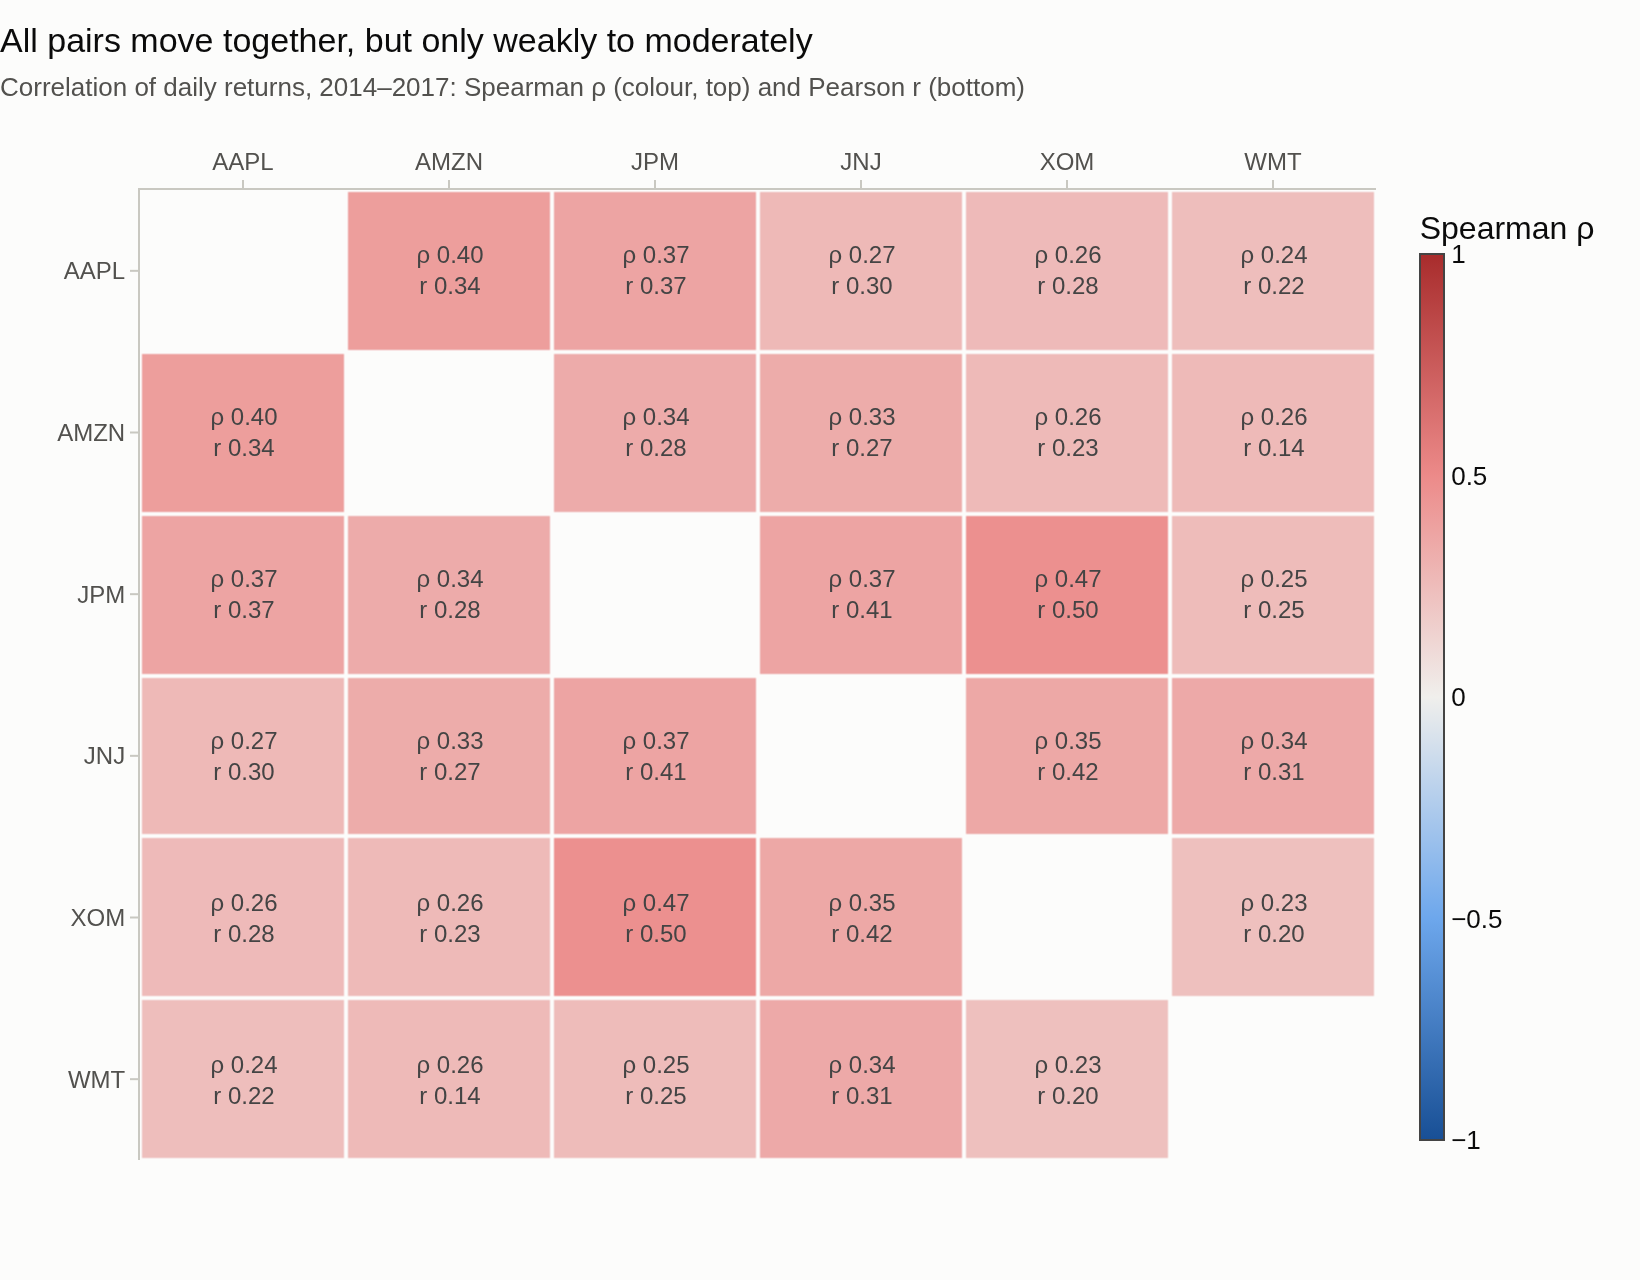

In [39]:
sp_m = R.corr("spearman"); pe_m = R.corr("pearson")
sp_m.to_csv(OUT / "correlation_returns_spearman.csv"); pe_m.to_csv(OUT / "correlation_returns_pearson.csv")
ct = []
for i, a in enumerate(S):
    for b in S[i + 1:]:
        rs = sp.corr_test(R[a], R[b], "spearman"); rp = sp.corr_test(R[a], R[b], "pearson")
        ct.append({"stock_a": a, "stock_b": b, "spearman": rs["r"], "ci_low": rs["ci_low"], "ci_high": rs["ci_high"], "n_eff": rs["n_eff"],
                   "p_adjusted": rs["p_adjusted"], "pearson": rp["r"], "strength": sp.strength_label(rs["r"])})
ct = pd.DataFrame(ct); ct["p_holm"] = sp.holm(ct.p_adjusted)
ct.sort_values("spearman", ascending=False).to_csv(OUT / "correlation_tests_returns.csv", index=False)
display(ct.sort_values("spearman", ascending=False))

z = sp_m.values.copy(); lower = np.tril(np.ones_like(z, dtype=bool))
txt = [[f"ρ {sp_m.iloc[i, j]:.2f}<br>r {pe_m.iloc[i, j]:.2f}" if i != j else "" for j in range(6)] for i in range(6)]
fig = go.Figure(go.Heatmap(z=np.where(np.eye(6, dtype=bool), np.nan, z), x=S, y=S, colorscale=ch.DIVERGING, zmin=-1, zmax=1, zmid=0,
                           text=txt, texttemplate="%{text}", textfont=dict(size=12), xgap=2, ygap=2,
                           colorbar=dict(title="Spearman ρ", thickness=12), hovertemplate="%{y}–%{x}: %{text}<extra></extra>"))
fig.update_yaxes(autorange="reversed", showgrid=False); fig.update_xaxes(showgrid=False, side="top")
fig.update_layout(title=ch.title("All pairs move together, but only weakly to moderately",
                                 "Correlation of daily returns, 2014–2017: Spearman ρ (colour, top) and Pearson r (bottom)"))
ch.save(fig, "17_return_correlation_heatmap", width=820, height=640)

**Result.** All 15 pairs are **positively correlated** and all are significant after the Holm adjustment (p < 10⁻¹²), but the relationships are only **weak to moderate** (Spearman ρ from 0.23 to 0.47).

* **Most similar daily patterns:** **JPM and XOM** (ρ = 0.47, Pearson 0.50), then **AAPL and AMZN** (0.40), followed by JPM with AAPL and with JNJ (0.37). The bank and the oil company both depend on the economic cycle and interest rates. Apple and Amazon are both large technology and growth stocks.
* **Least connected:** **WMT** (ρ 0.23 to 0.34 with every other stock). It is the best diversifier in this group.
* Pearson and Spearman mostly agree within ±0.07. The largest gap is AMZN–WMT (Spearman 0.26, Pearson 0.14), where each stock's isolated extreme days reduce the linear correlation.

**Interpretation.** Six large stocks from six sectors share a common market component but still move far from in step. With an average pairwise correlation of about 0.32, combining them reduces risk considerably compared with holding any one of them. The equal-weighted portfolio of the six had an annualised volatility of about 13% (see `Outputs/key_figures.csv`), against 14% to 30% for the individual stocks. These correlations are associations over 2014 to 2017. They change over time (7.2) and are typically higher in market sell-offs.

### 7.2 Relationship with the market, and how it changes over time

,beta,beta_ci_low,beta_ci_high,r_squared,spearman_with_market,alpha_daily_pct,alpha_p
symbol,,,,,,,
AAPL,0.8787,0.7596,0.9978,0.2398,0.4800,0.0450,0.2509
AMZN,1.0160,0.8364,1.1955,0.1888,0.4987,0.0770,0.1393
JPM,1.2066,1.1172,1.2959,0.5521,0.6983,0.0125,0.6676
JNJ,0.6407,0.5525,0.7289,0.3301,0.5074,0.0166,0.4704
XOM,0.8723,0.7682,0.9764,0.3787,0.5704,-0.0518,0.0529
WMT,0.5460,0.4505,0.6414,0.1451,0.4039,0.0033,0.9172


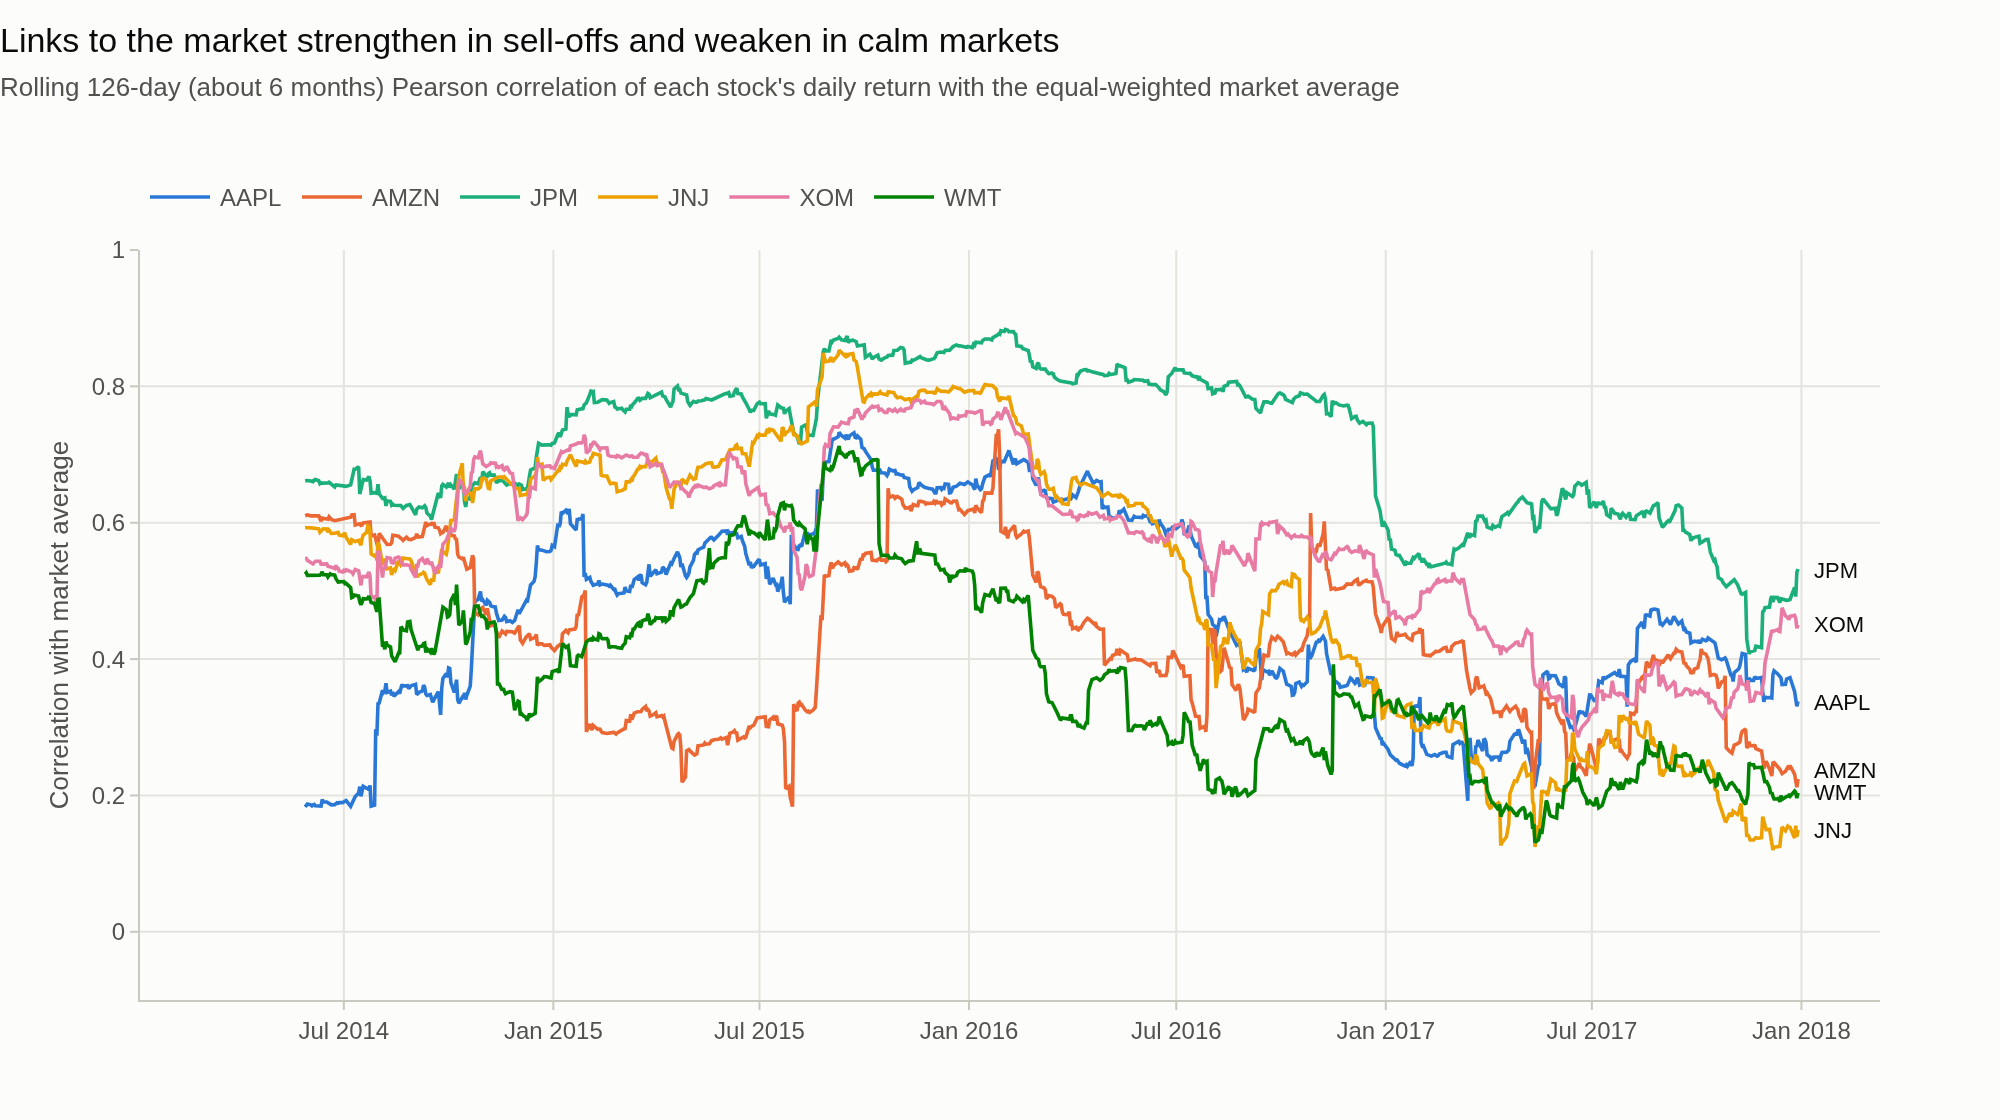

In [40]:
beta = []
X = sm.add_constant(mret.values)
for s in S:
    fit = sm.OLS(R[s].values, X).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    beta.append({"symbol": s, "beta": fit.params[1], "beta_ci_low": fit.conf_int()[1][0], "beta_ci_high": fit.conf_int()[1][1],
                 "r_squared": fit.rsquared, "spearman_with_market": stats.spearmanr(R[s], mret).statistic,
                 "alpha_daily_pct": 100 * fit.params[0], "alpha_p": fit.pvalues[0]})
beta = pd.DataFrame(beta).set_index("symbol")
beta.to_csv(OUT / "beta_vs_market_average.csv")
display(beta)

rc = R.rolling(126, min_periods=100).corr(mret)
fig = go.Figure()
for s in S:
    fig.add_scatter(x=rc.index, y=rc[s], name=s, line=dict(color=ch.color(s), width=1.8),
                    hovertemplate=f"{s} %{{x|%b %Y}}: %{{y:.2f}}<extra></extra>")
ch.end_labels(fig, {s: (rc.index[-1], rc[s].iloc[-1]) for s in S})
fig.update_layout(title=ch.title("Links to the market strengthen in sell-offs and weaken in calm markets",
                                 "Rolling 126-day (about 6 months) Pearson correlation of each stock's daily return with the equal-weighted market average"),
                  yaxis_title="Correlation with market average", yaxis_range=[-0.1, 1], margin_r=60)
ch.save(fig, "18_rolling_correlation_with_market", height=560)

**Result.** **JPM** is the stock most tied to the market (Spearman 0.70 with the market average; beta 1.21, so it moves about 1.2% for each 1% market move). **WMT** (beta 0.55) and **JNJ** (0.64) are the most defensive. **AAPL**, **XOM** and **AMZN** sit between 0.87 and 1.02. The market average explains 15% (WMT) to 55% (JPM) of the variation in daily returns. The rest is stock-specific. No stock has an "alpha" (return beyond the market) significantly different from zero.

Over time, correlations with the market **rise during broad sell-offs** (between September 2015 and June 2016 every stock's 6-month correlation peaked at 0.71 to 0.88) and **fall in calm periods** (in 2017 they fell to 0.12 to 0.21 for JNJ, WMT, AAPL and AMZN; JPM stayed above 0.4). Diversification is weakest exactly when it is most needed. A single full-period correlation understates this.

### 7.3 Volatility measures across stocks
Do the stocks become turbulent at the same times? Each stock's **monthly realised volatility** (SD of its daily returns within each calendar month, annualised) gives 48 non-overlapping values per stock. Monthly volatility is autocorrelated, so p-values use the effective sample size.

In [41]:
mv = R.groupby(R.index.to_period("M")).std() * np.sqrt(252)
mv.to_csv(OUT / "monthly_realised_volatility.csv")
vc = []
for i, a in enumerate(S):
    for b in S[i + 1:]:
        t = sp.corr_test(mv[a].values, mv[b].values, "spearman")
        vc.append({"stock_a": a, "stock_b": b, "spearman": t["r"], "n": t["n"], "n_eff": t["n_eff"], "p_adjusted": t["p_adjusted"],
                   "ci_low": t["ci_low"], "ci_high": t["ci_high"]})
vc = pd.DataFrame(vc); vc["p_holm"] = sp.holm(vc.p_adjusted); vc["strength"] = vc.spearman.map(sp.strength_label)
vc.to_csv(OUT / "correlation_tests_monthly_volatility.csv", index=False)
display(vc.sort_values("spearman", ascending=False))
mv_c = mv.corr("spearman")
print(f"Average pairwise correlation of monthly volatility: {mv_c.values[np.triu_indices(6, 1)].mean():.2f} "
      f"(daily returns: {sp_m.values[np.triu_indices(6, 1)].mean():.2f})")

xs_corr = pd.DataFrame([
    {"relationship": "annualised volatility vs total return", **{k: v for k, v in sp.corr_test(xs.ann_volatility, xs.total_return, 'spearman', adjust=False).items() if k in ('r', 'n', 'p_naive', 'ci_low', 'ci_high')}},
    {"relationship": "annualised volatility vs mean daily return", **{k: v for k, v in sp.corr_test(xs.ann_volatility, xs.mean_daily_return, 'spearman', adjust=False).items() if k in ('r', 'n', 'p_naive', 'ci_low', 'ci_high')}},
    {"relationship": "average volume (shares) vs annualised volatility", **{k: v for k, v in sp.corr_test(xs.avg_volume, xs.ann_volatility, 'spearman', adjust=False).items() if k in ('r', 'n', 'p_naive', 'ci_low', 'ci_high')}},
])
xs_corr.to_csv(OUT / "cross_section_correlations.csv", index=False)
display(xs_corr)

,stock_a,stock_b,spearman,n,n_eff,p_adjusted,ci_low,ci_high,p_holm,strength
12,JNJ,XOM,0.5366,48,34.3423,0.0010,0.2212,0.7504,0.0121,strong positive
6,AMZN,JNJ,0.5195,48,39.1886,0.0007,0.2247,0.7272,0.0102,strong positive
0,AAPL,AMZN,0.5192,48,38.3278,0.0008,0.2203,0.7290,0.0111,strong positive
9,JPM,JNJ,0.5166,48,37.9473,0.0009,0.2153,0.7281,0.0118,strong positive
10,JPM,XOM,0.5049,48,28.7830,0.0054,0.1449,0.7468,0.0540,strong positive
14,XOM,WMT,0.4582,48,32.5973,0.0077,0.1158,0.7033,0.0683,moderate positive
1,AAPL,JPM,0.4330,48,41.8809,0.0042,0.1341,0.6597,0.0466,moderate positive
5,AMZN,JPM,0.4323,48,35.8456,0.0086,0.1047,0.6752,0.0683,moderate positive
4,AAPL,WMT,0.3979,48,43.8488,0.0076,0.1022,0.6289,0.0683,moderate positive
3,AAPL,XOM,0.3905,48,38.3284,0.0149,0.0701,0.6378,0.0894,moderate positive


Average pairwise correlation of monthly volatility: 0.41 (daily returns: 0.32)


,relationship,r,n,p_naive,ci_low,ci_high
0,annualised volatility vs total return,-0.1942,479,0.0000,-0.2797,-0.1056
1,annualised volatility vs mean daily return,-0.0713,479,0.1191,-0.1600,0.0185
2,average volume (shares) vs annualised volatility,0.2313,479,0.0000,0.1435,0.3154


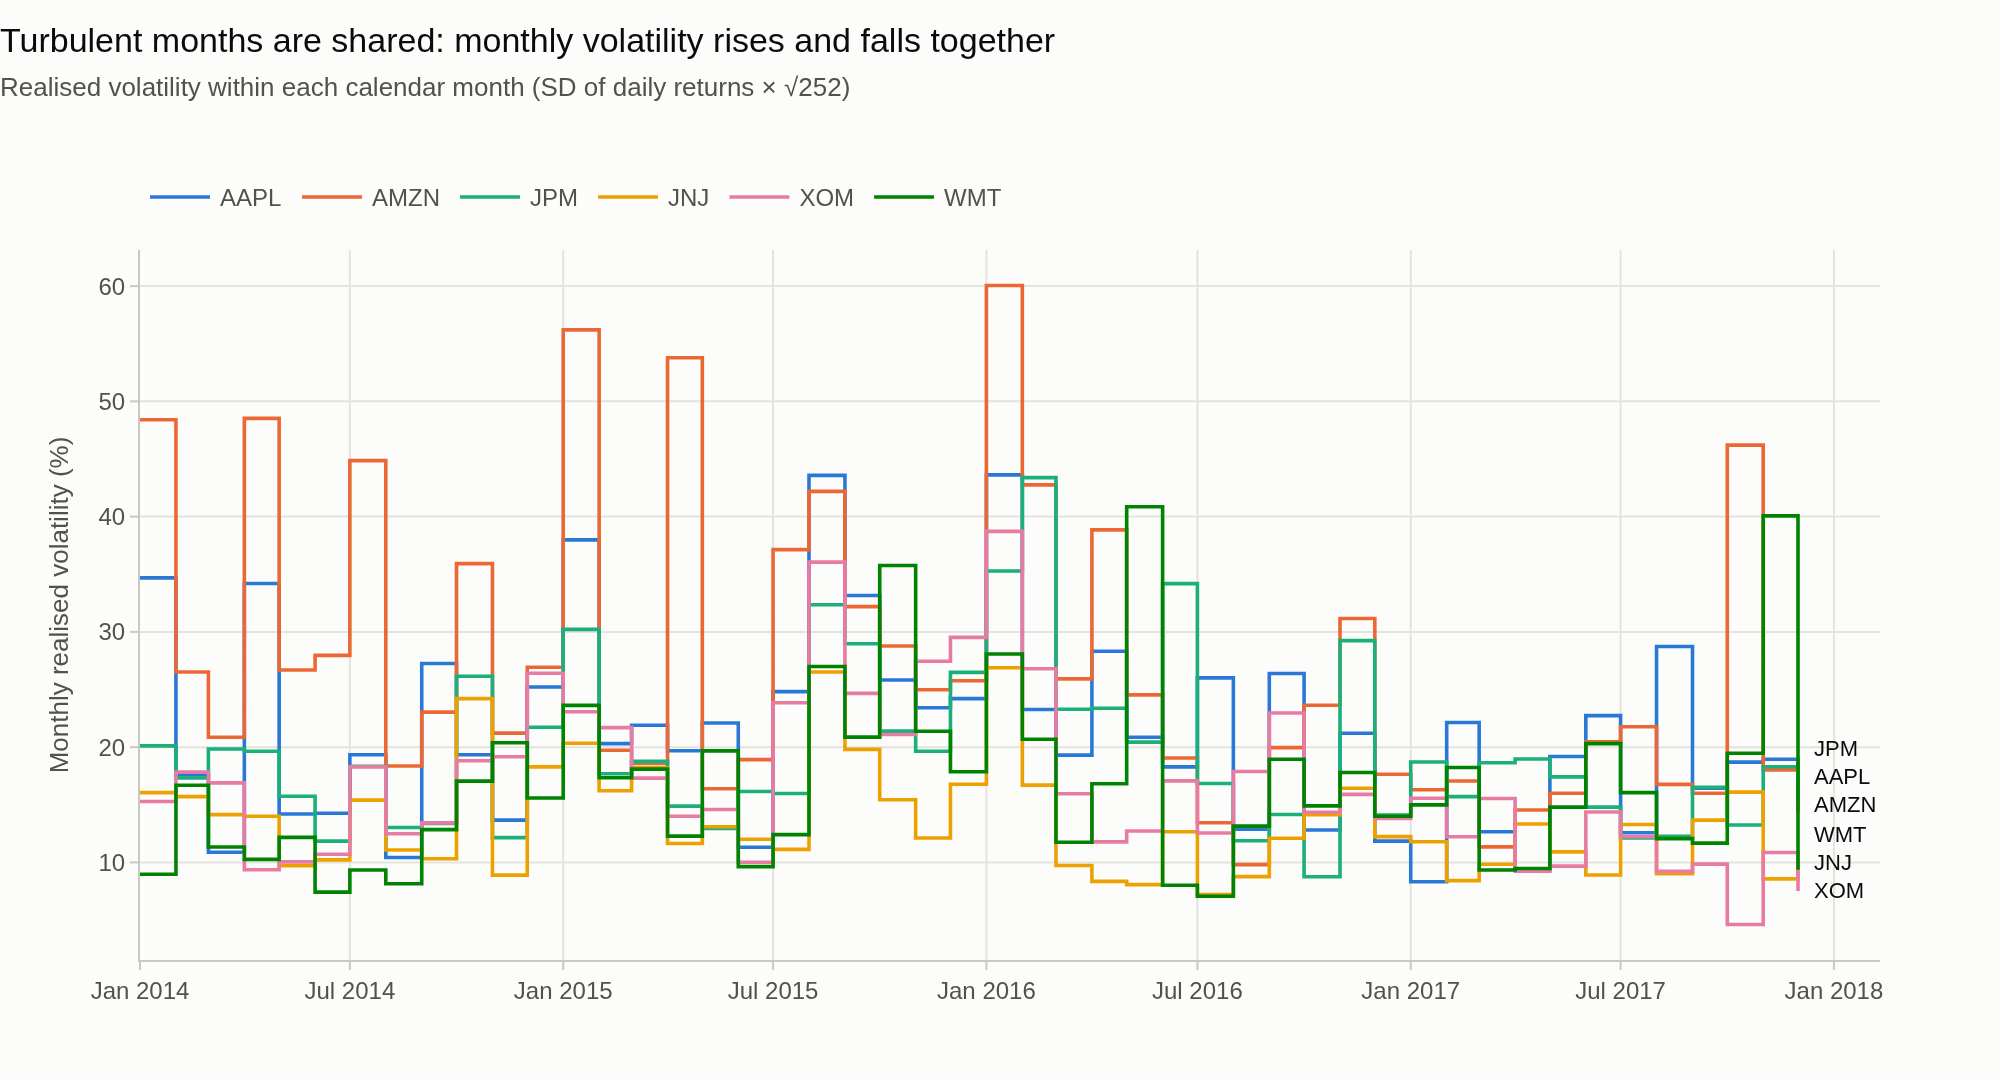

In [42]:
fig = go.Figure()
for s in S:
    fig.add_scatter(x=mv.index.to_timestamp(), y=100 * mv[s], name=s, mode="lines", line=dict(color=ch.color(s), width=1.8, shape="hv"),
                    hovertemplate=f"{s} %{{x|%b %Y}}: %{{y:.1f}}%<extra></extra>")
ch.end_labels(fig, {s: (mv.index[-1].to_timestamp(), 100 * mv[s].iloc[-1]) for s in S})
fig.update_layout(title=ch.title("Turbulent months are shared: monthly volatility rises and falls together",
                                 "Realised volatility within each calendar month (SD of daily returns × √252)"),
                  yaxis_title="Monthly realised volatility (%)", margin_r=60)
ch.save(fig, "19_monthly_realised_volatility", height=540)

**Result.** Monthly volatilities are **positively correlated for every pair** (Spearman 0.26 to 0.54; the average, 0.41, is higher than for daily returns at 0.32). With only 48 months and autocorrelated series (effective n of 28 to 45), the intervals are wide, and **5 of the 15 pairs are significant after the Holm adjustment** (JNJ–XOM, AMZN–JNJ, AAPL–AMZN, JPM–JNJ and AAPL–JPM). **Turbulence tends to be shared more than direction is**: when one stock has a volatile month, the others tend to as well. WMT's volatility is the least connected (except to XOM).

**Across all 479 complete-history stocks:** volatility had essentially **no relationship with mean daily return** (ρ = −0.07, not significant) and a weak **negative** one with total return (ρ = −0.19), as shown in Chart 07. Stocks with higher average share volume were somewhat more volatile (ρ = 0.23). Both relationships are weak, and volume in shares is not comparable across companies with different share prices.

**Limitations of the correlation analysis.** Correlation is not causation, and coefficients change over time (7.2). The equal-weighted market average shares stocks with the six stocks, which slightly inflates their correlation with it. Survivorship bias affects the cross-section. Monthly volatility estimates use about 21 days each and are noisy.

## 8. Validation

### 8.1 Robustness: do the conclusions depend on analysis choices?
Each headline result is recomputed under alternative choices: **log returns** instead of simple returns; **excluding each stock's 1% most extreme days** (to test dependence on outliers); **including the flagged returns** in the market average; and the first and second halves of the period.

In [43]:
L = sp.returns_wide(df, S, col="log_return").iloc[1:]
trim = R.where(R.abs().le(R.abs().quantile(0.99)))
def headline(Rx, m=None):
    Rx = Rx.dropna(how="any")
    fr_ = stats.friedmanchisquare(*[Rx[s] for s in S]); bf_ = stats.levene(*[Rx[s] for s in S], center="median")
    hac_p = [sp.hac_mean_test(Rx[s])["p_hac"] for s in S]
    sm_ = Rx.corr("spearman").values[np.triu_indices(6, 1)]
    return {"most_volatile": Rx.std().idxmax(), "least_volatile": Rx.std().idxmin(),
            "AMZN_ann_vol": Rx["AMZN"].std() * np.sqrt(252), "JNJ_ann_vol": Rx["JNJ"].std() * np.sqrt(252),
            "min_holm_p_mean_return": sp.holm(hac_p).min(), "friedman_location_W": sp.kendalls_w(fr_.statistic, len(Rx), 6),
            "brown_forsythe_p": bf_.pvalue, "mean_pairwise_spearman": sm_.mean(), "most_correlated_pair":
            "-".join(max(((a, b) for i, a in enumerate(S) for b in S[i + 1:]), key=lambda p: Rx[p[0]].corr(Rx[p[1]], method="spearman")))}
rob = pd.DataFrame({
    "main (simple returns)": headline(R),
    "log returns": headline(L),
    "without each stock's top 1% |return| days": headline(trim),
    "2014-2015 only": headline(R[R.index.year <= 2015]),
    "2016-2017 only": headline(R[R.index.year >= 2016]),
}).T
all_flags_mkt = df[df.pct_return.notna()].groupby("date").pct_return.mean()
rob_mkt = pd.Series({"market total return (main, flagged returns excluded)": mkt.market_index.iloc[-1] / 100 - 1,
                     "market total return (all returns, flags ignored)": (1 + all_flags_mkt).prod() - 1})
rob.to_csv(OUT / "robustness_checks.csv")
display(rob); display(rob_mkt.to_frame("value"))

,most_volatile,least_volatile,AMZN_ann_vol,JNJ_ann_vol,min_holm_p_mean_return,friedman_location_W,brown_forsythe_p,mean_pairwise_spearman,most_correlated_pair
main (simple returns),AMZN,JNJ,0.2960,0.1411,0.1653,0.0028,0.0000,0.3172,JPM-XOM
log returns,AMZN,JNJ,0.2942,0.1410,0.3433,0.0028,0.0000,0.3172,JPM-XOM
without each stock's top 1% |return| days,AMZN,JNJ,0.2238,0.1282,0.1000,0.0028,0.0000,0.3104,JPM-XOM
2014-2015 only,AMZN,JNJ,0.3306,0.1560,0.8784,0.0041,0.0000,0.4005,JPM-JNJ
2016-2017 only,AMZN,JNJ,0.2571,0.1246,0.1577,0.0024,0.0000,0.2192,AAPL-AMZN


,value
"market total return (main, flagged returns excluded)",0.5485
"market total return (all returns, flags ignored)",0.5373


**Result.** The conclusions hold under every alternative:
* AMZN is always the most volatile stock and JNJ the least.
* No mean return is significant after Holm in any version.
* The location effect stays negligible (W < 0.01).
* Volatility differences stay overwhelming (Brown-Forsythe p < 10⁻¹⁶).
* JPM–XOM is the most correlated pair in the full period, with log returns and without extreme days. In the two halves the top pair changes (JPM–JNJ in 2014–15, AAPL–AMZN in 2016–17), and the average correlation falls from 0.40 to 0.22, which again shows that correlations are not stable.

Removing the 1% most extreme days lowers volatility but changes no ranking. Ignoring the data-quality flags would change the market average's 4-year return by only about one percentage point, because the flags are few compared with 497,000 records. The flags matter much more for **individual** stocks such as LNT, NWL and EBAY.

### 8.2 Key figures and independent recalculation
The notebook writes its key figures to `Outputs/key_figures.csv`. `validation/independent_check.py` then recomputes every one of them **from the raw CSV using only the Python standard library** (`csv`, `math`, `datetime`), without pandas, NumPy, SciPy or `stock_prep`. It re-implements the parsing, sorting, return calculation, flag rules, statistics, moving averages, correlations and the Friedman and Brown-Forsythe statistics independently. The notebook stops if any figure disagrees.

In [44]:
kf = {}
kf["n_rows"] = len(raw); kf["n_symbols"] = raw.symbol.nunique(); kf["n_dates"] = len(calendar)
kf["missing_open"] = int(raw.open.isna().sum()); kf["missing_high"] = int(raw.high.isna().sum()); kf["missing_low"] = int(raw.low.isna().sum())
kf["zero_volume_rows"] = int((raw.volume == 0).sum()); kf["duplicate_symbol_dates"] = dups_key
kf["complete_histories"] = int(cov.complete.sum()); kf["ohlc_inconsistent_rows"] = int(df.ohlc_inconsistent.sum())
kf["price_error_flags"] = int(df.price_error.sum()); kf["multi_day_returns"] = int(df.multi_day_return.sum())
kf["valid_returns"] = int(df.valid_return.sum())
kf["max_close_all"] = df.close.max(); kf["min_close_all"] = df.close.min()
kf["market_avg_total_return"] = mkt.market_index.iloc[-1] / 100 - 1
kf["median_total_return_complete"] = xs.total_return.median()
kf["NVDA_total_return"] = xs.loc["NVDA", "total_return"]; kf["CHK_total_return"] = xs.loc["CHK", "total_return"]
for s in S:
    c = C[s]; r = R[s]; v = V[s]
    kf[f"{s}_first_close"] = c.iloc[0]; kf[f"{s}_last_close"] = c.iloc[-1]
    kf[f"{s}_mean_close"] = c.mean(); kf[f"{s}_median_close"] = c.median(); kf[f"{s}_std_close"] = c.std()
    kf[f"{s}_min_close"] = c.min(); kf[f"{s}_max_close"] = c.max()
    kf[f"{s}_total_return"] = sp.total_return(c)
    kf[f"{s}_mean_daily_return"] = r.mean(); kf[f"{s}_median_daily_return"] = r.median(); kf[f"{s}_std_daily_return"] = r.std()
    kf[f"{s}_max_daily_return"] = r.max(); kf[f"{s}_min_daily_return"] = r.min()
    kf[f"{s}_skewness"] = stats.skew(r, bias=False); kf[f"{s}_excess_kurtosis"] = stats.kurtosis(r, bias=False)
    kf[f"{s}_ma20_last"] = sel[sel.symbol == s].ma_20.iloc[-1]; kf[f"{s}_ma200_last"] = sel[sel.symbol == s].ma_200.iloc[-1]
    kf[f"{s}_mean_volume"] = v.mean(); kf[f"{s}_max_drawdown"] = sp.max_drawdown(c)[0]
    kf[f"{s}_t_stat"] = stats.ttest_1samp(r, 0).statistic
for i, a in enumerate(S):
    for b in S[i + 1:]:
        kf[f"spearman_{a}_{b}"] = sp_m.loc[a, b]; kf[f"pearson_{a}_{b}"] = pe_m.loc[a, b]
kf["friedman_location_chi2"] = fr.statistic; kf["brown_forsythe_F"] = bf.statistic
kf["equal_weight_portfolio_ann_vol"] = R.mean(axis=1).std() * np.sqrt(252)
key = pd.DataFrame({"figure": list(kf), "value": [float(v) for v in kf.values()]})
key.to_csv(OUT / "key_figures.csv", index=False)
print(f"{len(key)} key figures written to Outputs/key_figures.csv")

172 key figures written to Outputs/key_figures.csv


In [45]:
import subprocess, sys
res = subprocess.run([sys.executable, "validation/independent_check.py"], capture_output=True, text=True)
lines = res.stdout.strip().splitlines()
print("\n".join(lines[:8] + ["..."] + lines[-4:]))
assert res.returncode == 0, "Independent recalculation failed:\n" + res.stdout + res.stderr

PASS  n_rows                             notebook   497,472.00000000   independent   497,472.00000000
PASS  n_symbols                          notebook       505.00000000   independent       505.00000000
PASS  n_dates                            notebook     1,007.00000000   independent     1,007.00000000
PASS  missing_open                       notebook        11.00000000   independent        11.00000000
PASS  missing_high                       notebook         8.00000000   independent         8.00000000
PASS  missing_low                        notebook         8.00000000   independent         8.00000000
PASS  zero_volume_rows                   notebook         4.00000000   independent         4.00000000
PASS  duplicate_symbol_dates             notebook         0.00000000   independent         0.00000000
...
PASS  brown_forsythe_F                   notebook        42.20839052   independent        42.20839052
PASS  equal_weight_portfolio_ann_vol     notebook         0.13263933   indepen

### 8.3 Unit tests and raw-file integrity

In [46]:
res = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests"], capture_output=True, text=True)
print(res.stdout.strip().splitlines()[-1])
assert res.returncode == 0, res.stdout
assert sp.sha256(sp.RAW_PATH) == sp.RAW_SHA256, "raw file changed during the run"
print("Raw file unchanged (SHA-256 verified again at the end of the run).")

26 passed in 17.22s
Raw file unchanged (SHA-256 verified again at the end of the run).


## 9. Limitations
* **Historical, four-year window.** 2014 to 2017 includes an oil crash (2014–16) and an unusually calm, rising 2017. Results describe that period only and are not current market facts. Four years is too short to estimate average returns precisely (5.1) or to test annual seasonality (6.3).
* **Price returns only.** The file is split-adjusted but not dividend-adjusted, so total returns are understated for dividend payers (JNJ, XOM, WMT and JPM most). Spin-offs are not adjusted. The 12 flagged events come from public announcements, not from the data.
* **Survivorship bias.** The 505 symbols appear to be the index's later membership, so companies that dropped out are missing, and market-wide averages and "share of stocks that gained" are biased upwards. The equal-weighted market average is not the S&P 500 index.
* **Data-quality rules are judgement calls.** The spike rule (≥ 20% move reversed within 5%) could, rarely, flag a real event or miss a smaller error. Flags are documented and Section 8.1 shows the market-wide conclusions do not depend on them.
* **Currency and definitions are assumed** (US dollars; volume = shares traded). No source documentation was supplied.
* **Statistical caveats.** Returns are fat-tailed and volatility clusters. HAC errors, rank tests, bootstrap and effective sample sizes address this approximately, and depend on choices such as block length and lag windows. Correlations are associations, change over time and are not causal.
* **Six stocks are not a sample of the market.** They were chosen as large, complete, cross-sector examples, so their results do not generalise to all S&P 500 stocks.
* **Forecast test is narrow.** It covers one test year (2017), three simple models and one-day horizons. It shows past returns did not help in that setting. It does not prove no model could.

## 10. Findings, recommendations and answers to the brief's questions

### 10.1 Key findings
1. **The six stocks differ clearly in risk, not in average daily return.** Annualised volatility ranges from 14% (JNJ) to 30% (AMZN), and 14 of 15 pairs differ significantly (Brown-Forsythe p < 10⁻⁴⁰). The difference in typical daily return is statistically detectable only with the paired test and is negligible in size (Kendall's W = 0.003).
2. **Large total-return differences are hard to distinguish from luck at the daily level.** AMZN +194%, AAPL +114%, JPM +84%, JNJ +53%, WMT +25% and XOM −16%, yet no mean daily return differs from zero on the HAC test after Holm correction (only AMZN's rank-based test is borderline significant). Four years can only detect mean daily returns of about 0.08% to 0.16%.
3. **Volume goes with the size of moves, not their direction.** Relative volume and absolute return: Spearman ρ 0.35 to 0.46 (all p < 10⁻²⁵). Relative volume and signed return: |ρ| < 0.07, not significant.
4. **The stocks move together weakly to moderately, and more so in sell-offs.** Pairwise ρ is 0.23 to 0.47. JPM–XOM (0.47) and AAPL–AMZN (0.40) are the most similar pairs, and WMT is the least connected. Correlation with the market peaked at 0.7–0.9 in the 2015–16 sell-off and fell to about 0.1–0.2 for four stocks in calm 2017.
5. **Volatility clusters, and returns are close to unpredictable.** Volatility clustering is strong for JPM, JNJ, XOM and the market (ARCH-LM p < 0.001). Returns show no significant autocorrelation, no day-of-week or month effect, and no stable seasonality (seasonal strength ≤ 0.11). In 2017, out of sample, no model beat "tomorrow = today" significantly.
6. **Market-wide (all symbols, complete histories, 2014–2017):** the highest close was PCLN \$2,049 and the lowest CHK \$1.59. NVDA had the highest return (about +1,120%) and CHK the lowest (−85%). Riskier stocks did **not** earn more over these four years (ρ = −0.19).
7. **Data quality:** all of the brief's checks were confirmed. Five further issue types were found and handled: price errors (14 September 2017 and LNT), inconsistent open/high/low/close, gaps inside histories, unadjusted spin-offs and survivorship bias.

### 10.2 Recommendations
| # | Recommendation | Evidence | How stakeholders can use it |
|---|---|---|---|
| 1 | **Compare stocks on risk-adjusted terms and report volatility with an interval**, not on total return alone. | Finding 1 and 2; Chart 09 and 11 | Researchers ranking stocks should treat volatility differences as reliable and return differences as uncertain. |
| 2 | **Diversify across weakly correlated sectors, but stress-test for higher correlations in sell-offs.** | Finding 4; Charts 17 and 18 | Use WMT/JNJ-type defensive names to lower risk; size risk limits using sell-off correlations (0.7–0.9), not full-period averages (about 0.3). |
| 3 | **Treat volume spikes as a volatility warning, not a direction signal.** | Finding 3; Chart 10 | Monitoring dashboards can flag days with relative volume > 2 as likely large-move days. |
| 4 | **For prediction work, beat the no-change baseline and evaluate on returns**; focus on forecasting volatility, which has memory, rather than direction. | Finding 5; Chart 16 | The ML track's acceptance criterion: a model must beat "tomorrow = today" on a chronological test set with a Diebold-Mariano test. |
| 5 | **Use adjusted total-return data and point-in-time index membership for any decision-grade analysis.** | Section 2.3, 2.4 and 9 | Fixes the dividend, spin-off and survivorship limitations before results are used for investment research. |

### 10.3 Answers to the brief's questions (Data Science view)
| Brief question | Answer (2014–2017, historical) | Where |
|---|---|---|
| 1. Highest and lowest closing prices | PCLN \$2,049 (8 Aug 2017); CHK \$1.59 (12 Feb 2016). Among the six: AMZN highest (\$1,196), JPM lowest (\$53) | 3.5, 4.1 |
| 2. Highest percentage returns | All symbols: NVDA ≈ +1,120%, AVGO, EA. Six: AMZN +194%, AAPL +114%, JPM +84% | 3.5, 4.2 |
| 3. Greatest volatility | Six: AMZN (30% annualised), then AAPL and JPM; JNJ the least (14%). All symbols: CHK, AMD, FCX | 5.3, 3.5 |
| 4. Price change 2014–2017 | Five of six rose; XOM fell 16%. Leadership changed every year; 2015 weak, 2016–17 strong; 2017 very calm | 3.2, 4.3 |
| 5. Volume variation | AAPL 45 M shares/day down to AMZN 3.9 M; volume peaked in 2015–16 turbulence; shares are not money | 3.4 |
| 6. Volume vs returns | Moderate positive link with the **size** of returns (ρ ≈ 0.35–0.46), none with direction | 5.2 |
| 7. Similar daily return patterns | JPM–XOM and AAPL–AMZN most similar; WMT least connected | 7.1 |
| 8. Returns vs volatility across stocks | They differ in volatility, not in typical daily return; across all stocks, more volatility did not mean more return | 5.3, 3.5, 7.3 |
| 9. Estimating the next day's close or return | Estimates can be made but did not significantly beat "no change" in 2017 for any stock | 6.4 |
| 10. AI assistant | `Outputs/key_figures.csv` (independently verified) and the output tables provide a grounded answer source; Section 9 lists what the assistant must not claim | 8.2 |
| 11. Professional delivery | Measurable success criteria (0.4), validation evidence (8) and documented limitations (9) | 0, 8, 9 |

### 10.4 Contribution to the other tracks
* **Data Analytics (dashboard):** the cleaned dataset with documented fields and flags, the definition of a valid daily return, and `key_figures.csv` to check dashboard figures against.
* **Machine Learning:** the no-change baseline and its 2017 error levels (`next_day_forecast_evaluation.csv`), evidence that prices are non-stationary (model returns, not prices) and that volatility has memory while direction does not, plus the data-quality flags to exclude before training.
* **Generative AI:** `key_figures.csv` is an independently verified answer key. The limitations in Section 9 are statements the assistant must include (historical only, price returns, survivorship).
* **Project Management:** the data-quality findings and the five recommendations are inputs to the risk register and to acceptance criteria.

These are outputs offered for reuse. No other track's work was consumed in this analysis.